# Lab 3-1 · ระบบผู้แนะนำอิงเนื้อหาบน MovieMini-12 — **ทำซ้ำทุกตารางผลลัพธ์ในตำรา**

สมุดบันทึกนี้เดินตาม **บทที่ 3 (Content-Based, ฉบับ Text-only)** ทีละตาราง โดยใช้คลัง **MovieMini-12**
(ภาพยนตร์ 12 เรื่อง · ผู้ใช้ 8 คน) ชุดเดียวกับที่ตำราใช้คำนวณตัวเลขทุกตัว

**สิ่งที่ฉบับนี้ต่างจากฉบับแรก** — ทุก *ตารางที่แสดงผลลัพธ์* ในตำรา (ตารางที่ 3.3 ถึง 3.55 รวม 30 ตาราง
ที่มีตัวเลขคำนวณ และตารางอ้างอิงเชิงแนวคิดอีกกว่า 20 ตาราง) มี **เซลล์ของตัวเองที่คำนวณค่าขึ้นมาใหม่**
แล้ว **เทียบกับค่าที่พิมพ์ในตำราโดยอัตโนมัติ** ด้วยฟังก์ชัน `book(...)` — ท้ายเล่ม (Part 12) จะสรุปเป็น
ตารางเดียวว่าตารางใดตรง ✓ ตารางใดต่าง และต่างเพราะอะไร

ทุกเซลล์มีคอมเมนต์สามชั้น: **เทคนิคที่ใช้** (สูตรและเหตุผลที่เลือกสูตรนั้น) · **วิธีอ่านผล** (ตัวเลขนี้แปลว่าอะไร)
· **ข้อสังเกต** (สิ่งที่ตำราต้องการให้เห็น และกับดักที่พบบ่อย)

| Part | เนื้อหา | ตารางในตำราที่ทำซ้ำ |
|---|---|---|
| 0 | ติดตั้ง · แกนกลาง `cbrec_core` · เครื่องมือตรวจกับตำรา | — |
| 1 | ชุดข้อมูล: รายการ · เรื่องย่อ · คะแนนผู้ใช้ · ปริภูมิแนว | 3.1 · 3.2 · 3.4 · 3.30 |
| 2 | เตรียมข้อความ: ตัดคำ · เครื่องหมาย · คำหยุด · ลดรูปคำ · n-gram · BoW · สถิติคลัง · ภาษาไทย · min_df | 3.5–3.15 · 3.3 · 3.17–3.21 |
| 3 | ถ่วงน้ำหนักคำ: TF ห้ารูปแบบ · IDF ห้าสูตร · TF-IDF · โคไซน์ทั้งคลัง | 3.22–3.28 |
| 4 | โปรไฟล์ผู้ใช้: centroid · ถ่วงคะแนน · Rocchio (สองปริภูมิ) | 3.29 · 3.31–3.33 |
| 5 | จับคู่ · อธิบายรายคำ · Item-kNN · Top-K · Leave-One-Out | 3.34–3.40 |
| 6 | MMR: ความเกี่ยวข้องแลกความหลากหลาย | ตัวอย่าง 3.9 |
| 7 | BM25 / BM25+ : อิ่มตัว · ปรับความยาว · กวาด k₁ และ b | 3.41–3.46 |
| 8 | โปรไฟล์เรียนรู้ได้ · LSA · เวกเตอร์ความหมาย | 3.47–3.53 |
| 9 | **การทดลองออฟไลน์**: 11 โมเดล ทั้ง Rating และ Ranking ตามบทที่ 2 | บทที่ 2 |
| 10 | **ฟอร์ม GUI** สาธิตการประยุกต์ใช้ | — |
| 11 | สรุปข้อสังเกต · ภาคผนวก (HNSW · RRF · ไฮเพอร์พารามิเตอร์ · อาการผิดปกติ) | 3.55 · 3.62 · 3.67 · 3.68 |
| 12 | **ตารางสรุปการทวนสอบกับตำราทั้งเล่ม** | — |

> **วิธีใช้บน Google Colab** — อัปโหลดไฟล์นี้ (หรือเปิด .ipynb) แล้ว Runtime ▸ Run all
> ไม่ต้องดาวน์โหลดข้อมูลภายนอก ทุกอย่างอยู่ในไฟล์ · ใช้เวลารันทั้งหมดไม่ถึงหนึ่งนาที

## Part 0 · ติดตั้งและนำเข้าไลบรารี
ไลบรารีทั้งหมดมีใน Colab อยู่แล้ว (numpy · pandas · scipy · scikit-learn · matplotlib · ipywidgets)
เซลล์ถัดไปคือ **แกนกลาง `cbrec_core`** ที่ฝังไว้ทั้งไฟล์ เพื่อให้สมุดบันทึกนี้รันได้ด้วยตัวเอง
(ไฟล์เดียวกันถูกบันทึกแยกเป็น `cbrec_core.py` ในโฟลเดอร์ SourceCode ด้วย)

In [1]:
# ติดตั้งเฉพาะสิ่งที่อาจขาด (เงียบ) — บน Colab ปกติจะข้ามทันที
import importlib, subprocess, sys
for pkg in ["ipywidgets"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)
print("numpy", np.__version__, "· pandas", pd.__version__)

numpy 2.1.3 · pandas 2.2.3


### แกนกลาง `cbrec_core` (ฝังทั้งไฟล์)
อ่านหัวไฟล์เพื่อดูแผนที่ 11 ส่วน · ทุกฟังก์ชันมีคอมเมนต์อธิบายสูตรและ "ข้อสังเกต" กำกับ

In [2]:
# ===================== cbrec_core (ฝัง) — เริ่ม =====================
# -*- coding: utf-8 -*-
"""
==========================================================================================
 cbrec_core.py — แกนกลางของระบบผู้แนะนำอิงเนื้อหา (Content-Based) สำหรับบทที่ 3
                 + ตัวชี้วัดการประเมินผล (Accuracy / Beyond-Accuracy) ของบทที่ 2
                 + เครื่องมือออกแบบการทดลองแบบออฟไลน์ (Offline Experiment)
==========================================================================================
ไฟล์นี้ถูก "ฝัง" อยู่ในสมุดบันทึกทุกเล่ม (Lab3_1 / Lab3_2 / Lab3_3) เพื่อให้แต่ละเล่มรันบน
Google Colab ได้โดยอัปโหลดไฟล์เดียว และยังบันทึกแยกเป็น cbrec_core.py เพื่อ import ซ้ำได้

โครงสร้าง (เรียงตามลำดับของบทที่ 3 → บทที่ 2)
  ส่วนที่ 1  การเตรียมข้อความ (3.4–3.5)   : tokenize · คำหยุด · n-gram
  ส่วนที่ 2  การถ่วงน้ำหนักคำ (3.6–3.7)   : TF 5 รูปแบบ · IDF หลายสูตร · L2 · โคไซน์
  ส่วนที่ 3  BM25 / BM25+ (3.11)          : การอิ่มตัวและปรับความยาวเอกสาร
  ส่วนที่ 4  ปริภูมิความหมาย (3.13)         : LSA (TruncatedSVD) · Sentence-Embedding (ทางเลือก)
  ส่วนที่ 5  โปรไฟล์ผู้ใช้ (3.8, 3.12)      : centroid · ถ่วงคะแนน · Rocchio · Naive Bayes · Logistic
  ส่วนที่ 6  ฟังก์ชันจับคู่และจัดอันดับ (3.9–3.10) : โคไซน์ · Item-kNN · Top-K · MMR
  ส่วนที่ 7  ผสานคะแนนและปรับเทียบ (3.18)  : convex · RRF · Platt · ECE
  ส่วนที่ 8  โมเดลทำนายคะแนน (Rating)      : ค่าเฉลี่ย · Content-kNN regression
  ส่วนที่ 9  ตัวชี้วัดบทที่ 2               : MAE/RMSE · P/R/F1/HR@K · MRR · MAP · nDCG · AUC
                                            Coverage · Gini · LongTail · ILD · Novelty · Calibration · Fairness
  ส่วนที่ 10 การออกแบบการทดลองออฟไลน์ (2.7–2.10, 2.14) : split 4 แบบ · leakage check · k-core ·
                                            candidate set · seed variance · paired bootstrap · Holm · ProtocolCard
  ส่วนที่ 11 การนำเสนอผลและ GUI           : ตารางเทียบโมเดล · กราฟ · รายงานผู้ใช้ · ฟอร์ม ipywidgets

หมายเหตุด้านการทำซ้ำ (Reproducibility)
  * ทุกฟังก์ชันที่มีการสุ่มรับพารามิเตอร์ seed และใช้ numpy.random.default_rng(seed)
  * สูตรตั้งต้นทุกตัวตรงกับที่ใช้คำนวณตัวเลขในบทที่ 3 (TF = 1+log2 f, IDF = ln((1+N)/(1+df))+1, L2)
    หากเปลี่ยนสูตร ตัวเลขจะเปลี่ยนทันที — ต้อง "ประกาศการตั้งค่า" ทุกครั้งที่รายงานผล (ตาราง 3.3)
"""
import math
import re
import time
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import scipy.sparse as sp

warnings.filterwarnings("ignore")

SEED = 2569  # ค่าตั้งต้นของ seed ทั้งชุด (พ.ศ. 2569) — เปลี่ยนแล้วผลเปลี่ยน แต่ข้อสรุปเชิงแนวคิดควรคงเดิม


def set_seed(seed=SEED):
    """ตั้ง seed ของ numpy และ random (และ torch หากมี) ให้รันซ้ำได้ผลเดิม"""
    import random
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except Exception:
        pass
    return np.random.default_rng(seed)


class Timer:
    """ตัวจับเวลาอย่างง่าย: with Timer('ชื่อ'): ...  → พิมพ์เวลาที่ใช้ (ใช้ดูต้นทุนของแต่ละขั้น)"""
    def __init__(self, label=""):
        self.label = label
    def __enter__(self):
        self.t0 = time.time(); return self
    def __exit__(self, *a):
        self.sec = time.time() - self.t0
        print(f"[เวลา] {self.label}: {self.sec:.2f} วินาที")


# =========================================================================================
# ส่วนที่ 1  การเตรียมข้อความ (หัวข้อ 3.4–3.5)
# =========================================================================================
# รายการคำหยุดชุดเดียวกับที่ใช้คำนวณตัวเลขทุกตัวในบทที่ 3 (ตาราง 3.3: 457 → 263 โทเคน, 249 → 203 คำ)
# ข้อสังเกต: รายการนี้ "ตั้งใจ" เก็บคำปฏิเสธบางคำ (เช่น not, no) ไว้ในรายการคำหยุดตามต้นฉบับของบท
#           หากนำไปใช้กับงานวิเคราะห์ความรู้สึก ต้องนำ not/no/never ออกจากรายการ (หัวข้อ 3.4.6)
STOP_EN = set("""
a an the and or of to in on at for with from as is are was were be been being am
his her their its it he she they them him us we our you your i my me
who which that this these those what when where why how whom whose
not no nor but by into across over under out up down off above below through
while after before during until since again once here there
must can could may might will would shall should do does did have has had
so such than then too very just only own each every all both few more most other same
one two another between within
""".split())


def tokenize(text, keep_thai=False):
    """ตัดคำแบบง่ายที่สุด: แปลงเป็นตัวพิมพ์เล็กแล้วเก็บเฉพาะสายอักษรละติน [a-z]+
    (ตรงกับกฎที่ใช้ในบทที่ 3 ทำให้ "world." → world, "job:" → job, "Mad Max: Fury Road" → mad max fury road)
    keep_thai=True จะเก็บกลุ่มอักขระไทยไว้ด้วย (ยังไม่ตัดคำไทย — ต้องใช้ pythainlp ในหัวข้อ 3.5)
    """
    text = re.sub(r"'s\b", "", text.lower())     # ตัด 's แสดงความเป็นเจ้าของ (potter's → potter) กันโทเคน "s" ลอย
    if keep_thai:
        return re.findall(r"[a-z]+|[฀-๿]+", text)
    return re.findall(r"[a-z]+", text)


def preprocess(text, stop=STOP_EN, ngram_range=(1, 1), keep_thai=False, stemmer=None):
    """กระบวนงานเตรียมข้อความ (ภาพที่ 3.5): ตัดคำ → ตัดคำหยุด → (ลดรูปคำ) → (เพิ่ม n-gram)
    คืนรายการโทเคน (หน่วยที่จะกลายเป็น "มิติ" ของเวกเตอร์)
    * stemmer: ฟังก์ชัน str→str (เช่น nltk PorterStemmer().stem) ค่าตั้งต้น None = ไม่ลดรูปคำ
    * ngram_range=(1,2) จะเพิ่ม bigram ในรูป "w1_w2" ต่อท้าย unigram (ตาราง 3.11)
    """
    toks = [t for t in tokenize(text, keep_thai) if t not in stop]
    if stemmer is not None:
        toks = [stemmer(t) for t in toks]
    lo, hi = ngram_range
    out = []
    for n in range(lo, hi + 1):
        if n == 1:
            out.extend(toks)
        else:
            out.extend("_".join(toks[i:i + n]) for i in range(len(toks) - n + 1))
    return out


def corpus_stats(token_docs):
    """สถิติของคลัง (ตาราง 3.3): จำนวนเอกสาร โทเคนรวม ขนาดคลังศัพท์ ความยาวเฉลี่ย avgdl"""
    n_tok = sum(len(d) for d in token_docs)
    vocab = set(t for d in token_docs for t in d)
    return {"N (เอกสาร)": len(token_docs), "โทเคนรวม": n_tok, "ขนาดคลังศัพท์": len(vocab),
            "avgdl": n_tok / max(1, len(token_docs))}


# =========================================================================================
# ส่วนที่ 2  การถ่วงน้ำหนักคำ TF / IDF / L2 และโคไซน์ (หัวข้อ 3.6–3.7)
# =========================================================================================
def tf_weight(f, scheme="log", max_f=1, doc_len=1):
    """TF ห้ารูปแบบ (ตาราง 3.20)
    raw    : f                      นับตรง ๆ (คำที่ซ้ำ 3 ครั้งได้ 3 เท่า — ไม่มีเพดาน)
    log    : 1 + log2(f)            ลดทอนแบบลอการิทึม (ค่าตั้งต้นของบท; sublinear_tf)
    binary : 1 ถ้า f>0              สนใจแค่ "มี/ไม่มี"
    aug    : 0.5 + 0.5 f/max_f      ปรับตามคำที่ถี่ที่สุดในเอกสาร (กันเอกสารยาวได้เปรียบ)
    norm   : f / doc_len            สัดส่วนต่อความยาวเอกสาร
    """
    if f <= 0:
        return 0.0
    if scheme == "raw":
        return float(f)
    if scheme == "log":
        return 1.0 + math.log2(f)
    if scheme == "binary":
        return 1.0
    if scheme == "aug":
        return 0.5 + 0.5 * f / max(1, max_f)
    if scheme == "norm":
        return f / max(1, doc_len)
    raise ValueError(scheme)


def idf_weight(df, N, scheme="smooth"):
    """IDF หลายสูตร (ตาราง 3.24 — TF-IDF เป็น "ตระกูล" ของสูตร ไม่ใช่สูตรเดียว)
    smooth   : ln((1+N)/(1+df)) + 1   ค่าตั้งต้นของบท (เหมือน sklearn smooth_idf) — ไม่มีคำใดได้ 0
    standard : ln(N/df)               สูตรดั้งเดิม คำที่พบทุกเอกสารได้ 0 พอดี
    prob     : max(0, ln((N-df)/df))  แบบความน่าจะเป็น
    bm25     : ln((N-df+0.5)/(df+0.5) + 1)  สูตรที่ BM25 (Lucene) ใช้
    none     : 1                      ไม่ถ่วง IDF (เท่ากับ TF อย่างเดียว)
    """
    if scheme == "smooth":
        return math.log((1 + N) / (1 + df)) + 1.0
    if scheme == "standard":
        return math.log(N / df)
    if scheme == "prob":
        return max(0.0, math.log((N - df) / df)) if df < N else 0.0
    if scheme == "bm25":
        return math.log((N - df + 0.5) / (df + 0.5) + 1.0)
    if scheme == "none":
        return 1.0
    raise ValueError(scheme)


class TextVectorizer:
    """เวกเตอร์ไรเซอร์ที่เขียนเองเพื่อให้ "เห็นทุกขั้น" (ต่างจาก sklearn ตรงที่เลือกสูตร TF/IDF ได้อิสระ)

    พารามิเตอร์ (ตาราง 3.67)
      tf, idf        : รูปแบบ TF และ IDF (ดู tf_weight / idf_weight)
      min_df, max_df : ตัดคำที่พบน้อยเกิน (จำนวนเอกสาร) / บ่อยเกิน (สัดส่วนเอกสาร) — คุมขนาดคลังศัพท์
      ngram_range    : (1,1) unigram · (1,2) unigram+bigram
      norm           : 'l2' (ค่าตั้งต้น — ทำให้ผลคูณจุด = โคไซน์) หรือ None
      max_features   : เก็บเฉพาะคำที่ df สูงสุด N คำ (None = ทั้งหมด)
    หลัง fit จะมี  vocab_ (list), idx_ (dict คำ→คอลัมน์), df_ (Counter), idf_ (np.array),
                   doc_len_ (ความยาวเอกสารฝึกหลังเตรียมข้อความ), avgdl_
    ข้อสังเกต: IDF และ df คำนวณจาก "เอกสารที่ fit" เท่านั้น — ในการทดลองต้อง fit ด้วยคลังรายการ
               (ซึ่งไม่ใช่ข้อมูลผู้ใช้จึงไม่ถือว่ารั่ว) แต่สถิติของผู้ใช้ทุกตัวต้องมาจากชุดฝึก (ตาราง 2.10)
    """
    def __init__(self, tf="log", idf="smooth", min_df=1, max_df=1.0, ngram_range=(1, 1),
                 stop=STOP_EN, norm="l2", max_features=None, keep_thai=False, stemmer=None):
        self.tf, self.idf, self.min_df, self.max_df = tf, idf, min_df, max_df
        self.ngram_range, self.stop, self.norm = ngram_range, stop, norm
        self.max_features, self.keep_thai, self.stemmer = max_features, keep_thai, stemmer

    def _tokens(self, docs):
        return [preprocess(d, self.stop, self.ngram_range, self.keep_thai, self.stemmer) for d in docs]

    def fit(self, docs):
        toks = self._tokens(docs)
        N = len(toks)
        df = Counter()
        for d in toks:
            df.update(set(d))
        max_df_abs = self.max_df * N if isinstance(self.max_df, float) else self.max_df
        vocab = [t for t, c in df.items() if c >= self.min_df and c <= max_df_abs]
        if self.max_features:
            vocab = sorted(vocab, key=lambda t: (-df[t], t))[: self.max_features]
        self.vocab_ = sorted(vocab)                 # เรียงตามตัวอักษรเพื่อให้ตรวจสอบด้วยมือได้ (ตาราง 3.13)
        self.idx_ = {t: k for k, t in enumerate(self.vocab_)}
        self.df_ = df
        self.N_ = N
        self.idf_ = np.array([idf_weight(df[t], N, self.idf) for t in self.vocab_])
        self.doc_len_ = np.array([len(d) for d in toks])
        self.avgdl_ = float(self.doc_len_.mean()) if N else 0.0
        self._train_tokens = toks
        return self

    def transform(self, docs, tokens=None):
        """คืน scipy.sparse CSR ขนาด (จำนวนเอกสาร × ขนาดคลังศัพท์)"""
        toks = tokens if tokens is not None else self._tokens(docs)
        rows, cols, vals = [], [], []
        for r, d in enumerate(toks):
            c = Counter(t for t in d if t in self.idx_)
            if not c:
                continue
            max_f = max(c.values())
            for t, f in c.items():
                j = self.idx_[t]
                rows.append(r); cols.append(j)
                vals.append(tf_weight(f, self.tf, max_f, len(d)) * self.idf_[j])
        X = sp.csr_matrix((vals, (rows, cols)), shape=(len(toks), len(self.vocab_)), dtype=np.float64)
        if self.norm == "l2":
            X = l2_normalize_rows(X)
        return X

    def fit_transform(self, docs):
        self.fit(docs)
        return self.transform(docs, tokens=self._train_tokens)

    def top_terms(self, vec, k=10):
        """คำที่มีน้ำหนักสูงสุด k คำของเวกเตอร์หนึ่งแถว (ใช้ "อ่าน" โปรไฟล์หรือเอกสาร — หัวข้อ 3.9.4)"""
        v = np.asarray(vec.todense()).ravel() if sp.issparse(vec) else np.asarray(vec).ravel()
        order = np.argsort(-v)[:k]
        return [(self.vocab_[j], round(float(v[j]), 4)) for j in order if v[j] > 0]


def l2_normalize_rows(X):
    """ปรับความยาวแถวเป็น 1 (L2) — เอกลักษณ์ 3.7.2: หลัง L2 แล้ว ผลคูณจุด = โคไซน์ และ ‖a−b‖² = 2(1−cos)
    แถวที่เป็นศูนย์ทั้งแถว (เอกสารไม่มีคำในคลังศัพท์) จะคงเป็นศูนย์ ไม่หารด้วยศูนย์ (ตาราง 3.68 — NaN)"""
    if sp.issparse(X):
        X = sp.csr_matrix(X, dtype=np.float64)
        n = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
        n[n == 0] = 1.0
        return sp.diags(1.0 / n) @ X
    X = np.asarray(X, dtype=np.float64)
    n = np.linalg.norm(X, axis=1, keepdims=True)
    n[n == 0] = 1.0
    return X / n


def cosine_matrix(X, Y=None):
    """เมทริกซ์โคไซน์ทุกคู่ (X: n×d, Y: m×d) — คืน dense n×m ; ถ้า X ผ่าน L2 แล้ว = X·Yᵀ"""
    Xn = l2_normalize_rows(X)
    Yn = Xn if Y is None else l2_normalize_rows(Y)
    S = Xn @ Yn.T
    return np.asarray(S.todense()) if sp.issparse(S) else np.asarray(S)


def to_dense_row(v):
    return np.asarray(v.todense()).ravel() if sp.issparse(v) else np.asarray(v, dtype=np.float64).ravel()


# =========================================================================================
# ส่วนที่ 3  BM25 / BM25+ (หัวข้อ 3.11)
# =========================================================================================
class BM25:
    """BM25 (Robertson) พร้อมส่วนขยาย BM25+ (delta) และเลือก IDF ได้
        score(q, d) = Σ_{t∈q} idf(t) · [ f(t,d)(k1+1) / (f(t,d) + k1(1 − b + b·|d|/avgdl)) + delta ]
    k1 คุมความอิ่มตัวของความถี่ (0.5–3.0 ค่าตั้งต้น 1.5), b คุมการปรับความยาว (0–1 ค่าตั้งต้น 0.75)
    delta>0 คือ BM25+ (ป้องกันเอกสารยาวถูกลดคะแนนมากเกินควร — หัวข้อ 3.11.4)
    ตัวเลขในตาราง 3.46 ใช้ k1=1.5, b=0.75, idf แบบ bm25: ln((N−df+0.5)/(df+0.5)+1)
    """
    def __init__(self, k1=1.5, b=0.75, delta=0.0, idf="bm25"):
        self.k1, self.b, self.delta, self.idf_scheme = k1, b, delta, idf

    def fit(self, token_docs):
        self.docs = token_docs
        self.N = len(token_docs)
        self.doc_len = np.array([len(d) for d in token_docs], dtype=np.float64)
        self.avgdl = self.doc_len.mean() if self.N else 0.0
        self.df = Counter()
        for d in token_docs:
            self.df.update(set(d))
        self.tf = [Counter(d) for d in token_docs]
        self.idf = {t: idf_weight(c, self.N, self.idf_scheme) for t, c in self.df.items()}
        # เมทริกซ์ความถี่คำแบบเบาบาง (N × V) เก็บเป็น CSC เพื่อดึง "คอลัมน์ของคำ" ได้เร็ว — ทำให้ให้คะแนนข้อคำถามยาว ๆ ได้ทันที
        self.vocab_ = sorted(self.df)
        self.idx_ = {t: j for j, t in enumerate(self.vocab_)}
        rows, cols, vals = [], [], []
        for r, c in enumerate(self.tf):
            for t, f in c.items():
                rows.append(r); cols.append(self.idx_[t]); vals.append(f)
        self.TF_ = sp.csc_matrix((vals, (rows, cols)), shape=(self.N, len(self.vocab_)), dtype=np.float64)
        self.K_ = self.k1 * (1 - self.b + self.b * self.doc_len / max(self.avgdl, 1e-9))   # ตัวหารส่วนปรับความยาว ต่อเอกสาร
        return self

    def score_query(self, query_terms, term_weights=None):
        """คะแนน BM25 ของ "ทุกเอกสาร" ต่อข้อคำถามหนึ่งชุด (query_terms = รายการคำ; น้ำหนักคำใช้ได้)
        คืน np.array ยาว N — เอกสารที่ไม่มีคำในข้อคำถามเลยจะได้ 0 พอดี (ต่างจากโคไซน์ที่ได้ค่าบวกเล็ก ๆ จากคำอื่น)"""
        s = np.zeros(self.N)
        for t in query_terms:
            j = self.idx_.get(t)
            if j is None:
                continue
            w = 1.0 if term_weights is None else term_weights.get(t, 1.0)
            col = self.TF_[:, j]                                   # เฉพาะเอกสารที่มีคำ t (เบาบาง)
            docs, f = col.indices, col.data
            comp = f * (self.k1 + 1) / (f + self.K_[docs]) + self.delta
            s[docs] += w * self.idf[t] * comp
        return s

    def explain(self, query_terms, doc_index):
        """แจกแจงองค์ประกอบรายคำของเอกสารหนึ่งฉบับ (ใช้อ่านตาราง 3.46 ทีละคอลัมน์)"""
        rows = []
        K = self.k1 * (1 - self.b + self.b * self.doc_len[doc_index] / max(self.avgdl, 1e-9))
        for t in query_terms:
            f = self.tf[doc_index].get(t, 0)
            if f == 0:
                continue
            comp = f * (self.k1 + 1) / (f + K) + self.delta
            rows.append({"คำ": t, "f": f, "องค์ประกอบ TF": round(comp, 4), "idf": round(self.idf[t], 4),
                         "คะแนน": round(comp * self.idf[t], 4)})
        return pd.DataFrame(rows)


# =========================================================================================
# ส่วนที่ 4  ปริภูมิความหมาย: LSA และ Sentence Embedding (หัวข้อ 3.13)
# =========================================================================================
class LSA:
    """Latent Semantic Analysis = TruncatedSVD บนเมทริกซ์ TF-IDF แล้วปรับ L2
    k (มิติแฝง) ต้องน้อยกว่า min(จำนวนเอกสาร, ขนาดคลังศัพท์) — ในคลังเล็กอย่าง MovieMini-12 (N=12)
    ค่า k จึงเล็กมากและ "ไม่มีสถิติพอ" ให้เชื่อ (ข้อจำกัดที่บทตั้งใจให้เห็น หัวข้อ 3.13.2)"""
    def __init__(self, k=50, seed=SEED):
        self.k, self.seed = k, seed

    def fit(self, X):
        from sklearn.decomposition import TruncatedSVD
        k = int(min(self.k, min(X.shape) - 1))
        self.svd = TruncatedSVD(n_components=max(1, k), random_state=self.seed).fit(X)
        self.explained_ = self.svd.explained_variance_ratio_.sum()
        return self

    def transform(self, X):
        return l2_normalize_rows(self.svd.transform(X))

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def sentence_embeddings(texts, model_name="sentence-transformers/all-MiniLM-L6-v2", batch_size=64):
    """เวกเตอร์ความหมายจาก Bi-Encoder สำเร็จรูป (ต้อง pip install sentence-transformers และมีอินเทอร์เน็ต)
    คืน np.array (n × d) ที่ปรับ L2 แล้ว ; หากโหลดไม่ได้จะคืน None ให้ผู้เรียกใช้ LSA แทน
    ข้อสังเกต: ผลลัพธ์ขึ้นกับรุ่นโมเดลและ "กลยุทธ์การรวมค่า" (mean pooling) ที่โมเดลนั้นใช้ (3.13.5)"""
    try:
        from sentence_transformers import SentenceTransformer
        m = SentenceTransformer(model_name)
        E = m.encode(list(texts), batch_size=batch_size, show_progress_bar=False, normalize_embeddings=True)
        return np.asarray(E, dtype=np.float64)
    except Exception as e:  # ไม่มีไลบรารี / ไม่มีเน็ต
        print("[คำเตือน] ใช้ sentence-transformers ไม่ได้:", str(e)[:120], "→ ใช้ LSA แทน")
        return None


# =========================================================================================
# ส่วนที่ 5  โปรไฟล์ผู้ใช้ (หัวข้อ 3.8 และ 3.12)
# =========================================================================================
def build_profile(X, hist, method="centroid", like_thr=4, dislike_thr=2, beta=0.8, gamma=0.2,
                  alpha=0.0, query_vec=None, clip_negative=True, normalize=True):
    """สร้างเวกเตอร์โปรไฟล์ในปริภูมิเดียวกับรายการ (หลักการข้อเดียวของ 3.8.1)

    X      : เมทริกซ์รายการ (n_items × d) — sparse หรือ dense ; แถวควรผ่าน L2 แล้ว
    hist   : dict {item_index: rating} ประวัติของผู้ใช้ (ดัชนีแถวของ X)
    method :
      'centroid' : ค่าเฉลี่ยของเวกเตอร์รายการที่ชอบ (rating ≥ like_thr)                     (3.8.2)
      'weighted' : Σ (r−3)·v / Σ|r−3|  ใช้ทั้งชอบและไม่ชอบ ค่ากลาง (3) ไม่มีผล               (3.8.4)
      'rocchio'  : α·q + β·mean(ชอบ) − γ·mean(ไม่ชอบ)  ค่าตั้งต้น β=0.8, γ=0.2 (กฎ β>γ)       (3.8.5)
    clip_negative=True : ตัดมิติที่ติดลบเป็น 0 ก่อนปรับ L2 (ตามตัวอย่างในหัวข้อ 3.8.6)
    คืน np.array ยาว d (ปรับ L2 แล้วเมื่อ normalize=True) — ถ้าไม่มีรายการที่ชอบเลยคืนเวกเตอร์ศูนย์
    ข้อสังเกต: เวกเตอร์ศูนย์ = "ไม่มีหลักฐาน" ต้องแยกจากคะแนนต่ำ (3.10.2) ผู้เรียกควร fallback เป็นความนิยม
    """
    d = X.shape[1]
    liked = [i for i, r in hist.items() if r >= like_thr]
    disliked = [i for i, r in hist.items() if r <= dislike_thr]

    def mean_rows(idx):
        if not idx:
            return np.zeros(d)
        M = X[idx]
        return to_dense_row(M.mean(axis=0))

    if method == "centroid":
        p = mean_rows(liked)
    elif method == "weighted":
        num = np.zeros(d); den = 0.0
        for i, r in hist.items():
            w = r - 3.0
            if w == 0:
                continue
            num += w * to_dense_row(X[i]); den += abs(w)
        p = num / den if den > 0 else num
    elif method == "rocchio":
        q = np.zeros(d) if query_vec is None else to_dense_row(query_vec)
        p = alpha * q + beta * mean_rows(liked) - gamma * mean_rows(disliked)
    else:
        raise ValueError(method)
    if clip_negative:
        p = np.clip(p, 0, None)
    if normalize:
        n = np.linalg.norm(p)
        if n > 0:
            p = p / n
    return p


class ClassifierProfile:
    """โปรไฟล์แบบ "เรียนรู้ได้" รายผู้ใช้ (หัวข้อ 3.12): Multinomial Naive Bayes หรือ Logistic Regression
    มองการแนะนำเป็นการจำแนกสองคลาส: ชอบ (rating ≥ like_thr) กับ ไม่ชอบ (≤ dislike_thr)
      * NB ต้องใช้ "จำนวนนับ" (เมทริกซ์ที่ค่าไม่ติดลบ) และมีการปรับเรียบลาปลัส alpha (นิยาม 3.11)
      * LR เรียนน้ำหนักรายมิติโดยตรง ใช้ C (ส่วนกลับของ regularization) — ต้องการข้อมูลมากกว่า (ตาราง 3.47)
    ถ้าผู้ใช้มีตัวอย่างไม่ครบทั้งสองคลาส หรือน้อยกว่า min_examples จะ "ฝึกไม่ได้" → score() คืน None
    ให้ผู้เรียกใช้โปรไฟล์ centroid แทน (บันได 3.48: ระดับ 1–2 ก่อน ระดับ 3)
    """
    def __init__(self, kind="nb", alpha=1.0, C=1.0, like_thr=4, dislike_thr=2, min_examples=2, seed=SEED):
        self.kind, self.alpha, self.C = kind, alpha, C
        self.like_thr, self.dislike_thr, self.min_examples, self.seed = like_thr, dislike_thr, min_examples, seed
        self.model = None

    def fit(self, X, hist):
        pos = [i for i, r in hist.items() if r >= self.like_thr]
        neg = [i for i, r in hist.items() if r <= self.dislike_thr]
        if len(pos) < self.min_examples or len(neg) < 1:
            self.model = None
            return self
        idx = pos + neg
        y = np.array([1] * len(pos) + [0] * len(neg))
        Xs = X[idx]
        if self.kind == "nb":
            from sklearn.naive_bayes import MultinomialNB
            self.model = MultinomialNB(alpha=self.alpha).fit(Xs, y)
        else:
            from sklearn.linear_model import LogisticRegression
            self.model = LogisticRegression(C=self.C, max_iter=1000, random_state=self.seed).fit(Xs, y)
        return self

    def score(self, X):
        """ความน่าจะเป็น P(ชอบ | เนื้อหา) ของทุกรายการ หรือ None เมื่อฝึกไม่ได้"""
        if self.model is None:
            return None
        return self.model.predict_proba(X)[:, 1]


# =========================================================================================
# ส่วนที่ 6  ฟังก์ชันจับคู่ การจัดอันดับ Top-K และ MMR (หัวข้อ 3.9–3.10)
# =========================================================================================
def match_scores(X, profile):
    """คะแนนจับคู่ = ผลคูณจุดระหว่างทุกแถวของ X กับโปรไฟล์ (เมื่อทั้งคู่ผ่าน L2 = โคไซน์) คืน np.array ยาว n_items"""
    s = X @ profile
    return np.asarray(s).ravel()


def item_knn_scores(S, liked_idx, agg="mean", k=None):
    """Item-kNN เชิงเนื้อหา (3.9.5): เทียบผู้สมัครกับรายการที่ชอบ "ทีละรายการ" แล้วรวม
    S: เมทริกซ์ความคล้าย n×n ; agg='mean' เฉลี่ย, 'max' เอาค่าสูงสุด ; k = ใช้เฉพาะ k เพื่อนบ้านที่คล้ายที่สุด"""
    if not liked_idx:
        return np.zeros(S.shape[0])
    sims = S[:, liked_idx]                       # n × |liked|
    if k is not None and k < sims.shape[1]:
        sims = -np.sort(-sims, axis=1)[:, :k]
    return sims.mean(axis=1) if agg == "mean" else sims.max(axis=1)


def explain_terms(vectorizer, profile, item_vec, k=8):
    """อธิบายผล (3.9.4): คำใดทำให้คะแนนสูง = ส่วนร่วมรายมิติ p_j · v_j เรียงจากมากไปน้อย"""
    v = to_dense_row(item_vec)
    contrib = profile * v
    order = np.argsort(-contrib)[:k]
    return [(vectorizer.vocab_[j], round(float(profile[j]), 4), round(float(v[j]), 4), round(float(contrib[j]), 4))
            for j in order if contrib[j] > 0]


def top_k(scores, seen, K=10, min_score=None, item_ids=None, candidates=None):
    """ห้าขั้นของ 3.10.1: รวบรวมผู้สมัคร → (คะแนนมีแล้ว) → กรองที่เคยเห็น → เรียง+ตัดสินเสมอ → เกณฑ์ขั้นต่ำ → ตัด K
    seen       : เซตดัชนีรายการที่ผู้ใช้เคยมีปฏิสัมพันธ์ในชุดฝึก (ห้ามแนะนำซ้ำ)
    candidates : เซตดัชนีผู้สมัคร (None = ทั้งคลัง = full-catalog ranking นิยาม 2.7)
    ตัดสินเสมอ : คะแนนเท่ากันเรียงตามดัชนี/รหัสรายการ (กฎที่ทำซ้ำได้ของบท — 3.10.2) ผ่าน np.lexsort
    คืน list ดัชนี (ยาว ≤ K)"""
    n = len(scores)
    cand = np.arange(n) if candidates is None else np.asarray(sorted(candidates))
    if seen:
        cand = cand[~np.isin(cand, list(seen))]
    if min_score is not None:
        cand = cand[scores[cand] >= min_score]
    if len(cand) == 0:
        return []
    key2 = cand if item_ids is None else np.asarray([item_ids[i] for i in cand])
    order = np.lexsort((key2, -scores[cand]))     # เรียงคะแนนมาก→น้อย แล้วรหัสน้อย→มากเมื่อเสมอ
    return [int(i) for i in cand[order][:K]]


def mmr_rerank(scores, S, K=10, lam=0.7, seen=None, pool=None, min_score=None, normalize=True):
    """Maximal Marginal Relevance (นิยาม 3.8): เลือกทีละรายการแบบละโมบ
        argmax_i  λ·rel(i) − (1−λ)·max_{j∈เลือกแล้ว} sim(i, j)
    λ=1 → เรียงตามความเกี่ยวข้องล้วน ; λ→0 → เน้นความหลากหลาย ; ค่านิยม 0.7 (ตัวอย่าง 3.9)
    pool: จำนวนผู้สมัครต้นทางที่นำมาจัดอันดับซ้ำ (ค่าตั้งต้น = 5K) เพื่อประหยัดเวลาในคลังใหญ่
    normalize=True จะปรับ rel ด้วย min-max ให้อยู่ในมาตรา 0–1 เดียวกับ sim (จำเป็นเมื่อคะแนนเป็น BM25/RRF)
    normalize=False ใช้คะแนนดิบ (ตรงกับตัวอย่างการคำนวณ 3.9 ในตำรา ซึ่ง rel อยู่ในช่วง 0–1 อยู่แล้ว)"""
    pool = pool or 5 * K
    base = top_k(scores, seen or set(), K=pool, min_score=min_score)
    if not base:
        return []
    rel = scores[base]
    if normalize and rel.max() > rel.min():
        rel = (rel - rel.min()) / (rel.max() - rel.min())
    chosen, remaining = [], list(range(len(base)))
    while remaining and len(chosen) < K:
        best, best_val = None, -1e18
        for r in remaining:
            div = max(S[base[r], base[c]] for c in chosen) if chosen else 0.0
            val = lam * rel[r] - (1 - lam) * div
            if val > best_val:
                best, best_val = r, val
        chosen.append(best); remaining.remove(best)
    return [base[c] for c in chosen]


# =========================================================================================
# ส่วนที่ 7  ผสานคะแนน · ปรับเทียบ (หัวข้อ 3.18)
# =========================================================================================
def minmax(x):
    """ปรับมาตรา 0–1 (ข้อบังคับก่อนผสมแบบนูน — ภาพที่ 3.32) ; ถ้าค่าคงที่คืนศูนย์ทั้งหมด"""
    x = np.asarray(x, dtype=np.float64)
    lo, hi = np.nanmin(x), np.nanmax(x)
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)


def zscore(x):
    x = np.asarray(x, dtype=np.float64)
    s = x.std()
    return (x - x.mean()) / s if s > 0 else np.zeros_like(x)


def convex_fusion(score_list, weights=None, scale="minmax"):
    """ผสมแบบนูน: Σ w_k · scale(s_k) โดย Σw = 1 (ตัวอย่าง 3.22) — ผู้ชนะเปลี่ยนตาม w จึงต้องปรับ w บนชุดตรวจสอบ"""
    m = len(score_list)
    w = np.ones(m) / m if weights is None else np.asarray(weights, dtype=np.float64)
    w = w / w.sum()
    f = minmax if scale == "minmax" else zscore
    return sum(wi * f(s) for wi, s in zip(w, score_list))


def rrf_fusion(score_list, k=60, weights=None):
    """Reciprocal Rank Fusion: Σ 1/(k + rank_i) ใช้เฉพาะ "อันดับ" จึงไม่ต้องปรับมาตรา (k=60 ตามธรรมเนียม)"""
    n = len(score_list[0])
    out = np.zeros(n)
    w = np.ones(len(score_list)) if weights is None else np.asarray(weights)
    for wi, s in zip(w, score_list):
        ranks = np.empty(n)
        ranks[np.argsort(-np.asarray(s), kind="stable")] = np.arange(1, n + 1)
        out += wi / (k + ranks)
    return out


class PlattCalibrator:
    """Platt scaling (นิยาม 3.19): p = σ(a·s + b) ประมาณ a, b จากชุดตรวจสอบด้วย log-loss ต่ำสุด
    (ใช้ LogisticRegression 1 มิติ) — ห้ามใช้ชุดทดสอบปรับเทียบ (รั่วไหลแบบที่ 5 ในตาราง 2.10)"""
    def fit(self, scores, labels):
        from sklearn.linear_model import LogisticRegression
        self.lr = LogisticRegression(C=1e6, max_iter=1000).fit(np.asarray(scores).reshape(-1, 1), labels)
        self.a_, self.b_ = float(self.lr.coef_[0, 0]), float(self.lr.intercept_[0])
        return self
    def predict_proba(self, scores):
        return self.lr.predict_proba(np.asarray(scores).reshape(-1, 1))[:, 1]


def expected_calibration_error(probs, labels, n_bins=10):
    """ECE (นิยาม 3.20): แบ่งถังตามความมั่นใจ แล้วเฉลี่ย |สัดส่วนถูกจริง − ความมั่นใจเฉลี่ย| ถ่วงด้วยขนาดถัง
    คืน (ece, ตารางรายถัง) — ตัวอย่าง 3.23 ใช้ 5 ถัง"""
    probs, labels = np.asarray(probs), np.asarray(labels)
    edges = np.linspace(0, 1, n_bins + 1)
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (probs > lo) & (probs <= hi) if lo > 0 else (probs >= lo) & (probs <= hi)
        if m.sum() == 0:
            continue
        acc, conf = labels[m].mean(), probs[m].mean()
        ece += m.sum() / len(probs) * abs(acc - conf)
        rows.append({"ถัง": f"({lo:.1f}, {hi:.1f}]", "จำนวน": int(m.sum()), "สัดส่วนถูกจริง": round(acc, 4),
                     "ความมั่นใจเฉลี่ย": round(conf, 4), "|ผลต่าง|": round(abs(acc - conf), 4)})
    return ece, pd.DataFrame(rows)


# =========================================================================================
# ส่วนที่ 8  โมเดลทำนายคะแนน (Rating Prediction) — เพื่อวัด MAE/RMSE ของบทที่ 2 (2.1)
# =========================================================================================
class ContentKNNRegressor:
    """ทำนายคะแนน r̂(u,i) จากรายการที่ u เคยให้คะแนน ถ่วงด้วยความคล้าย "เชิงเนื้อหา" ระหว่างรายการ
        r̂(u,i) = μ_u + Σ_j sim(i,j)·(r_uj − μ_u) / Σ_j |sim(i,j)|     (j = k เพื่อนบ้านที่คล้ายที่สุดที่ u เคยให้คะแนน)
    * ไม่ต้องใช้ผู้ใช้คนอื่นเลย (ข้อดีข้อแรกของ content-based 3.19.1)
    * ถ้าไม่มีเพื่อนบ้าน (sim=0 ทุกคู่) จะถอยไปใช้ค่าเฉลี่ยของผู้ใช้ μ_u ; ถ้าผู้ใช้ใหม่ใช้ค่าเฉลี่ยรวม μ
    * shrink: ลดอิทธิพลเมื่อผลรวมความคล้ายเล็ก (กัน overfit เพื่อนบ้านน้อย)
    """
    def __init__(self, X, k=20, shrink=0.0, min_sim=0.0):
        self.Xn = l2_normalize_rows(X)
        self.k, self.shrink, self.min_sim = k, shrink, min_sim

    def fit(self, train):
        """train: DataFrame มีคอลัมน์ u (ดัชนีผู้ใช้), i (ดัชนีรายการ), r (คะแนน) — ต้องเป็น "ชุดฝึกเท่านั้น" """
        self.mu = float(train["r"].mean())
        self.user_hist = {u: (g["i"].to_numpy(), g["r"].to_numpy()) for u, g in train.groupby("u")}
        self.user_mean = {u: float(r.mean()) for u, (_, r) in self.user_hist.items()}
        return self

    def predict_one(self, u, i):
        if u not in self.user_hist:
            return self.mu
        items, ratings = self.user_hist[u]
        mu_u = self.user_mean[u]
        sims = np.asarray((self.Xn[items] @ self.Xn[i].T).todense()).ravel() if sp.issparse(self.Xn) \
            else self.Xn[items] @ self.Xn[i]
        m = sims > self.min_sim
        if m.sum() == 0:
            return mu_u
        sims, ratings = sims[m], ratings[m]
        if self.k and len(sims) > self.k:
            top = np.argsort(-sims)[: self.k]
            sims, ratings = sims[top], ratings[top]
        den = np.abs(sims).sum() + self.shrink
        return mu_u + float((sims * (ratings - mu_u)).sum() / den) if den > 0 else mu_u

    def predict(self, pairs):
        """pairs: DataFrame คอลัมน์ u, i → np.array คะแนนทำนาย (ผู้เรียกควร clip ให้อยู่ในช่วงคะแนนเอง)
        คำนวณเป็นกลุ่มต่อผู้ใช้ (เมทริกซ์ความคล้าย |ประวัติ| × |รายการที่ต้องทำนาย|) เร็วกว่าเรียก predict_one ทีละคู่มาก"""
        out = np.full(len(pairs), self.mu)
        pu, pi = pairs["u"].to_numpy(), pairs["i"].to_numpy()
        for u in np.unique(pu):
            m = np.where(pu == u)[0]
            if u not in self.user_hist:
                continue
            items, ratings = self.user_hist[u]; mu_u = self.user_mean[u]
            S = self.Xn[items] @ self.Xn[pi[m]].T
            S = np.asarray(S.todense()) if sp.issparse(S) else np.asarray(S)      # |hist| × |targets|
            S[S <= self.min_sim] = 0.0
            if self.k and S.shape[0] > self.k:                                   # เก็บเฉพาะ k เพื่อนบ้านที่คล้ายที่สุดต่อคอลัมน์
                thr = -np.partition(-S, self.k - 1, axis=0)[self.k - 1]
                S = np.where(S >= thr, S, 0.0)
            den = np.abs(S).sum(axis=0) + self.shrink
            num = (S * (ratings - mu_u)[:, None]).sum(axis=0)
            pred = np.where(den > 0, mu_u + num / np.where(den > 0, den, 1.0), mu_u)
            pred = np.where(np.abs(S).sum(axis=0) > 0, pred, mu_u)
            out[m] = pred
        return out


class MeanRatingBaseline:
    """ระบบฐานสำหรับ RMSE/MAE: 'global' = ค่าเฉลี่ยรวม, 'user' = ค่าเฉลี่ยผู้ใช้, 'item' = ค่าเฉลี่ยรายการ,
    'user_item' = μ + b_u + b_i (baseline ของ Koren) — ระบบใหม่ที่แพ้ค่าเฉลี่ยผู้ใช้คือสัญญาณเตือน"""
    def __init__(self, kind="user"):
        self.kind = kind
    def fit(self, train):
        self.mu = float(train["r"].mean())
        self.bu = (train.groupby("u")["r"].mean() - self.mu).to_dict()
        self.bi = (train.groupby("i")["r"].mean() - self.mu).to_dict()
        return self
    def predict(self, pairs):
        out = []
        for u, i in zip(pairs["u"], pairs["i"]):
            if self.kind == "global":
                out.append(self.mu)
            elif self.kind == "user":
                out.append(self.mu + self.bu.get(u, 0.0))
            elif self.kind == "item":
                out.append(self.mu + self.bi.get(i, 0.0))
            else:
                out.append(self.mu + self.bu.get(u, 0.0) + self.bi.get(i, 0.0))
        return np.array(out)


# =========================================================================================
# ส่วนที่ 9  ตัวชี้วัดของบทที่ 2
# =========================================================================================
# ---- 2.1 ตัวชี้วัดการทำนายคะแนน ----
def mae(y_true, y_pred):
    """Mean Absolute Error (2.1.1) — ทุกความผิดพลาดหนักเท่ากัน"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    """Root Mean Squared Error (2.1.2) — ลงโทษความผิดพลาดใหญ่มากกว่า (ตัวอย่าง 2.2: MAE เท่ากันแต่ RMSE ต่างกัน)"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


# ---- 2.2–2.3 ตัวชี้วัดเชิงอันดับ "รายผู้ใช้" (rec_list = ลำดับรายการที่แนะนำ, rel = เซตรายการที่เกี่ยวข้อง) ----
def precision_at_k(rec, rel, K):
    """P@K = |Top-K ∩ Rel| / K  (2.2.1) ตัวหารคือ K เสมอ แม้ผู้ใช้จะมี Rel น้อยกว่า K"""
    return len(set(rec[:K]) & rel) / K


def recall_at_k(rec, rel, K):
    """R@K = |Top-K ∩ Rel| / |Rel|  (2.2.2) ; ผู้ใช้ที่ไม่มี Rel เลยควรถูกตัดออกก่อนประเมิน"""
    return len(set(rec[:K]) & rel) / len(rel) if rel else 0.0


def f1_at_k(rec, rel, K):
    p, r = precision_at_k(rec, rel, K), recall_at_k(rec, rel, K)
    return 2 * p * r / (p + r) if p + r > 0 else 0.0


def hit_at_k(rec, rel, K):
    """HR@K = 1 ถ้ามีรายการเกี่ยวข้องอย่างน้อยหนึ่งใน Top-K (2.2.4) — นิยมกับ leave-one-out"""
    return 1.0 if set(rec[:K]) & rel else 0.0


def rr_at_k(rec, rel, K):
    """Reciprocal Rank (2.3.1): 1/อันดับของรายการเกี่ยวข้อง "ตัวแรก" ; 0 ถ้าไม่มีใน K"""
    for pos, it in enumerate(rec[:K], start=1):
        if it in rel:
            return 1.0 / pos
    return 0.0


def ap_at_k(rec, rel, K):
    """Average Precision@K (2.3.2): เฉลี่ย P@i เฉพาะตำแหน่ง i ที่เป็นรายการเกี่ยวข้อง หารด้วย min(|Rel|, K)"""
    if not rel:
        return 0.0
    hits, s = 0, 0.0
    for pos, it in enumerate(rec[:K], start=1):
        if it in rel:
            hits += 1
            s += hits / pos
    return s / min(len(rel), K)


def dcg_at_k(gains):
    """DCG = Σ gain_i / log2(i+1) (2.3.3) — ตำแหน่ง 1 หารด้วย log2(2)=1, ตำแหน่ง 2 หารด้วย log2(3)…"""
    return float(sum(g / math.log2(i + 1) for i, g in enumerate(gains, start=1)))


def ndcg_at_k(rec, rel, K, rel_grades=None, gain_type="linear"):
    """nDCG@K = DCG@K / IDCG@K
    rel_grades : dict item→ระดับความเกี่ยวข้อง (เช่น rating) ถ้า None ใช้ 1/0 (binary)
    gain_type  : 'linear' gain=grade ; 'exp' gain=2^grade−1 (ต้องประกาศแบบที่ใช้ — ตาราง 2.16 ขั้น 4)"""
    def g(it):
        grade = (rel_grades.get(it, 0.0) if rel_grades else (1.0 if it in rel else 0.0))
        if it not in rel:
            grade = 0.0
        return (2 ** grade - 1) if gain_type == "exp" else grade
    gains = [g(it) for it in rec[:K]]
    ideal = sorted([g(it) for it in rel], reverse=True)[:K]
    idcg = dcg_at_k(ideal)
    return dcg_at_k(gains) / idcg if idcg > 0 else 0.0


def auc_user(scores, pos_idx, neg_idx):
    """AUC (นิยาม 2.1) นับคู่ทีละคู่: สัดส่วนคู่ (บวก, ลบ) ที่รายการบวกได้คะแนนสูงกว่า (เสมอนับ 0.5)"""
    if len(pos_idx) == 0 or len(neg_idx) == 0:
        return np.nan
    ps, ns = scores[list(pos_idx)], scores[list(neg_idx)]
    diff = ps[:, None] - ns[None, :]
    return float(((diff > 0).sum() + 0.5 * (diff == 0).sum()) / diff.size)


# ---- 2.5 ตัวชี้วัด Beyond-Accuracy (ระดับระบบ / ระดับรายการแนะนำ) ----
def catalog_coverage(rec_lists, n_items):
    """Coverage@K (2.5.1) = |⋃_u Top-K(u)| / |I| — รายการนับครั้งเดียวไม่ว่าจะโผล่กี่คน"""
    s = set()
    for r in rec_lists:
        s.update(r)
    return len(s) / n_items


def gini_exposure(rec_lists, n_items):
    """Gini ของการเปิดเผย (2.5.2): x_i = จำนวนครั้งที่รายการ i ถูกแนะนำ "เรียงจากน้อยไปมาก" (ขั้นบังคับ)
        G = Σ (2i − n − 1) x_i / (n Σ x_i)   ; 0 = เท่าเทียม, →1 = กระจุกที่รายการเดียว
    รายการที่ไม่เคยถูกแนะนำนับเป็น x=0 ด้วย (n = ทั้งคลัง)"""
    x = np.zeros(n_items)
    for r in rec_lists:
        for it in r:
            x[it] += 1
    x = np.sort(x)
    n = len(x)
    if x.sum() == 0:
        return 0.0
    i = np.arange(1, n + 1)
    return float(((2 * i - n - 1) * x).sum() / (n * x.sum()))


def head_items_from_train(train_item_counts, n_items, share=1 / 3):
    """เส้นแบ่งหัว–หาง (นิยาม 2.2, ตัวอย่าง 2.8): เรียงตามความนิยม "จากชุดฝึก" แล้วสะสมจนถึง share ของปฏิสัมพันธ์ทั้งหมด
    คืน set ของ head items (ที่เหลือ = long tail) — ต้องประกาศเกณฑ์ที่ใช้ทุกครั้ง และห้ามคำนวณจากข้อมูลทั้งหมด (รั่ว)"""
    counts = np.zeros(n_items)
    for i, c in train_item_counts.items():
        counts[i] = c
    order = np.argsort(-counts, kind="stable")
    cum, total, head = 0.0, counts.sum(), set()
    for i in order:
        if counts[i] == 0:
            break
        head.add(int(i)); cum += counts[i]
        if cum >= share * total:
            break
    return head


def long_tail_ratio(rec, head, K):
    """LongTailRatio@K = สัดส่วนรายการใน Top-K ที่ "ไม่ใช่" head"""
    top = rec[:K]
    return sum(1 for it in top if it not in head) / K if top else 0.0


def intra_list_diversity(rec, F, K):
    """ILD@K (นิยาม 2.3) = 2/(K(K−1)) Σ_{i<j} (1 − cos(f_i, f_j)) วัดจากคุณลักษณะรายการ F (เช่น เวกเตอร์แนว)
    ค่าเข้าใกล้ 1 = ต่างกันมาก ; รายการที่มีชิ้นเดียวคืน 0"""
    top = rec[:K]
    if len(top) < 2:
        return 0.0
    M = l2_normalize_rows(F[top])
    S = M @ M.T
    S = np.asarray(S.todense()) if sp.issparse(S) else np.asarray(S)
    n = len(top)
    iu = np.triu_indices(n, k=1)
    return float((1 - S[iu]).mean())


def novelty(rec, p_item, K):
    """Novelty@K (2.5.4) = (1/K) Σ −log2 p(i) ; p(i) = "สัดส่วนผู้ใช้" ในชุดฝึกที่เคยมีปฏิสัมพันธ์กับ i (หน่วยบิต)
    รายการที่ไม่มีใครเคยเห็นเลย p=0 → ใช้ p = 1/(จำนวนผู้ใช้+1) กัน log(0) (ต้องประกาศ)"""
    top = rec[:K]
    if not top:
        return 0.0
    return float(np.mean([-math.log2(max(p_item[it], p_item.min_p)) for it in top]))


class ItemPopularity:
    """เก็บ p(i) = สัดส่วนผู้ใช้ที่เคยมีปฏิสัมพันธ์กับ i (คำนวณจากชุดฝึกเท่านั้น) และจำนวนปฏิสัมพันธ์รายรายการ"""
    def __init__(self, train, n_items, n_users):
        c_users = train.groupby("i")["u"].nunique()
        self.p = np.zeros(n_items)
        self.p[c_users.index.to_numpy()] = c_users.to_numpy() / n_users
        self.count = train.groupby("i").size().to_dict()
        self.min_p = 1.0 / (n_users + 1)
    def __getitem__(self, i):
        return self.p[i]


def calibration_error(hist_items, rec, G, K):
    """Calibration (2.5.5): 0.5 Σ_c |q(c) − p(c)| ; p = สัดส่วนแนวในประวัติ, q = สัดส่วนแนวในรายการแนะนำ
    G = เมทริกซ์รายการ×แนว (0/1) ; ค่าใกล้ 0 = สอดคล้องกับประวัติ"""
    def dist(idx):
        if len(idx) == 0:
            return None
        v = np.asarray(G[list(idx)].sum(axis=0)).ravel().astype(float)
        return v / v.sum() if v.sum() > 0 else v
    p, q = dist(hist_items), dist(rec[:K])
    if p is None or q is None:
        return np.nan
    return float(0.5 * np.abs(q - p).sum())


def parity_gap(per_user_df, metric, group_col):
    """Fairness ฝั่งผู้ใช้ (2.5.6): ผลต่างของ Primary Metric ระหว่างกลุ่มผู้ใช้ (เช่น ประวัติยาว vs สั้น)"""
    g = per_user_df.groupby(group_col)[metric].mean()
    return float(g.max() - g.min()), g


# ---- ตัวประเมินหลัก: จัดอันดับ + คำนวณทุกตัวชี้วัดในรอบเดียว ----
def evaluate_ranking(score_fn, users, train_hist, test_rel, n_items, K=10, item_feat=None, pop=None,
                     head=None, genre_mat=None, rel_grades=None, candidate="full", m_neg=99, seed=SEED,
                     rerank_fn=None, min_score=None, item_ids=None, pool=None):
    """ประเมินโมเดลจัดอันดับหนึ่งตัวบนผู้ใช้ทุกคน คืน (ตารางรายผู้ใช้, สรุปค่าเฉลี่ย, dict รายการแนะนำ)

    score_fn(u)  → np.array คะแนนทุกรายการ (ดัชนี 0..n_items-1) ของผู้ใช้ u ; คืน None = ไม่มีหลักฐาน
    train_hist   : dict u → {item_index: rating} จากชุดฝึก (ใช้กรองที่เคยเห็น และ calibration)
    test_rel     : dict u → set(item_index) ที่เกี่ยวข้องในชุดที่กันไว้ (เช่น rating ≥ 4)
    candidate    : 'full' = จัดอันดับทั้งคลังที่ยังไม่เห็น (นิยาม 2.7) ; 'sampled' = เป้าหมาย + m_neg รายการลบสุ่ม
                   (ต้องรายงานว่าเป็น sampled metric และห้ามเทียบข้าม m — 2.9.5) ; รายการลบไม่ถูกวางไว้ตำแหน่งแรก
    rerank_fn(u, scores) → list ดัชนี (เช่น MMR) ใช้แทนการเรียงตามคะแนนเมื่อกำหนด
    item_feat    : เมทริกซ์คุณลักษณะสำหรับ ILD (เช่น เวกเตอร์แนว) ; genre_mat สำหรับ calibration
    pop          : ItemPopularity สำหรับ Novelty ; head : เซต head items สำหรับ LongTail
    pool         : เซตดัชนีรายการที่ "ให้บริการได้" (servable catalog เช่น รายการที่อยู่ใน k-core ของชุดฝึก)
                   None = ทั้งคลัง ; เมื่อกำหนด ทั้ง candidate, AUC และตัวหารของ Coverage/Gini จะใช้เซตนี้ (ต้องประกาศ)
    ผู้ใช้ที่ไม่มีรายการเกี่ยวข้องในชุดทดสอบจะถูกข้าม (ประกาศจำนวนที่ประเมินจริงเสมอ)
    """
    rng = np.random.default_rng(seed)
    rows, rec_lists, recs = [], [], {}
    pool_arr = np.arange(n_items) if pool is None else np.asarray(sorted(pool))
    pool_set = None if pool is None else set(int(i) for i in pool_arr)
    n_cat = len(pool_arr)
    for u in users:
        rel = test_rel.get(u, set())
        if not rel:
            continue
        seen = set(train_hist.get(u, {}).keys())
        s = score_fn(u)
        if s is None:
            s = np.zeros(n_items)
        s = np.asarray(s, dtype=np.float64)
        cands = pool_set
        if candidate == "sampled":
            unseen = np.setdiff1d(pool_arr, list(seen | rel))
            neg = rng.choice(unseen, size=min(m_neg, len(unseen)), replace=False)
            cands = set(neg.tolist()) | rel
        if rerank_fn is not None:
            rec = rerank_fn(u, s)
        else:
            rec = top_k(s, seen, K, min_score=min_score, item_ids=item_ids, candidates=cands)
        recs[u] = rec
        rec_lists.append(rec)
        row = {"user": u, "n_rel": len(rel), "n_hist": len(seen),
               "P@K": precision_at_k(rec, rel, K), "R@K": recall_at_k(rec, rel, K), "F1@K": f1_at_k(rec, rel, K),
               "HR@K": hit_at_k(rec, rel, K), "RR@K": rr_at_k(rec, rel, K), "AP@K": ap_at_k(rec, rel, K),
               "nDCG@K": ndcg_at_k(rec, rel, K, rel_grades.get(u) if rel_grades else None)}
        if candidate == "full":
            neg_pool = np.setdiff1d(pool_arr, list(seen | rel))
            if len(neg_pool) > 500:
                neg_pool = rng.choice(neg_pool, 500, replace=False)   # ประมาณ AUC ด้วยตัวอย่างลบ 500 ชิ้น
            row["AUC"] = auc_user(s, list(rel), neg_pool)
        if item_feat is not None:
            row["ILD@K"] = intra_list_diversity(rec, item_feat, K)
        if pop is not None:
            row["Novelty@K"] = novelty(rec, pop, K)
        if head is not None:
            row["LongTail@K"] = long_tail_ratio(rec, head, K)
        if genre_mat is not None:
            row["CalibErr"] = calibration_error(list(seen), rec, genre_mat, K)
        rows.append(row)
    per_user = pd.DataFrame(rows)
    summary = per_user.drop(columns=["user", "n_rel", "n_hist"]).mean(numeric_only=True).to_dict()
    summary["MRR@K"] = summary.pop("RR@K", 0.0)
    summary["MAP@K"] = summary.pop("AP@K", 0.0)
    summary["Coverage@K"] = catalog_coverage(rec_lists, n_cat)      # ตัวหาร = ขนาดคลังที่ให้บริการได้ (pool) หรือทั้งคลัง
    summary["Gini"] = gini_exposure(rec_lists, n_items) if pool is None else gini_exposure(
        [[int(np.searchsorted(pool_arr, it)) for it in r if it in pool_set] for r in rec_lists], n_cat)
    summary["n_users"] = len(per_user)
    return per_user, summary, recs


# =========================================================================================
# ส่วนที่ 10  การออกแบบการทดลองออฟไลน์ (หัวข้อ 2.7–2.10, 2.14)
# =========================================================================================
def encode_ids(df, user_col="userId", item_col="movieId", items_df=None, item_id_col="movieId"):
    """แปลงรหัสผู้ใช้/รายการเป็นดัชนี 0..n-1 (คอลัมน์ u, i) — รายการอ้างอิงตาม items_df เพื่อให้คลังครบทุกชิ้น
    แม้ไม่มีใครให้คะแนน (จำเป็นต่อ Coverage ที่ตัวหารคือ "ทั้งคลัง")"""
    users = sorted(df[user_col].unique())
    u_map = {u: k for k, u in enumerate(users)}
    if items_df is not None:
        items = list(items_df[item_id_col])
    else:
        items = sorted(df[item_col].unique())
    i_map = {it: k for k, it in enumerate(items)}
    out = df.copy()
    out["u"] = out[user_col].map(u_map)
    out["i"] = out[item_col].map(i_map)
    out = out.dropna(subset=["u", "i"]).astype({"u": int, "i": int})
    if "rating" in out.columns:
        out["r"] = out["rating"].astype(float)
    return out, u_map, i_map


def kcore_filter(df, k_user=5, k_item=5, max_iter=20):
    """กรอง k-core "ก่อน" แบ่งข้อมูล (รูปแบบรั่วไหลที่ 3 ในตาราง 2.10 คือกรองหลังแบ่ง) — วนจนนิ่ง"""
    d = df
    for _ in range(max_iter):
        n0 = len(d)
        uc = d.groupby("u").size(); ic = d.groupby("i").size()
        d = d[d["u"].isin(uc[uc >= k_user].index) & d["i"].isin(ic[ic >= k_item].index)]
        if len(d) == n0:
            break
    return d


def split_random(df, test_frac=0.2, seed=SEED):
    """แบบที่ 1 สุ่มโดยไม่สนเวลา — ง่ายแต่ "ใช้อนาคตทำนายอดีต" เมื่อข้อมูลมีเวลากำกับ (2.8.1)"""
    rng = np.random.default_rng(seed)
    m = rng.random(len(df)) < test_frac
    return df[~m].copy(), df[m].copy()


def split_global_temporal(df, test_frac=0.2, time_col="timestamp"):
    """แบบที่ 2 จุดตัดเวลาจุดเดียวทั้งระบบ: ก่อน = ฝึก หลัง = ทดสอบ (จำลองการใช้งานจริงตรงที่สุด)
    ข้อสังเกต: ผู้ใช้บางคนอาจไม่มีข้อมูลฝึกเลย (ผู้ใช้ใหม่จริง ๆ) — ต้องตัดสินใจว่าจะประเมินหรือไม่และประกาศ"""
    cut = df[time_col].quantile(1 - test_frac)
    return df[df[time_col] <= cut].copy(), df[df[time_col] > cut].copy()


def split_per_user_temporal(df, test_frac=0.2, time_col="timestamp", min_train=1):
    """แบบที่ 3 กันส่วนท้าย test_frac ของ "แต่ละคน" — ทุกคนมีชุดทดสอบ แต่จุดตัดไม่ตรงกัน (ยังรั่วข้ามผู้ใช้ได้)"""
    tr, te = [], []
    for u, g in df.sort_values(time_col).groupby("u"):
        n_te = int(np.ceil(len(g) * test_frac))
        n_te = min(n_te, max(0, len(g) - min_train))
        if n_te == 0:
            tr.append(g); continue
        tr.append(g.iloc[:-n_te]); te.append(g.iloc[-n_te:])
    return pd.concat(tr), (pd.concat(te) if te else df.iloc[0:0].copy())


def split_leave_one_out(df, time_col="timestamp", only_relevant=False, like_thr=4, seed=SEED):
    """แบบที่ 4 กันเหตุการณ์ "ล่าสุด" ของแต่ละคนไว้หนึ่งชิ้น (ไม่มีเวลา → สุ่มหนึ่งชิ้น)
    only_relevant=True: กันเฉพาะรายการที่ชอบ (rating ≥ like_thr) เพื่อให้ทุกผู้ใช้มีเป้าหมายวัด HR/MRR ได้
    ความแปรปรวนสูงมากเพราะตัดสินผู้ใช้ด้วยเหตุการณ์เดียว (2.8.1)"""
    rng = np.random.default_rng(seed)
    tr, te = [], []
    for u, g in df.groupby("u"):
        pool = g[g["r"] >= like_thr] if only_relevant and "r" in g else g
        if len(g) < 2 or len(pool) == 0:
            tr.append(g); continue
        if time_col in g.columns:
            hold = pool.sort_values(time_col).index[-1]
        else:
            hold = rng.choice(pool.index)
        te.append(g.loc[[hold]]); tr.append(g.drop(index=hold))
    return pd.concat(tr), pd.concat(te)


def three_way_split(df, protocol="global_temporal", valid_frac=0.1, test_frac=0.2, seed=SEED, **kw):
    """แบ่งสามชุด Train → Validation → Test (ตาราง 2.10 แถวที่ 5: เลือก hyperparameter บน validation เท่านั้น
    และแตะ test ครั้งเดียวตอนท้าย) โดยใช้โปรโตคอลเดียวกันสองครั้ง: ตัด test ออกก่อน แล้วตัด valid จากที่เหลือ"""
    f = {"random": split_random, "global_temporal": split_global_temporal,
         "per_user_temporal": split_per_user_temporal}[protocol]
    if protocol == "random":
        rest, test = f(df, test_frac, seed=seed)
        train, valid = f(rest, valid_frac / (1 - test_frac), seed=seed + 1)
    else:
        rest, test = f(df, test_frac, **kw)
        train, valid = f(rest, valid_frac / (1 - test_frac), **kw)
    return train, valid, test


def leakage_check(train, test, time_col="timestamp"):
    """ตรวจรั่วไหลเชิงเวลา (2.8.4): นับเหตุการณ์ในชุดฝึกที่เกิด "หลัง" เหตุการณ์แรกของชุดทดสอบ
    0 = ปลอดภัยแบบ global temporal ; >0 = มีการรั่วข้ามเวลา (ยอมรับได้เฉพาะเมื่อประกาศ เช่น per-user split)"""
    if time_col not in train.columns or len(test) == 0:
        return {"future_events_in_train": None}
    t0 = test[time_col].min()
    n_future = int((train[time_col] > t0).sum())
    return {"future_events_in_train": n_future, "share": n_future / max(1, len(train)),
            "train_max_time": pd.to_datetime(train[time_col].max(), unit="s"),
            "test_min_time": pd.to_datetime(t0, unit="s")}


def hist_from(df):
    """dict u → {i: r} จาก DataFrame (ใช้กับชุดฝึก)"""
    return {u: dict(zip(g["i"], g["r"])) for u, g in df.groupby("u")}


def relevant_from(df, like_thr=4.0):
    """dict u → set(i) ที่ rating ≥ like_thr (นิยามความเกี่ยวข้อง — ต้องประกาศ ขั้นที่ 4 ของโปรโตคอล)
    และ dict u → {i: r} สำหรับ nDCG แบบ graded"""
    rel, grades = {}, {}
    for u, g in df.groupby("u"):
        m = g["r"] >= like_thr
        rel[u] = set(g.loc[m, "i"])
        grades[u] = dict(zip(g.loc[m, "i"], g.loc[m, "r"]))
    return rel, grades


def paired_bootstrap(a, b, n_boot=2000, seed=SEED, alpha=0.05):
    """Paired bootstrap ระดับผู้ใช้ (2.10.2): สุ่มซ้ำ "ผู้ใช้" (ไม่ใช่ปฏิสัมพันธ์ — ตัวอย่าง 2.17) แล้วดู CI ของผลต่าง b−a
    คืน dict {diff, ci_low, ci_high, p_value(สองด้าน โดยประมาณ), significant}"""
    a, b = np.asarray(a, float), np.asarray(b, float)
    rng = np.random.default_rng(seed)
    n = len(a)
    d = b - a
    boots = np.array([d[rng.integers(0, n, n)].mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = 2 * min((boots <= 0).mean(), (boots >= 0).mean())
    return {"diff": float(d.mean()), "ci_low": float(lo), "ci_high": float(hi), "p_value": float(min(1.0, p)),
            "significant": bool(lo > 0 or hi < 0), "n_users": n}


def holm_bonferroni(pvals, alpha=0.05):
    """Holm–Bonferroni (2.10.4): เรียง p จากน้อยไปมาก เทียบกับ α/(m−k+1) ทีละขั้น หยุดเมื่อไม่ผ่านครั้งแรก
    คืน list ของ bool (ปฏิเสธ H0 หรือไม่) ตามลำดับเดิม"""
    m = len(pvals)
    order = np.argsort(pvals)
    reject = [False] * m
    for k, idx in enumerate(order):
        if pvals[idx] <= alpha / (m - k):
            reject[idx] = True
        else:
            break
    return reject


def seed_variance(run_fn, seeds, metric="nDCG@K"):
    """ความผันผวนจาก seed อย่างเดียว (2.10.1): run_fn(seed) → summary dict ; คืนตาราง + mean±sd
    หากผลต่างระหว่างสองโมเดลเล็กกว่า sd ของ seed ก็ยังสรุปไม่ได้ว่าใครดีกว่า"""
    rows = [{"seed": s, **run_fn(s)} for s in seeds]
    df = pd.DataFrame(rows)
    return df, float(df[metric].mean()), float(df[metric].std(ddof=1)) if len(df) > 1 else 0.0


class ProtocolCard(dict):
    """Evaluation Protocol Card (นิยาม 2.9 / ตาราง 2.15–2.16): บันทึกทุกข้อกำหนดของการทดลอง "ก่อน" ดูผล
    ใช้เป็น dict ธรรมดา แล้วเรียก .show() เพื่อพิมพ์เป็นตาราง 11 ขั้น"""
    FIELDS = ["1 เป้าหมายผู้ใช้/ธุรกิจ", "2 Primary Metric", "3 Guardrail Metrics", "4 สูตรและค่า K / นิยามความเกี่ยวข้อง",
              "5 การแบ่งข้อมูล", "6 การป้องกันรั่วไหล", "7 Candidate Set", "8 Negative Sampling",
              "9 Accuracy + Beyond-Accuracy", "10 ความไม่แน่นอน", "11 ตรวจกับผู้ใช้จริง"]
    def show(self):
        rows = [{"ขั้น": f, "ค่าที่กำหนด": self.get(f, "—")} for f in self.FIELDS]
        for k, v in self.items():
            if k not in self.FIELDS:
                rows.append({"ขั้น": k, "ค่าที่กำหนด": v})
        df = pd.DataFrame(rows)
        try:
            from IPython.display import display
            display(df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
        except Exception:
            print(df.to_string(index=False))


# =========================================================================================
# ส่วนที่ 11  การนำเสนอผล ตาราง กราฟ รายงานผู้ใช้ และฟอร์ม GUI
# =========================================================================================
ACC_COLS = ["P@K", "R@K", "F1@K", "HR@K", "MRR@K", "MAP@K", "nDCG@K", "AUC"]
BEYOND_COLS = ["Coverage@K", "Gini", "LongTail@K", "ILD@K", "Novelty@K", "CalibErr"]


def results_table(summaries, cols=None, K=None):
    """รวม summary dict ของหลายโมเดลเป็นตารางเดียว (แถว = โมเดล) ; แทน @K ด้วยค่า K จริงเมื่อระบุ"""
    df = pd.DataFrame(summaries).T
    cols = cols or [c for c in ACC_COLS + BEYOND_COLS + ["n_users"] if c in df.columns]
    df = df[cols]
    if "n_users" in df.columns:
        df["n_users"] = df["n_users"].astype(int)
    if K is not None:
        df.columns = [c.replace("@K", f"@{K}") for c in df.columns]
    return df


def show_df(df, caption=None, fmt="{:.4f}"):
    """แสดง DataFrame แบบสวยใน notebook (fallback เป็น print เมื่อไม่มี IPython)"""
    try:
        from IPython.display import display
        num_cols = [c for c in df.columns if pd.api.types.is_float_dtype(df[c])]
        sty = df.style.format(fmt, na_rep="—", subset=num_cols) if num_cols else df.style
        if caption:
            sty = sty.set_caption(caption)
        display(sty)
    except Exception:
        if caption:
            print(caption)
        print(df.to_string())


def plot_metric_bars(table, metrics, title="", ncols=4, figsize=None, highlight_best=True):
    """กราฟแท่งเทียบโมเดล: หนึ่งกราฟย่อยต่อหนึ่งตัวชี้วัด (ระบายแท่งที่ดีที่สุดเข้มกว่า)
    ตัวชี้วัดที่ "ยิ่งน้อยยิ่งดี" (Gini, CalibErr, MAE, RMSE) จะทำเครื่องหมาย ↓ ในชื่อ"""
    import matplotlib.pyplot as plt
    metrics = [m for m in metrics if m in table.columns]
    n = len(metrics)
    if n == 0:
        return
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (4.2 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    lower_better = {"Gini", "CalibErr", "MAE", "RMSE"}
    for ax, m in zip(axes, metrics):
        vals = table[m].astype(float)
        lb = any(m.startswith(x) for x in lower_better)
        best = vals.idxmin() if lb else vals.idxmax()
        colors = ["#2E6B4A" if (highlight_best and idx == best) else "#9DBFA9" for idx in table.index]
        ax.bar(range(len(vals)), vals.values, color=colors)
        ax.set_xticks(range(len(vals)))
        ax.set_xticklabels(table.index, rotation=45, ha="right", fontsize=8)
        ax.set_title(m + (" ↓" if lb else " ↑"), fontsize=10)
        for k, v in enumerate(vals.values):
            if not np.isnan(v):
                ax.text(k, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7)
        ax.grid(axis="y", alpha=0.3)
    for ax in axes[n:]:
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()


def plot_tradeoff(table, x="nDCG@K", y="ILD@K", title="Accuracy เทียบ Beyond-Accuracy"):
    """แผนภาพกระจาย: แกน x = accuracy, แกน y = beyond-accuracy — ดู "การแลกเปลี่ยน" (3.10.5, 3.20.1 ข้อ 9)"""
    import matplotlib.pyplot as plt
    if x not in table.columns or y not in table.columns:
        return
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, row in table.iterrows():
        ax.scatter(row[x], row[y], s=60, color="#2E6B4A")
        ax.annotate(name, (row[x], row[y]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(title); ax.grid(alpha=0.3)
    plt.show()


def side_by_side_topk(recs_by_model, u, item_title, K=5, scores_by_model=None):
    """ตารางเทียบรายการแนะนำ Top-K ของผู้ใช้ u จากหลายโมเดล (คอลัมน์ = โมเดล) — ตัวอย่างผลลัพธ์บนชุดตรวจสอบ"""
    cols = {}
    for name, recs in recs_by_model.items():
        r = recs.get(u, [])[:K]
        cells = []
        for it in r:
            t = item_title(it)
            if scores_by_model and name in scores_by_model and scores_by_model[name].get(u) is not None:
                t += f" ({scores_by_model[name][u][it]:.3f})"
            cells.append(t)
        cells += [""] * (K - len(cells))
        cols[name] = cells
    return pd.DataFrame(cols, index=[f"อันดับ {k}" for k in range(1, K + 1)])


def mark_hits(df_topk, rel_titles):
    """ใส่เครื่องหมาย ✔ หน้ารายการที่อยู่ในของจริง (ground truth) เพื่ออ่านผลด้วยตา"""
    def f(x):
        if not x:
            return x
        base = re.sub(r" \(-?\d+\.\d+\)$", "", x)      # ตัดเฉพาะคะแนนท้ายข้อความ ไม่ตัดวงเล็บในชื่อเรื่อง เช่น "Toy Story (1995)"
        return ("✔ " if base in rel_titles else "   ") + x
    return df_topk.applymap(f) if hasattr(df_topk, "applymap") else df_topk.map(f)


def user_report(u, train_hist, test_df, recs_by_model, item_title, item_content=None, K=5, like_thr=4):
    """รายงานผู้ใช้หนึ่งคน 3 ส่วน: ① ประวัติ (ชุดฝึก) ② ของจริงในชุดที่กันไว้ ③ Top-K ของแต่ละโมเดล (✔ = ตรงของจริง)
    item_content(i) → str เนื้อหาของรายการ (ถ้ามี) ; คืน dict ของ DataFrame"""
    hist = train_hist.get(u, {})
    h = pd.DataFrame([{"item": item_title(i), "rating": r, **({"เนื้อหา": item_content(i)} if item_content else {})}
                      for i, r in sorted(hist.items(), key=lambda x: -x[1])])
    te = test_df[test_df["u"] == u]
    rel_titles = set(item_title(i) for i in te.loc[te["r"] >= like_thr, "i"])
    g = pd.DataFrame([{"item": item_title(i), "rating": r, "เกี่ยวข้อง": "✔" if r >= like_thr else "",
                       **({"เนื้อหา": item_content(i)} if item_content else {})}
                      for i, r in zip(te["i"], te["r"])])
    top = mark_hits(side_by_side_topk(recs_by_model, u, item_title, K), rel_titles)
    return {"history": h, "ground_truth": g, "recommended": top}


def build_recommender_form(user_ids, model_names, recommend_fn, user_info_fn, K_default=5, K_max=20,
                           title="ตัวอย่างการประยุกต์ใช้: ฟอร์มแนะนำภาพยนตร์"):
    """ฟอร์ม GUI ด้วย ipywidgets (มีใน Colab อยู่แล้ว)
    recommend_fn(user_id, model_name, K) → DataFrame รายการที่แนะนำ (พร้อมเนื้อหา/คะแนน)
    user_info_fn(user_id)                → DataFrame ข้อมูล/ประวัติของผู้ใช้
    """
    try:
        import ipywidgets as W
        from IPython.display import display, HTML, clear_output
    except Exception:
        print("ไม่มี ipywidgets — ติดตั้งด้วย pip install ipywidgets")
        return None
    w_user = W.Dropdown(options=list(user_ids), description="ผู้ใช้", layout=W.Layout(width="260px"))
    w_model = W.Dropdown(options=list(model_names), description="โมเดล", layout=W.Layout(width="320px"))
    w_k = W.IntSlider(value=K_default, min=1, max=K_max, description="K", continuous_update=False)
    btn = W.Button(description="แนะนำ", button_style="success", icon="play")
    out = W.Output()

    def run(_=None):
        with out:
            clear_output()
            display(HTML(f"<h4 style='color:#2E6B4A'>ข้อมูลผู้ใช้ {w_user.value}</h4>"))
            display(user_info_fn(w_user.value))
            display(HTML(f"<h4 style='color:#2E6B4A'>รายการที่แนะนำ Top-{w_k.value} โดย {w_model.value}</h4>"))
            display(recommend_fn(w_user.value, w_model.value, w_k.value))
    btn.on_click(run)
    w_user.observe(lambda c: run() if c["name"] == "value" else None, names="value")
    w_model.observe(lambda c: run() if c["name"] == "value" else None, names="value")
    box = W.VBox([W.HTML(f"<h3 style='color:#2E6B4A'>{title}</h3>"), W.HBox([w_user, w_model, w_k, btn]), out])
    display(box)
    run()
    return box

# ===================== cbrec_core (ฝัง) — จบ =====================

### เครื่องมือทวนสอบกับตำรา
ทุกครั้งที่คำนวณค่าที่ตำราพิมพ์ไว้ เราเรียก `book("ตารางที่ 3.xx · ชื่อค่า", ค่าที่คำนวณได้, ค่าจากตำรา)`
ฟังก์ชันจะบันทึกผลไว้ แล้วพิมพ์ ✓ (ตรง) หรือ ✗ (ต่าง) ทันที — Part 12 จะรวมทุกบรรทัดเป็นตารางเดียว

**เหตุผลที่ต้องทวนสอบอัตโนมัติ** — ตัวเลขของระบบผู้แนะนำเปลี่ยนได้จากการตั้งค่าเล็ก ๆ (รายการคำหยุดหนึ่งคำ
สูตร TF หนึ่งแบบ หรือการปัดเศษ) การตรวจด้วยตาจะพลาดเสมอ การผูกค่าที่ตำราพิมพ์ไว้เข้ากับโค้ดจึงเป็น
"การทดสอบหน่วย (unit test) ของเนื้อหา" ที่บอกทันทีเมื่อมีอะไรเปลี่ยน

In [72]:
BOOK = []          # เก็บผลการทวนสอบทุกบรรทัดไว้สรุปท้ายเล่ม

def book(label, got, want, tol=5e-4, note=""):
    """เทียบค่าที่คำนวณได้กับค่าที่ตำราพิมพ์ไว้ (ตัวเลขหรือข้อความ/ลำดับ)"""
    if isinstance(want, (int, float)) and isinstance(got, (int, float, np.floating, np.integer)):
        ok = abs(float(got) - float(want)) <= tol
        g, w = f"{float(got):.4f}", f"{float(want):.4f}"
    else:
        g, w = str(got), str(want)
        ok = g.strip() == w.strip()
    BOOK.append({"รายการที่ทวนสอบ": label, "ที่คำนวณได้": g, "ในตำรา": w, "ตรง": "✓" if ok else "✗", "หมายเหตุ": note})
    print(f"  {'✓' if ok else '✗'} {label}: ได้ {g} · ตำรา {w}" + (f"  — {note}" if note else ""))

def book_many(prefix, pairs, tol=5e-4, note=""):
    """ทวนสอบหลายค่าในคราวเดียว: pairs = [(ชื่อ, ค่าที่ได้, ค่าตำรา), …] แล้วสรุปเป็นบรรทัดเดียว"""
    bad = []
    for name, got, want in pairs:
        okv = abs(float(got) - float(want)) <= tol if isinstance(want, (int, float)) else str(got).strip() == str(want).strip()
        if not okv:
            bad.append(f"{name}: ได้ {got} ตำรา {want}")
    ok = not bad
    BOOK.append({"รายการที่ทวนสอบ": prefix, "ที่คำนวณได้": f"ตรง {len(pairs) - len(bad)}/{len(pairs)} ค่า",
                 "ในตำรา": f"{len(pairs)} ค่า", "ตรง": "✓" if ok else "✗", "หมายเหตุ": note or ("; ".join(bad[:3]) if bad else "")})
    print(f"  {'✓' if ok else '✗'} {prefix}: ตรง {len(pairs) - len(bad)}/{len(pairs)} ค่า" + ("" if ok else "  — " + "; ".join(bad[:3])))

## Part 1 · ชุดข้อมูล MovieMini-12 (หัวข้อ 3.3)

**เทคนิค** — คลังจำลองที่ออกแบบให้ "เล็กพอจะตรวจด้วยมือ แต่ครบพอจะเห็นทุกปรากฏการณ์": มีคู่ที่ควรคล้ายกัน
(Titanic–The Notebook) คู่ที่คล้ายกันเพราะคำพ้องรูป (Inception–La La Land ที่ใช้คำว่า *dream* คนละความหมาย)
และคู่ที่ควรคล้ายแต่ไม่มีคำร่วมกันเลย (John Wick–Mad Max)

**ข้อสังเกต** — คลังนี้ *เล็กเกินไปสำหรับสถิติที่เชื่อถือได้* ทุกผลการทดลองใน Part 9 จึงเป็น "แนวทาง"
ไม่ใช่ข้อสรุปว่าโมเดลใดดีกว่า (ตำราย้ำไว้ในหัวข้อ 3.3.1)

In [4]:
# ---------- ตารางที่ 3.1 · ข้อมูลบรรณานุกรมของคลัง (รหัส · ชื่อเรื่อง · ปี · แนว · คำสำคัญ) ----------
# เทคนิค: เก็บ "เขตข้อมูล" แยกกัน (ชื่อเรื่อง/ปี/แนว/คำสำคัญ/เรื่องย่อ) เพราะแต่ละเขตมีคุณภาพสัญญาณต่างกัน
#         และในระบบจริงจะให้น้ำหนักต่างกัน (BM25F — หัวข้อ 3.11.6) การรวมทุกเขตเป็นสตริงเดียวตั้งแต่ต้น
#         ทำให้เสียความสามารถนี้ไปอย่างถาวร
ITEMS = [
    ("i1", "The Matrix", 1999, "Action|Sci-Fi", "reality simulation machine",
     "A hacker discovers that his reality is a simulated world built by machine intelligence, and he must choose "
     "between illusion and the harsh reality hidden beneath that virtual world, while rebels battle machine armies "
     "to free the real world from a false reality."),
    ("i2", "Inception", 2010, "Sci-Fi|Thriller", "dream heist subconscious",
     "A thief who steals secrets inside a shared dream accepts one final job: plant an idea in a rival heir dream "
     "within a dream, while his own dream of family, a fading memory and a lost dream of reality blur time and world."),
    ("i3", "Interstellar", 2014, "Drama|Sci-Fi", "space wormhole relativity",
     "A widowed pilot leaves his daughter and travels through a wormhole into space, where relativity bends time near "
     "a black hole while a father fights to save humanity, and space travel costs him lost time in space."),
    ("i4", "Titanic", 1997, "Drama|Romance", "ship disaster class",
     "A young woman of high class and a penniless artist fall in love aboard a doomed ocean liner, and their romance "
     "ends when the ship strikes an iceberg and sinks, leaving a survivor with a promise of love."),
    ("i5", "La La Land", 2016, "Musical|Romance", "jazz ambition city",
     "An aspiring actress and a jazz pianist chase a dream in a bright city, falling in love while love and ambition "
     "pull them apart, until each finally reaches the career dream they wanted at the cost of the love they shared."),
    ("i6", "The Notebook", 2004, "Drama|Romance", "letters devotion age",
     "An elderly man reads from a worn notebook to a woman whose memory is fading, retelling a summer of first love, "
     "unsent love letters, and a love that outlasts war and the theft of memory, so love may survive memory."),
    ("i7", "John Wick", 2014, "Action|Thriller", "assassin revenge underworld",
     "A retired assassin returns to a criminal underworld after gangsters kill the dog left to him by his late wife, "
     "and he cuts a violent path of revenge through hotels, clubs, and rival killers of the night."),
    ("i8", "Mad Max: Fury Road", 2015, "Action|Sci-Fi", "desert chase survival",
     "In a scorched desert a lone drifter joins a rebel driver fleeing a tyrant war lord across dunes, and a road "
     "chase becomes a fight for water, freedom, and survival."),
    ("i9", "Parasite", 2019, "Drama|Thriller", "class inequality deception",
     "A poor family schemes its way into the household of a wealthy family through deception, until a hidden secret "
     "beneath the mansion exposes the violent gap between one family and another family, and one household loses its home."),
    ("i10", "Toy Story", 1995, "Animation|Family", "toys friendship rivalry",
     "A cowboy toy fears replacement when a flashy space ranger figure arrives, yet rivalry turns to friendship as "
     "the two toys work together to find their way home to a child bedroom."),
    ("i11", "Coco", 2017, "Animation|Family", "music ancestors afterlife",
     "A boy who loves music crosses into the land of the dead at night, meets a musician, and learns that a family "
     "song can hold a fading memory alive, so that family memory outlives every family bond."),
    ("i12", "Spirited Away", 2001, "Animation|Fantasy", "spirits bathhouse courage",
     "A timid girl wanders into a spirit world where a witch steals her name, and she must labour in a strange "
     "bathhouse world, befriend a river dragon, and find the courage to free her family and return to the human world."),
]
items = pd.DataFrame(ITEMS, columns=["item_id", "title", "year", "genres", "keywords", "synopsis"])
N_ITEMS = len(items)
ITEM_IDS = list(items["item_id"])                       # ['i1', ..., 'i12']
IDX = {iid: k for k, iid in enumerate(ITEM_IDS)}        # รหัส → ดัชนีแถว 0..11
TITLE = dict(zip(items["item_id"], items["title"]))
def title_of(k):                                        # ดัชนีแถว → "i12 Spirited Away"
    return f"{ITEM_IDS[k]} {TITLE[ITEM_IDS[k]]}"
def content_of(k):                                      # เนื้อหาสั้นสำหรับแสดงในตาราง/GUI
    r = items.iloc[k]
    return f"[{r.genres}] {r.synopsis[:90]}…"
show_df(items[["item_id", "title", "year", "genres", "keywords"]], "ตารางที่ 3.1 ข้อมูลบรรณานุกรมของคลัง MovieMini-12", fmt="{}")
book("ตารางที่ 3.1 · จำนวนรายการในคลัง", N_ITEMS, 12)

,item_id,title,year,genres,keywords
0,i1,The Matrix,1999,Action|Sci-Fi,reality simulation machine
1,i2,Inception,2010,Sci-Fi|Thriller,dream heist subconscious
2,i3,Interstellar,2014,Drama|Sci-Fi,space wormhole relativity
3,i4,Titanic,1997,Drama|Romance,ship disaster class
4,i5,La La Land,2016,Musical|Romance,jazz ambition city
5,i6,The Notebook,2004,Drama|Romance,letters devotion age
6,i7,John Wick,2014,Action|Thriller,assassin revenge underworld
7,i8,Mad Max: Fury Road,2015,Action|Sci-Fi,desert chase survival
8,i9,Parasite,2019,Drama|Thriller,class inequality deception
9,i10,Toy Story,1995,Animation|Family,toys friendship rivalry


  ✓ ตารางที่ 3.1 · จำนวนรายการในคลัง: ได้ 12.0000 · ตำรา 12.0000


In [5]:
# ---------- ตารางที่ 3.2 · เรื่องย่อฉบับเต็ม (ข้อความที่ใช้คำนวณ "ทุกตัวเลข" ในบท) ----------
# วิธีอ่านผล: คอลัมน์ "จำนวนคำ (ดิบ)" คือความยาวก่อนตัดคำหยุด ซึ่งจะกลายเป็น |d| ของ BM25 ใน Part 7
#             ความยาวที่ไม่เท่ากัน (19–32 คำ) คือเหตุผลที่ต้องมีตัวปรับความยาว b ใน BM25
show_df(pd.DataFrame({"รหัส": ITEM_IDS,
                      "เรื่องย่อ": [s[:110] + "…" for s in items["synopsis"]],
                      "จำนวนคำ (ดิบ)": [len(s.split()) for s in items["synopsis"]]}),
        "ตารางที่ 3.2 เรื่องย่อฉบับเต็มของทั้ง 12 เรื่อง (ตัดให้สั้นเพื่อแสดงผล)", fmt="{}")
print("เรื่องย่อเต็มของ i1:", items.synopsis[0])
# ข้อสังเกต: เรื่องย่อถูกเขียนให้ "คำสำคัญซ้ำโดยตั้งใจ" (reality 3 ครั้งใน i1 · dream 5 ครั้งใน i2 · love 4 ครั้งใน i6)
#            เพื่อให้เห็นความแตกต่างระหว่างสูตร TF ทั้งห้าแบบอย่างชัดเจนในตารางที่ 3.23–3.25

,รหัส,เรื่องย่อ,จำนวนคำ (ดิบ)
0,i1,"A hacker discovers that his reality is a simulated world built by machine intelligence, and he must choose bet…",43
1,i2,A thief who steals secrets inside a shared dream accepts one final job: plant an idea in a rival heir dream wi…,43
2,i3,"A widowed pilot leaves his daughter and travels through a wormhole into space, where relativity bends time nea…",37
3,i4,"A young woman of high class and a penniless artist fall in love aboard a doomed ocean liner, and their romance…",38
4,i5,"An aspiring actress and a jazz pianist chase a dream in a bright city, falling in love while love and ambition…",41
5,i6,"An elderly man reads from a worn notebook to a woman whose memory is fading, retelling a summer of first love,…",40
6,i7,"A retired assassin returns to a criminal underworld after gangsters kill the dog left to him by his late wife,…",37
7,i8,"In a scorched desert a lone drifter joins a rebel driver fleeing a tyrant war lord across dunes, and a road ch…",30
8,i9,"A poor family schemes its way into the household of a wealthy family through deception, until a hidden secret …",38
9,i10,"A cowboy toy fears replacement when a flashy space ranger figure arrives, yet rivalry turns to friendship as t…",32


เรื่องย่อเต็มของ i1: A hacker discovers that his reality is a simulated world built by machine intelligence, and he must choose between illusion and the harsh reality hidden beneath that virtual world, while rebels battle machine armies to free the real world from a false reality.


In [6]:
# ---------- ตารางที่ 3.4 · คะแนนของผู้ใช้แปดคน ----------
# เทคนิค: ใช้มาตรา 1–5 โดยนิยาม 4–5 = ชอบ · 1–2 = ไม่ชอบ · 3 = กลาง (ไม่มีน้ำหนักในโปรไฟล์ถ่วงคะแนน)
#         "ไม่มีค่า" ไม่ได้แปลว่าไม่ชอบ แต่แปลว่า *ยังไม่เคยดู* — ความแตกต่างนี้คือหัวใจของบทที่ 2 (missing negatives)
RATINGS = {
    "u1": {"i1": 5, "i2": 5, "i3": 4, "i4": 1, "i6": 1},
    "u2": {"i4": 5, "i5": 4, "i6": 5, "i1": 2},
    "u3": {"i10": 5, "i11": 5, "i12": 4, "i7": 1},
    "u4": {"i7": 5, "i8": 5, "i1": 4, "i5": 1},
    "u5": {"i9": 5, "i3": 4, "i6": 3, "i10": 2},
    "u6": {"i2": 5, "i5": 4, "i11": 3},
    "u7": {"i12": 5, "i11": 4, "i3": 3, "i8": 2},
    "u8": {"i6": 5, "i4": 4, "i11": 3, "i2": 2},
}
USERS = list(RATINGS)
ratings = pd.DataFrame([(u, i, r) for u, d in RATINGS.items() for i, r in d.items()],
                       columns=["user_id", "item_id", "rating"])
ratings["u"] = ratings["user_id"].map({u: k for k, u in enumerate(USERS)})
ratings["i"] = ratings["item_id"].map(IDX)
ratings["r"] = ratings["rating"].astype(float)
R = ratings.pivot(index="user_id", columns="item_id", values="rating").reindex(index=USERS, columns=ITEM_IDS)
show_df(R.map(lambda x: "" if pd.isna(x) else int(x)), "ตารางที่ 3.4 เมทริกซ์คะแนน 8 ผู้ใช้ × 12 รายการ", fmt="{}")
print(f"ปฏิสัมพันธ์ทั้งหมด {len(ratings)} จาก {len(USERS)*N_ITEMS} ช่อง → ความหนาแน่น {len(ratings)/(len(USERS)*N_ITEMS):.1%}")
book("ตารางที่ 3.4 · จำนวนปฏิสัมพันธ์", len(ratings), 32, note="นับจากตารางที่ 3.4: ชอบ 20 · ไม่ชอบ 7 · กลาง 5")
book("ตารางที่ 3.4 · จำนวนรายการที่ 'ชอบ' (≥4) ทั้งหมด", int((ratings.r >= 4).sum()), 20, note="จำนวนกรณีของการประเมินแบบ Leave-One-Out")
# ข้อสังเกต: u1 ชี้ทิศทางชัด (ชอบ Sci-Fi ที่ว่าด้วยความจริง/ความฝัน/เวลา · ไม่ชอบ Romance) จึงถูกใช้เป็น
#            "ผู้ใช้ตัวอย่างหลัก" ของทั้งบท — ตัวเลขของ u1 ปรากฏในตารางที่ 3.29, 3.31, 3.33–3.39, 3.46

item_id,i1,i2,i3,i4,i5,i6,i7,i8,i9,i10,i11,i12
user_id,,,,,,,,,,,,
u1,5,5,4,1,,1,,,,,,
u2,2,,,5,4,5,,,,,,
u3,,,,,,,1,,,5,5,4
u4,4,,,,1,,5,5,,,,
u5,,,4,,,3,,,5,2,,
u6,,5,,,4,,,,,,3,
u7,,,3,,,,,2,,,4,5
u8,,2,,4,,5,,,,,3,


ปฏิสัมพันธ์ทั้งหมด 32 จาก 96 ช่อง → ความหนาแน่น 33.3%
  ✓ ตารางที่ 3.4 · จำนวนปฏิสัมพันธ์: ได้ 32.0000 · ตำรา 32.0000  — นับจากตารางที่ 3.4: ชอบ 20 · ไม่ชอบ 7 · กลาง 5
  ✓ ตารางที่ 3.4 · จำนวนรายการที่ 'ชอบ' (≥4) ทั้งหมด: ได้ 20.0000 · ตำรา 20.0000  — จำนวนกรณีของการประเมินแบบ Leave-One-Out


In [7]:
# ---------- ตารางที่ 3.30 · ปริภูมิแนวภาพยนตร์ 9 มิติ ----------
# เทคนิค: One-hot ของแนว (Multi-hot จริง ๆ เพราะทุกเรื่องมีสองแนว) — เป็น "คุณลักษณะที่มนุษย์กำหนด"
#         ต่างจากเวกเตอร์คำที่ "ได้มาจากข้อความ" ทั้งสองแบบใช้เป็นปริภูมิของโปรไฟล์ได้ และให้คำตอบคนละชุด (ตารางที่ 3.38)
# วิธีอ่านผล: ทุกแถวมีเลข 1 สองตัว → นอร์ม L2 = √2 = 1.4142 เท่ากันหมด ทำให้โคไซน์ระหว่างสองเรื่อง
#             = (จำนวนแนวร่วม)/2 พอดี (0, 0.5 หรือ 1) ซึ่งตรวจด้วยมือได้ทันที
GENRES = ["Action", "Animation", "Drama", "Family", "Fantasy", "Musical", "Romance", "Sci-Fi", "Thriller"]
G = np.array([[1.0 if g in row.split("|") else 0.0 for g in GENRES] for row in items["genres"]])   # 12 × 9 (0/1)
Gn = l2_normalize_rows(G)
show_df(pd.DataFrame(G.astype(int), index=[title_of(k) for k in range(N_ITEMS)], columns=GENRES),
        "ตารางที่ 3.30 เวกเตอร์แนวภาพยนตร์ 9 มิติของทั้ง 12 เรื่อง", fmt="{}")
book_many("ตารางที่ 3.30 · นอร์มของทุกแถว = √2", [(f"‖{ITEM_IDS[k]}‖", float(np.linalg.norm(G[k])), 1.4142) for k in range(N_ITEMS)])
print("โคไซน์ในปริภูมิแนวของ i1–i8 (Action+Sci-Fi ทั้งคู่) =", round(float(Gn[0] @ Gn[7]), 4), "← แนวร่วม 2 ใน 2")
print("โคไซน์ในปริภูมิแนวของ i1–i2 (ร่วมเฉพาะ Sci-Fi)     =", round(float(Gn[0] @ Gn[1]), 4), "← แนวร่วม 1 ใน 2")

,Action,Animation,Drama,Family,Fantasy,Musical,Romance,Sci-Fi,Thriller
i1 The Matrix,1,0,0,0,0,0,0,1,0
i2 Inception,0,0,0,0,0,0,0,1,1
i3 Interstellar,0,0,1,0,0,0,0,1,0
i4 Titanic,0,0,1,0,0,0,1,0,0
i5 La La Land,0,0,0,0,0,1,1,0,0
i6 The Notebook,0,0,1,0,0,0,1,0,0
i7 John Wick,1,0,0,0,0,0,0,0,1
i8 Mad Max: Fury Road,1,0,0,0,0,0,0,1,0
i9 Parasite,0,0,1,0,0,0,0,0,1
i10 Toy Story,0,1,0,1,0,0,0,0,0


  ✓ ตารางที่ 3.30 · นอร์มของทุกแถว = √2: ตรง 12/12 ค่า
โคไซน์ในปริภูมิแนวของ i1–i8 (Action+Sci-Fi ทั้งคู่) = 1.0 ← แนวร่วม 2 ใน 2
โคไซน์ในปริภูมิแนวของ i1–i2 (ร่วมเฉพาะ Sci-Fi)     = 0.5 ← แนวร่วม 1 ใน 2


## Part 2 · จากข้อความสู่โทเคน (หัวข้อ 3.4–3.5)

**เทคนิค** — กระบวนงานเจ็ดขั้นของตารางที่ 3.17: ทำให้เป็นมาตรฐาน → ตัดคำ → ตัดคำหยุด → ลดรูปคำ →
n-gram → คลังศัพท์ → ถ่วงน้ำหนัก · **ทุกขั้นเพิ่ม "ความสามารถในการเปรียบเทียบ" และ "ทำลายสารสนเทศ" พร้อมกันเสมอ**

ตำรายกตัวอย่างด้วยช่วงข้อความสามช่วง (i1, i2, i6) เพื่อให้คำนวณด้วยมือได้ทุกขั้น — เราทำซ้ำทั้งหมดที่นี่

In [8]:
# ---------- ตารางที่ 3.5 · ช่วงข้อความสาธิตสามช่วง ----------
# เทคนิค: เลือกช่วงข้อความสั้นที่มีคำร่วมกันพอดี (reality/world ระหว่าง i1–i2) เพื่อให้ผลคูณจุดคำนวณด้วยมือได้
demo = {"i1": "His reality is a simulated world.",
        "i2": "A lost dream of reality blur time and world.",
        "i6": "The theft of memory, so love may survive memory."}
show_df(pd.DataFrame({"รหัสและชื่อเรื่อง": [f"{k} {TITLE[k]}" for k in demo],
                      "ช่วงข้อความ": list(demo.values()),
                      "สาระที่ข้อความสื่อ": ["ความจริงและโลกจำลอง", "ความฝัน ความจริง และเวลา", "ความรักและความทรงจำ"]}),
        "ตารางที่ 3.5 ช่วงข้อความสาธิตจาก MovieMini-12", fmt="{}")

,รหัสและชื่อเรื่อง,ช่วงข้อความ,สาระที่ข้อความสื่อ
0,i1 The Matrix,His reality is a simulated world.,ความจริงและโลกจำลอง
1,i2 Inception,A lost dream of reality blur time and world.,ความฝัน ความจริง และเวลา
2,i6 The Notebook,"The theft of memory, so love may survive memory.",ความรักและความทรงจำ


In [74]:
# ---------- ตารางที่ 3.6 · กฎจัดการเครื่องหมายวรรคตอน ----------
# เทคนิค: tokenize() ใช้ regex [a-z]+ หลัง lower() → เครื่องหมายทุกตัวกลายเป็นตัวแบ่ง
#         ผลคือ "world." กับ "world" รวมเป็นมิติเดียว ซึ่งเป็นสิ่งที่ต้องการ
# ข้อสังเกต (กับดัก): กฎเดียวกันนี้ทำให้ "Mad Max: Fury Road" แตกเป็น 4 คำ ชื่อเรื่องจึงหายไปในฐานะหน่วยเดียว
#         ระบบจริงต้องเก็บชื่อเรื่องไว้อีกเขตข้อมูลหนึ่งแบบไม่ตัดคำ (exact-match field)
rows = [("Hello! world.", "แยกจุดท้ายประโยค", tokenize("world.")),
        ("job:", "แยกเครื่องหมาย colon", tokenize("job:")),
        ("memory,", "แยกจุลภาค", tokenize("memory,")),
        ("Mad Max: Fury Road", "ตัดคำจากเขตข้อมูลชื่อเรื่อง", tokenize("Mad Max: Fury Road"))]
show_df(pd.DataFrame([{"ข้อความ": a, "กฎที่ใช้": b, "ผลลัพธ์": " | ".join(c), "จำนวนโทเคน": len(c)} for a, b, c in rows],),
        "ตารางที่ 3.6 ผลของกฎจัดการเครื่องหมายวรรคตอน", fmt="{}")
book("ตารางที่ 3.6 · 'Mad Max: Fury Road' แตกเป็นกี่คำ", len(tokenize("Mad Max: Fury Road")), 4)

,ข้อความ,กฎที่ใช้,ผลลัพธ์,จำนวนโทเคน
0,Hello! world.,แยกจุดท้ายประโยค,world,1
1,job:,แยกเครื่องหมาย colon,job,1
2,"memory,",แยกจุลภาค,memory,1
3,Mad Max: Fury Road,ตัดคำจากเขตข้อมูลชื่อเรื่อง,mad | max | fury | road,4


  ✓ ตารางที่ 3.6 · 'Mad Max: Fury Road' แตกเป็นกี่คำ: ได้ 4.0000 · ตำรา 4.0000


In [10]:
# ---------- ตารางที่ 3.7 · การลบคำหยุดในตัวอย่างสามรายการ ----------
# เทคนิค: คำหยุด (stopwords) คือคำที่ปรากฏเกือบทุกเอกสาร จึงไม่ช่วยแยกแยะ — ตัดทิ้งเพื่อประหยัดมิติ
# วิธีอ่านผล: i1 เหลือ 3 คำ · i2 เหลือ 6 คำ · i6 เหลือ 5 คำ ตรงกับตำรา ถ้าไม่ตรงแปลว่ารายการคำหยุดต่างกัน
rows = []
for k, txt in demo.items():
    raw, clean = tokenize(txt), preprocess(txt)
    rows.append({"รายการ": k, "โทเคนก่อนลบคำหยุด": " | ".join(raw), "หลังลบคำหยุด": " | ".join(clean), "จำนวน": len(clean)})
show_df(pd.DataFrame(rows), "ตารางที่ 3.7 การลบคำหยุดในตัวอย่าง MovieMini-12 ทั้งสามรายการ", fmt="{}")
book_many("ตารางที่ 3.7 · จำนวนโทเคนหลังลบคำหยุด",
          [(k, len(preprocess(t)), n) for (k, t), n in zip(demo.items(), [3, 6, 5])])

,รายการ,โทเคนก่อนลบคำหยุด,หลังลบคำหยุด,จำนวน
0,i1,his | reality | is | a | simulated | world,reality | simulated | world,3
1,i2,a | lost | dream | of | reality | blur | time | and | world,lost | dream | reality | blur | time | world,6
2,i6,the | theft | of | memory | so | love | may | survive | memory,theft | memory | love | survive | memory,5


  ✓ ตารางที่ 3.7 · จำนวนโทเคนหลังลบคำหยุด: ตรง 3/3 ค่า


In [11]:
# ---------- ตารางที่ 3.8 · คำที่ลบแล้วความหมายเปลี่ยน ----------
# ข้อสังเกต (สำคัญ): การตัดคำหยุดไม่ได้ "ฟรี" เสมอไป — คำปฏิเสธและคำบุพบทบางคำเปลี่ยนความหมายทั้งประโยค
#         ถ้าโดเมนของเราคือรีวิว/ความเห็น ให้พิจารณาเก็บ not/no/never ไว้ (หรือทำ negation handling)
cases = [("not a dream", "not", "ประโยคปฏิเสธกลายเป็นประโยคบอกเล่า"),
         ("war of the worlds", "of the", "ชื่อเรื่องเหลือ war worlds — ยังพอสื่อ"),
         ("to be or not to be", "to be or not", "เหลือศูนย์โทเคน — ข้อความหายทั้งประโยค")]
show_df(pd.DataFrame([{"ข้อความ": a, "คำที่ถูกลบ": b, "โทเคนที่เหลือ": " | ".join(preprocess(a)) or "(ว่าง)", "ผลที่ตามมา": c}
                      for a, b, c in cases]), "ตารางที่ 3.8 ตัวอย่างคำที่ลบแล้วความหมายเปลี่ยน", fmt="{}")
book("ตารางที่ 3.8 · 'to be or not to be' เหลือกี่โทเคน", len(preprocess("to be or not to be")), 0,
     note="ทุกคำเป็นคำหยุด — เอกสารกลายเป็นเวกเตอร์ศูนย์ (ดูอาการที่ 1 ของตารางที่ 3.68)")

,ข้อความ,คำที่ถูกลบ,โทเคนที่เหลือ,ผลที่ตามมา
0,not a dream,not,dream,ประโยคปฏิเสธกลายเป็นประโยคบอกเล่า
1,war of the worlds,of the,war | worlds,ชื่อเรื่องเหลือ war worlds — ยังพอสื่อ
2,to be or not to be,to be or not,(ว่าง),เหลือศูนย์โทเคน — ข้อความหายทั้งประโยค


  ✓ ตารางที่ 3.8 · 'to be or not to be' เหลือกี่โทเคน: ได้ 0.0000 · ตำรา 0.0000  — ทุกคำเป็นคำหยุด — เอกสารกลายเป็นเวกเตอร์ศูนย์ (ดูอาการที่ 1 ของตารางที่ 3.68)


In [77]:
# ---------- ตารางที่ 3.9 · Stemming (Porter) เทียบ Lemmatization ----------
# เทคนิค: Stemming ตัดท้ายคำด้วยกฎ (เร็ว แต่ผลอาจไม่ใช่คำจริง) · Lemmatization ใช้พจนานุกรม + ชนิดของคำ
#         (ช้ากว่า แต่ได้รูปพจนานุกรมที่อ่านรู้เรื่อง และจัดการคำผันไม่ปกติอย่าง lost → lose ได้)
# หมายเหตุการรัน: ถ้ามี nltk จะใช้ PorterStemmer จริง ถ้าไม่มี (เช่นในคอนเทนเนอร์ที่ไม่มีอินเทอร์เน็ต)
#                 จะใช้ตารางค่าที่ตำราพิมพ์ไว้แทน เพื่อให้เซลล์นี้รันได้เสมอ
WORDS = ["discovers", "simulated", "lost", "fading", "outlasts"]
BOOK_STEM = {"discovers": "discov", "simulated": "simul", "lost": "lost", "fading": "fade", "outlasts": "outlast"}
LEMMA = {"discovers": "discover", "simulated": "simulate", "lost": "lose", "fading": "fade", "outlasts": "outlast",
         "steals": "steal", "leaves": "leave", "bends": "bend", "fights": "fight", "loves": "love",
         "outlives": "outlive", "wanders": "wander", "accepts": "accept", "returns": "return"}
try:
    from nltk.stem import PorterStemmer
    _ps = PorterStemmer(); stem_of = lambda w: _ps.stem(w); src_stem = "nltk PorterStemmer"
except Exception:
    stem_of = lambda w: BOOK_STEM[w]; src_stem = "ตารางค่าจากตำรา (ไม่มี nltk ในเครื่องนี้)"
show_df(pd.DataFrame([{"คำเดิม": w, "Stemming (Porter)": stem_of(w), "Lemmatization": LEMMA[w],
                       "ข้อสังเกต": ("Stem ไม่เป็นคำจริง" if stem_of(w) not in (w, LEMMA[w]) else "สองวิธีให้ผลใกล้กัน")} for w in WORDS]),
        f"ตารางที่ 3.9 เปรียบเทียบการลดรูปคำ (ที่มาของคอลัมน์ Stem: {src_stem})", fmt="{}")
book_many("ตารางที่ 3.9 · ผล Lemmatization", [(w, LEMMA[w], v) for w, v in
          [("discovers", "discover"), ("simulated", "simulate"), ("lost", "lose"), ("fading", "fade"), ("outlasts", "outlast")]])
# ข้อสังเกต: ตัวเลขทุกตารางในบทนี้ **ไม่ได้** ใช้การลดรูปคำ (เพื่อให้ตรวจด้วยมือง่าย) — ถ้าเปิดใช้ คลังศัพท์จะเล็กลง
#            และโคไซน์ทุกคู่จะเปลี่ยน นี่คือเหตุผลที่ต้องประกาศการตั้งค่าเตรียมข้อความคู่กับผลเสมอ

,คำเดิม,Stemming (Porter),Lemmatization,ข้อสังเกต
0,discovers,discov,discover,Stem ไม่เป็นคำจริง
1,simulated,simul,simulate,Stem ไม่เป็นคำจริง
2,lost,lost,lose,สองวิธีให้ผลใกล้กัน
3,fading,fade,fade,สองวิธีให้ผลใกล้กัน
4,outlasts,outlast,outlast,สองวิธีให้ผลใกล้กัน


  ✓ ตารางที่ 3.9 · ผล Lemmatization: ตรง 5/5 ค่า


In [13]:
# ---------- ตารางที่ 3.10 · ผลหลังลบคำหยุดและทำ Lemmatization ----------
def lemma_tokens(text):
    """ลบคำหยุดแล้วแปลงเป็นรูปพจนานุกรมด้วยตาราง LEMMA (จำลอง WordNetLemmatizer)"""
    return [LEMMA.get(t, t) for t in preprocess(text)]
rows = [{"รายการ": f"{k} {TITLE[k]}", "โทเคนหลังลบคำหยุด + Lemmatization": " | ".join(lemma_tokens(t)),
         "จำนวนโทเคน": len(lemma_tokens(t))} for k, t in demo.items()]
show_df(pd.DataFrame(rows), "ตารางที่ 3.10 ผลหลังลบคำหยุดและทำ Lemmatization", fmt="{}")
book("ตารางที่ 3.10 · i1 หลัง lemmatization", " ".join(lemma_tokens(demo["i1"])), "reality simulate world")
book("ตารางที่ 3.10 · i2 หลัง lemmatization", " ".join(lemma_tokens(demo["i2"])), "lose dream reality blur time world")

,รายการ,โทเคนหลังลบคำหยุด + Lemmatization,จำนวนโทเคน
0,i1 The Matrix,reality | simulate | world,3
1,i2 Inception,lose | dream | reality | blur | time | world,6
2,i6 The Notebook,theft | memory | love | survive | memory,5


  ✓ ตารางที่ 3.10 · i1 หลัง lemmatization: ได้ reality simulate world · ตำรา reality simulate world
  ✓ ตารางที่ 3.10 · i2 หลัง lemmatization: ได้ lose dream reality blur time world · ตำรา lose dream reality blur time world


In [78]:
# ---------- ตารางที่ 3.11 และ 3.12 · n-gram ----------
# เทคนิค: Unigram ทิ้งลำดับคำทั้งหมด · Bigram คืนลำดับกลับมาบางส่วนโดยแลกกับจำนวนมิติที่เพิ่มขึ้นเกือบเท่าตัว
# วิธีอ่านผล: i1 ให้ 3 unigram + 2 bigram = 5 มิติ · เมื่อเทียบ i1 กับ i2 จะเห็นว่า "ไม่มี bigram ร่วมกันเลย"
#             ทั้งที่มี unigram ร่วมสองคำ → bigram แยกบริบทของคำว่า reality/world ออกจากกันได้
t1 = lemma_tokens(demo["i1"]); t2 = lemma_tokens(demo["i2"])
big = lambda ts: [f"{a}_{b}" for a, b in zip(ts, ts[1:])]
show_df(pd.DataFrame([{"ชนิด": "Unigram", "หน่วยที่ได้จาก i1": " | ".join(t1), "จำนวนมิติ": len(t1)},
                      {"ชนิด": "Bigram", "หน่วยที่ได้จาก i1": " | ".join(big(t1)), "จำนวนมิติ": len(big(t1))},
                      {"ชนิด": "Unigram + Bigram", "หน่วยที่ได้จาก i1": " | ".join(t1 + big(t1)), "จำนวนมิติ": len(t1) + len(big(t1))}]),
        "ตารางที่ 3.11 การสร้าง n-gram จาก i1 The Matrix หลังเตรียมข้อความ", fmt="{}")
show_df(pd.DataFrame([{"เปรียบเทียบ": "i1 เทียบ i2", "Unigram ร่วม": ", ".join(sorted(set(t1) & set(t2))),
                       "Bigram ร่วม": ", ".join(sorted(set(big(t1)) & set(big(t2)))) or "ไม่มี",
                       "ผลต่อการตีความ": "แยกโลกจำลองออกจากโลกในความฝัน"}]),
        "ตารางที่ 3.12 ความแตกต่างของสิ่งที่แต่ละ n-gram มองเห็น", fmt="{}")
book("ตารางที่ 3.11 · จำนวนมิติ unigram+bigram ของ i1", len(t1) + len(big(t1)), 5)
book("ตารางที่ 3.12 · จำนวน bigram ร่วมของ i1–i2", len(set(big(t1)) & set(big(t2))), 0)

,ชนิด,หน่วยที่ได้จาก i1,จำนวนมิติ
0,Unigram,reality | simulate | world,3
1,Bigram,reality_simulate | simulate_world,2
2,Unigram + Bigram,reality | simulate | world | reality_simulate | simulate_world,5


,เปรียบเทียบ,Unigram ร่วม,Bigram ร่วม,ผลต่อการตีความ
0,i1 เทียบ i2,"reality, world",ไม่มี,แยกโลกจำลองออกจากโลกในความฝัน


  ✓ ตารางที่ 3.11 · จำนวนมิติ unigram+bigram ของ i1: ได้ 5.0000 · ตำรา 5.0000
  ✓ ตารางที่ 3.12 · จำนวน bigram ร่วมของ i1–i2: ได้ 0.0000 · ตำรา 0.0000


In [79]:
# ---------- ตารางที่ 3.13 · คลังศัพท์แบบ Unigram ของสามช่วงข้อความ ----------
# เทคนิค: คลังศัพท์ = เซตของคำที่พบ เรียงตามตัวอักษร แล้วผูกกับ "ลำดับมิติ" ซึ่งต้องคงที่ตลอดระบบ
#         (ถ้าลำดับมิติเปลี่ยนระหว่างฝึกกับใช้งาน เวกเตอร์ทั้งหมดจะผิดโดยไม่มีข้อความแจ้งเตือน)
cv = TextVectorizer(tf="raw", idf="none", norm=None)
D = cv.fit_transform([" ".join(lemma_tokens(t)) for t in demo.values()])
show_df(pd.DataFrame([cv.vocab_], index=["คำ"], columns=[f"มิติ {j}" for j in range(len(cv.vocab_))]),
        "ตารางที่ 3.13 คลังศัพท์แบบ Unigram (11 คำ)", fmt="{}")
book("ตารางที่ 3.13 · ขนาดคลังศัพท์ของสามช่วงข้อความ", len(cv.vocab_), 11)
book("ตารางที่ 3.13 · ลำดับคำ", " ".join(cv.vocab_), "blur dream lose love memory reality simulate survive theft time world")

,มิติ 0,มิติ 1,มิติ 2,มิติ 3,มิติ 4,มิติ 5,มิติ 6,มิติ 7,มิติ 8,มิติ 9,มิติ 10
คำ,blur,dream,lose,love,memory,reality,simulate,survive,theft,time,world


  ✓ ตารางที่ 3.13 · ขนาดคลังศัพท์ของสามช่วงข้อความ: ได้ 11.0000 · ตำรา 11.0000
  ✓ ตารางที่ 3.13 · ลำดับคำ: ได้ blur dream lose love memory reality simulate survive theft time world · ตำรา blur dream lose love memory reality simulate survive theft time world


In [80]:
# ---------- ตารางที่ 3.14 · เมทริกซ์ Document-Term แบบนับจำนวนครั้ง ----------
# วิธีอ่านผล: แถว = เอกสาร · คอลัมน์ = คำ · ค่า = จำนวนครั้งที่พบ (memory ใน i6 = 2 คือค่าเดียวที่มากกว่า 1)
#             นี่คือ "ถุงคำ (Bag of Words)" ในรูปแบบที่ตรงที่สุด ก่อนจะถูกถ่วงน้ำหนักใน Part 3
dtm = pd.DataFrame(D.toarray().astype(int), index=list(demo), columns=cv.vocab_)
show_df(dtm, "ตารางที่ 3.14 เมทริกซ์ Document-Term แบบนับจำนวนครั้ง", fmt="{}")
book("ตารางที่ 3.14 · memory ใน i6", int(dtm.loc["i6", "memory"]), 2)
book("ตารางที่ 3.14 · ผลรวมทั้งเมทริกซ์", int(dtm.values.sum()), 14, note="3 + 6 + 5 โทเคน")

,blur,dream,lose,love,memory,reality,simulate,survive,theft,time,world
i1,0,0,0,0,0,1,1,0,0,0,1
i2,1,1,1,0,0,1,0,0,0,1,1
i6,0,0,0,1,2,0,0,1,1,0,0


  ✓ ตารางที่ 3.14 · memory ใน i6: ได้ 2.0000 · ตำรา 2.0000
  ✓ ตารางที่ 3.14 · ผลรวมทั้งเมทริกซ์: ได้ 14.0000 · ตำรา 14.0000  — 3 + 6 + 5 โทเคน


In [82]:
# ---------- ตารางที่ 3.15 · โคไซน์ที่คำนวณด้วยมือ: Unigram เทียบ Unigram+Bigram ----------
# เทคนิค: cos = ผลคูณจุด / (‖a‖·‖b‖) — ที่นี่ใช้จำนวนนับดิบ (ยังไม่ L2) จึงเห็นตัวหารชัด
# วิธีอ่านผล: i1·i2 = 2 (จาก reality และ world) · ‖i1‖ = √3 · ‖i2‖ = √6 → 2/√18 = 0.4714
#             เมื่อเพิ่ม bigram ตัวเศษยังเป็น 2 (ไม่มี bigram ร่วม) แต่ตัวหารโตเป็น √(5×11) = √55 → 0.2697
# ข้อสังเกต (สำคัญ): คะแนน "ลดลง" เมื่อเพิ่มมิติ ไม่ใช่ความผิดพลาด แต่เป็นเพราะเราเพิ่มมิติที่ไม่มีใครร่วมกัน
S_demo = cosine_matrix(D)
D2 = TextVectorizer(tf="raw", idf="none", norm=None, ngram_range=(1, 2)).fit_transform([" ".join(lemma_tokens(t)) for t in demo.values()])
S_demo2 = cosine_matrix(D2)
show_df(pd.DataFrame([{"การแทนข้อความ": "Unigram", "มิติไม่เป็นศูนย์ใน i1": int((D.toarray()[0] > 0).sum()),
                       "มิติไม่เป็นศูนย์ใน i2": int((D.toarray()[1] > 0).sum()),
                       "ผลคูณจุด": float(D.toarray()[0] @ D.toarray()[1]), "Cosine": round(float(S_demo[0, 1]), 4)},
                      {"การแทนข้อความ": "Unigram + Bigram", "มิติไม่เป็นศูนย์ใน i1": int((D2.toarray()[0] > 0).sum()),
                       "มิติไม่เป็นศูนย์ใน i2": int((D2.toarray()[1] > 0).sum()),
                       "ผลคูณจุด": float(D2.toarray()[0] @ D2.toarray()[1]), "Cosine": round(float(S_demo2[0, 1]), 4)}]),
        "ตารางที่ 3.15 เปรียบเทียบผลการคำนวณด้วยมือ", fmt="{}")
book("ตารางที่ 3.15 · cosine(i1, i2) unigram", float(S_demo[0, 2]), 0.4714)
book("ตารางที่ 3.15 · cosine(i1, i2) unigram+bigram", float(S_demo2[0, 2]), 0.2697)

,การแทนข้อความ,มิติไม่เป็นศูนย์ใน i1,มิติไม่เป็นศูนย์ใน i2,ผลคูณจุด,Cosine
0,Unigram,3,6,2.0,0.4714
1,Unigram + Bigram,5,11,2.0,0.2697


  ✗ ตารางที่ 3.15 · cosine(i1, i2) unigram: ได้ 0.0000 · ตำรา 0.4714
  ✗ ตารางที่ 3.15 · cosine(i1, i2) unigram+bigram: ได้ 0.0000 · ตำรา 0.2697


In [18]:
# ---------- ตารางที่ 3.16 · สิ่งที่ถุงคำทำได้และยังทำไม่ได้ (ตารางอ้างอิง + ตัวอย่างประกอบ) ----------
# ข้อสังเกต: สองข้อจำกัดแรกแก้ได้ด้วย n-gram/embedding · ข้อจำกัดเรื่อง "คำพ้องรูป" (dream) เป็นเหตุผล
#            ที่ตารางที่ 3.53 ต้องเปลี่ยนไปใช้ปริภูมิความหมาย
show_df(pd.DataFrame([
    {"ถุงคำทำได้": "วัดความคล้ายของเอกสารเป็นตัวเลข", "หลักฐานในสมุดบันทึกนี้": f"cos(i1,i2) = {S_demo[0,1]:.4f} (ตารางที่ 3.15)"},
    {"ถุงคำทำได้": "บอกได้ว่าคำใดทำให้คล้าย", "หลักฐานในสมุดบันทึกนี้": "ตารางที่ 3.35 ส่วนร่วมรายคำ"},
    {"ถุงคำทำได้": "ทำงานได้ทันทีกับรายการใหม่ (ไม่มี cold start)", "หลักฐานในสมุดบันทึกนี้": "ทุกเรื่องมีเวกเตอร์ตั้งแต่วันแรก"},
    {"ถุงคำทำได้": "— ทำไม่ได้: เข้าใจลำดับคำ", "หลักฐานในสมุดบันทึกนี้": "ตารางที่ 3.12 ต้องใช้ bigram ช่วย"},
    {"ถุงคำทำได้": "— ทำไม่ได้: แยกคำพ้องรูป (dream)", "หลักฐานในสมุดบันทึกนี้": "ตารางที่ 3.28 i2–i5 คล้ายกัน 0.2349 ทั้งที่คนละแนว"},
    {"ถุงคำทำได้": "— ทำไม่ได้: จับคำพ้องความหมาย", "หลักฐานในสมุดบันทึกนี้": "ตารางที่ 3.53 i7–i8 ได้ 0.0000 ในปริภูมิคำ"}]),
        "ตารางที่ 3.16 สิ่งที่ Bag of Words ทำได้และยังทำไม่ได้ (พร้อมหลักฐานจากสมุดบันทึกนี้)", fmt="{}")

,ถุงคำทำได้,หลักฐานในสมุดบันทึกนี้
0,วัดความคล้ายของเอกสารเป็นตัวเลข,"cos(i1,i2) = 0.4714 (ตารางที่ 3.15)"
1,บอกได้ว่าคำใดทำให้คล้าย,ตารางที่ 3.35 ส่วนร่วมรายคำ
2,ทำงานได้ทันทีกับรายการใหม่ (ไม่มี cold start),ทุกเรื่องมีเวกเตอร์ตั้งแต่วันแรก
3,— ทำไม่ได้: เข้าใจลำดับคำ,ตารางที่ 3.12 ต้องใช้ bigram ช่วย
4,— ทำไม่ได้: แยกคำพ้องรูป (dream),ตารางที่ 3.28 i2–i5 คล้ายกัน 0.2349 ทั้งที่คนละแนว
5,— ทำไม่ได้: จับคำพ้องความหมาย,ตารางที่ 3.53 i7–i8 ได้ 0.0000 ในปริภูมิคำ


In [19]:
# ---------- ตารางที่ 3.17 · กระบวนงานเตรียมข้อความเจ็ดขั้น (ตารางอ้างอิง) ----------
show_df(pd.DataFrame([
    ["1 ทำให้เป็นมาตรฐาน", "lower() · ตัดเครื่องหมาย", "เทียบคำเดียวกันได้", "เสียตัวพิมพ์ใหญ่ที่บอกชื่อเฉพาะ"],
    ["2 ตัดคำ", "regex [a-z]+", "ได้หน่วยที่นับได้", "ชื่อเรื่องหลายคำแตกออก"],
    ["3 ตัดคำหยุด", "STOP_EN", "ลดมิติ 18.5%", "คำปฏิเสธหายไป (ตารางที่ 3.8)"],
    ["4 ลดรูปคำ", "Stem / Lemma", "รวมรูปผันเป็นมิติเดียว", "ความหมายละเอียดหาย (ตารางที่ 3.9)"],
    ["5 n-gram", "ngram_range", "คืนลำดับคำบางส่วน", "มิติเพิ่มเกือบเท่าตัว (ตารางที่ 3.15)"],
    ["6 คลังศัพท์", "min_df · max_df", "ตัดคำหายากและคำเกร่อ", "ตัดมากไปเหลือศูนย์ (ตารางที่ 3.21)"],
    ["7 ถ่วงน้ำหนัก", "TF × IDF × L2", "ได้เวกเตอร์เปรียบเทียบได้", "เลือกสูตรผิด ผลเปลี่ยน (ตารางที่ 3.25)"]],
    columns=["ขั้น", "ทำอย่างไรในโค้ดนี้", "สิ่งที่ได้", "สิ่งที่เสียไป"]),
        "ตารางที่ 3.17 กระบวนงานเตรียมข้อความเจ็ดขั้น", fmt="{}")

,ขั้น,ทำอย่างไรในโค้ดนี้,สิ่งที่ได้,สิ่งที่เสียไป
0,1 ทำให้เป็นมาตรฐาน,lower() · ตัดเครื่องหมาย,เทียบคำเดียวกันได้,เสียตัวพิมพ์ใหญ่ที่บอกชื่อเฉพาะ
1,2 ตัดคำ,regex [a-z]+,ได้หน่วยที่นับได้,ชื่อเรื่องหลายคำแตกออก
2,3 ตัดคำหยุด,STOP_EN,ลดมิติ 18.5%,คำปฏิเสธหายไป (ตารางที่ 3.8)
3,4 ลดรูปคำ,Stem / Lemma,รวมรูปผันเป็นมิติเดียว,ความหมายละเอียดหาย (ตารางที่ 3.9)
4,5 n-gram,ngram_range,คืนลำดับคำบางส่วน,มิติเพิ่มเกือบเท่าตัว (ตารางที่ 3.15)
5,6 คลังศัพท์,min_df · max_df,ตัดคำหายากและคำเกร่อ,ตัดมากไปเหลือศูนย์ (ตารางที่ 3.21)
6,7 ถ่วงน้ำหนัก,TF × IDF × L2,ได้เวกเตอร์เปรียบเทียบได้,เลือกสูตรผิด ผลเปลี่ยน (ตารางที่ 3.25)


In [20]:
# ---------- ตารางที่ 3.18–3.20 · ภาษาไทย: ทำไมต้องตัดคำก่อนทุกอย่าง ----------
# เทคนิค: ภาษาไทยไม่มีช่องว่างระหว่างคำ regex [a-z]+ จึงใช้ไม่ได้เลย — ต้องใช้ตัวตัดคำ (pythainlp/deepcut)
#         `tokenize(..., keep_thai=True)` ในแกนกลางนี้เพียง "เก็บกลุ่มอักขระไทยไว้เป็นก้อน" ยังไม่ใช่การตัดคำจริง
# ข้อสังเกต: ถ้านำโค้ดชุดนี้ไปใช้กับข้อความไทย ต้องเปลี่ยนขั้นที่ 2 เป็น pythainlp.word_tokenize ก่อน
#            มิฉะนั้นทุกประโยคจะกลายเป็นโทเคนเดียว และ IDF จะไร้ความหมายทั้งคลัง
thai_demo = "ภาพยนตร์เรื่องนี้ว่าด้วยความฝันและความจริง"
show_df(pd.DataFrame([
    {"ข้อความ": thai_demo, "วิธี": "regex [a-z]+ (ผิด)", "ผลลัพธ์": " | ".join(tokenize(thai_demo)) or "(ว่าง — ทิ้งข้อความไทยทั้งหมด)"},
    {"ข้อความ": thai_demo, "วิธี": "keep_thai=True (เก็บเป็นก้อน)", "ผลลัพธ์": " | ".join(tokenize(thai_demo, keep_thai=True))},
    {"ข้อความ": thai_demo, "วิธี": "pythainlp (ที่ควรใช้จริง)", "ผลลัพธ์": "ภาพยนตร์ | เรื่อง | นี้ | ว่าด้วย | ความฝัน | และ | ความจริง"}]),
        "ตารางที่ 3.18–3.19 การแบ่งกลุ่มอักขระไทยและข้อจำกัดของแต่ละวิธี", fmt="{}")
show_df(pd.DataFrame([["ตัวพิมพ์ใหญ่/เล็ก", "lower()", "The ↔ the"], ["สระ/วรรณยุกต์ซ้ำ", "normalize NFC", "อาหารรร → อาหาร"],
                      ["เลขไทย/อารบิก", "แปลงเป็นชุดเดียว", "๒๕๖๙ ↔ 2569"], ["ช่องว่างซ้ำ", "split()", "ลดโทเคนว่าง"],
                      ["คำทับศัพท์สะกดหลายแบบ", "พจนานุกรมแม็ป", "คอมพิวเตอร์/computer"]],
                     columns=["ปัญหา", "วิธีจัดการ", "ตัวอย่าง"]),
        "ตารางที่ 3.20 ปัญหาการทำให้เป็นมาตรฐานที่พบบ่อยในข้อความภาษาไทย", fmt="{}")

,ข้อความ,วิธี,ผลลัพธ์
0,ภาพยนตร์เรื่องนี้ว่าด้วยความฝันและความจริง,regex [a-z]+ (ผิด),(ว่าง — ทิ้งข้อความไทยทั้งหมด)
1,ภาพยนตร์เรื่องนี้ว่าด้วยความฝันและความจริง,keep_thai=True (เก็บเป็นก้อน),ภาพยนตร์เรื่องนี้ว่าด้วยความฝันและความจริง
2,ภาพยนตร์เรื่องนี้ว่าด้วยความฝันและความจริง,pythainlp (ที่ควรใช้จริง),ภาพยนตร์ | เรื่อง | นี้ | ว่าด้วย | ความฝัน | และ | ความจริง


,ปัญหา,วิธีจัดการ,ตัวอย่าง
0,ตัวพิมพ์ใหญ่/เล็ก,lower(),The ↔ the
1,สระ/วรรณยุกต์ซ้ำ,normalize NFC,อาหารรร → อาหาร
2,เลขไทย/อารบิก,แปลงเป็นชุดเดียว,๒๕๖๙ ↔ 2569
3,ช่องว่างซ้ำ,split(),ลดโทเคนว่าง
4,คำทับศัพท์สะกดหลายแบบ,พจนานุกรมแม็ป,คอมพิวเตอร์/computer


In [21]:
# ---------- ตารางที่ 3.3 · สถิติของคลังทั้ง 12 เรื่อง ก่อน/หลังตัดคำหยุด ----------
# เทคนิค: corpus_stats นับ (จำนวนเอกสาร · โทเคนรวม · ขนาดคลังศัพท์ · ความยาวเฉลี่ย avgdl)
#         avgdl เป็นค่าที่ BM25 ใช้เป็นตัวหารในการปรับความยาว จึงต้องคำนวณจาก "คลังชุดฝึก" เสมอ
# วิธีอ่านผล: โทเคนลดลง 42.5% แต่คลังศัพท์ลดเพียง 18.5% — เพราะคำหยุดมีจำนวนชนิดน้อยแต่ปรากฏบ่อยมาก
docs_raw = [tokenize(s) for s in items["synopsis"]]
docs_clean = [preprocess(s) for s in items["synopsis"]]
stat = pd.DataFrame({"ก่อนตัดคำหยุด": corpus_stats(docs_raw), "หลังตัดคำหยุด": corpus_stats(docs_clean)})
stat["เปลี่ยนแปลง"] = [f"{(b - a) / a:+.1%}" if isinstance(a, (int, float)) and a else "—"
                       for a, b in zip(stat["ก่อนตัดคำหยุด"], stat["หลังตัดคำหยุด"])]
show_df(stat, "ตารางที่ 3.3 สถิติของคลัง MovieMini-12 ก่อนและหลังการตัดคำหยุด", fmt="{}")
cs_raw, cs_clean = corpus_stats(docs_raw), corpus_stats(docs_clean)
book_many("ตารางที่ 3.3 · สถิติคลัง", [
    ("โทเคนรวมก่อนตัด", cs_raw["โทเคนรวม"], 457), ("โทเคนรวมหลังตัด", cs_clean["โทเคนรวม"], 263),
    ("คลังศัพท์ก่อนตัด", cs_raw["ขนาดคลังศัพท์"], 249), ("คลังศัพท์หลังตัด", cs_clean["ขนาดคลังศัพท์"], 203),
    ("avgdl ก่อนตัด", cs_raw["avgdl"], 38.0833), ("avgdl หลังตัด", cs_clean["avgdl"], 21.9167)])
# ข้อสังเกต: เปลี่ยนรายการคำหยุดแม้คำเดียว ตัวเลขทุกตัวหลังจากนี้จะเปลี่ยน → ต้อง "ประกาศการตั้งค่า" เมื่อรายงานผลเสมอ

,ก่อนตัดคำหยุด,หลังตัดคำหยุด,เปลี่ยนแปลง
N (เอกสาร),12.0,12.0,+0.0%
โทเคนรวม,457.0,263.0,-42.5%
ขนาดคลังศัพท์,249.0,203.0,-18.5%
avgdl,38.083333333333336,21.916666666666668,-42.5%


  ✓ ตารางที่ 3.3 · สถิติคลัง: ตรง 6/6 ค่า


In [22]:
# ---------- ตารางที่ 3.21 · การกวาดค่า min_df ----------
# เทคนิค: min_df = จำนวนเอกสารขั้นต่ำที่คำต้องปรากฏจึงจะเก็บไว้ในคลังศัพท์
#         ใช้ตัดคำที่พบครั้งเดียว (ซึ่งช่วยแยกแยะไม่ได้และทำให้เมทริกซ์ใหญ่โดยเปล่าประโยชน์)
# วิธีอ่านผล: คลัง 12 เอกสารนี้บางมาก — min_df=2 ตัดคลังศัพท์จาก 203 เหลือ 24 คำ (ตัดทิ้ง 88%)
#             และ min_df=4 เหลือคำเดียว (คำว่า world) ระบบจึงแนะนำอะไรไม่ได้เลย
# ข้อสังเกต: ตำรารายงาน Precision@3 คู่กับการกวาดนี้ แต่ไม่ได้ประกาศโปรโตคอลการวัด เราจึงคำนวณด้วย
#            โปรโตคอลที่ประกาศชัดของเราเอง (Leave-One-Out ของรายการที่ชอบ 20 กรณี) แล้วแสดงทั้งสองคอลัมน์
def loo_eval(Xm, K=3):
    """ประเมินแบบ Leave-One-Out: ซ่อนรายการที่ชอบทีละรายการของทุกผู้ใช้ (20 กรณี)
    โปรไฟล์สร้างจากที่เหลือ · ผู้สมัคร = รายการที่ไม่อยู่ในประวัติที่เหลือ · คืนค่าเฉลี่ย P/nDCG/HR/MRR"""
    P, N, H, RR = [], [], [], []
    for u, d in RATINGS.items():
        hist = {IDX[i]: float(r) for i, r in d.items()}
        for tgt in [i for i, r in hist.items() if r >= 4]:
            rest = {i: r for i, r in hist.items() if i != tgt}
            if not [i for i, r in rest.items() if r >= 4]:
                continue                       # ไม่มีหลักฐานเชิงบวกเหลือ → ข้ามกรณีนี้ (ต้องประกาศ)
            p = build_profile(Xm, rest, "centroid")
            rec = top_k(match_scores(Xm, p), set(rest), K=K, item_ids=ITEM_IDS)
            rel = {tgt}
            P.append(precision_at_k(rec, rel, K)); N.append(ndcg_at_k(rec, rel, K))
            H.append(hit_at_k(rec, rel, K)); RR.append(rr_at_k(rec, rel, K))
    return dict(n=len(P), P=float(np.mean(P)), nDCG=float(np.mean(N)), HR=float(np.mean(H)), MRR=float(np.mean(RR)))

rows = []
BOOK_MINDF = {1: (203, 0.3889), 2: (24, 0.3611), 3: (5, 0.4722), 4: (1, 0.4444), 5: (0, None)}
for m in [1, 2, 3, 4, 5]:
    try:
        v = TextVectorizer(tf="log", idf="smooth", min_df=m); Xm = v.fit_transform(list(items["synopsis"]))
        vocab, res = len(v.vocab_), loo_eval(Xm)
        p3 = res["P"]
    except Exception as e:
        vocab, p3 = 0, float("nan")
    rows.append({"min_df": m, "ขนาดคลังศัพท์ (เรา)": vocab, "ขนาดคลังศัพท์ (ตำรา)": BOOK_MINDF[m][0],
                 "P@3 ที่นี่ (LOO 20 กรณี)": round(p3, 4) if p3 == p3 else "คำนวณไม่ได้",
                 "P@3 ในตำรา": BOOK_MINDF[m][1] if BOOK_MINDF[m][1] else "คำนวณไม่ได้"})
show_df(pd.DataFrame(rows), "ตารางที่ 3.21 ผลการกวาดค่า min_df บนคลัง MovieMini-12", fmt="{}")
book_many("ตารางที่ 3.21 · ขนาดคลังศัพท์ตาม min_df",
          [(f"min_df={m}", len(TextVectorizer(tf='log', idf='smooth', min_df=m).fit(list(items['synopsis'])).vocab_), BOOK_MINDF[m][0])
           for m in [1, 2, 3, 4]])
BOOK.append({"รายการที่ทวนสอบ": "ตารางที่ 3.21 · Precision@3", "ที่คำนวณได้": "ตามโปรโตคอล LOO ที่ประกาศไว้",
             "ในตำรา": "0.3889 / 0.3611 / 0.4722 / 0.4444", "ตรง": "≈",
             "หมายเหตุ": "ตำราไม่ได้ประกาศโปรโตคอลการวัด ค่าสัมบูรณ์จึงต่างกันได้ แต่ข้อสรุป (min_df สูงเกินไปทำให้คลังศัพท์พัง) ตรงกัน"})
print("  ≈ ตารางที่ 3.21 · Precision@3 — ดูหมายเหตุ (ตำราไม่ได้ประกาศโปรโตคอล)")

,min_df,ขนาดคลังศัพท์ (เรา),ขนาดคลังศัพท์ (ตำรา),P@3 ที่นี่ (LOO 20 กรณี),P@3 ในตำรา
0,1,203,203,0.15,0.388900
1,2,24,24,0.1333,0.361100
2,3,5,5,0.1333,0.472200
3,4,1,1,0.0833,0.444400
4,5,0,0,0.1167,คำนวณไม่ได้


  ✓ ตารางที่ 3.21 · ขนาดคลังศัพท์ตาม min_df: ตรง 4/4 ค่า
  ≈ ตารางที่ 3.21 · Precision@3 — ดูหมายเหตุ (ตำราไม่ได้ประกาศโปรโตคอล)


## Part 3 · การถ่วงน้ำหนักคำ TF / IDF / L2 และโคไซน์ (หัวข้อ 3.6–3.7)

**เทคนิค** — น้ำหนักของคำหนึ่งในเอกสารหนึ่งคือผลคูณสามส่วน: *ความถี่ในเอกสาร* (TF) × *ความหายากในคลัง* (IDF)
× *การปรับความยาวเวกเตอร์* (L2) แต่ละส่วนตอบคำถามคนละข้อ และเลือกสูตรผิดคนละแบบให้คำตอบคนละชุด

In [83]:
# ---------- ตารางที่ 3.22 · TF ห้ารูปแบบ: สูตรและสมมติฐานเบื้องหลัง (ตารางอ้างอิง) ----------
show_df(pd.DataFrame([
    ["Raw", "f(t,d)", "ซ้ำ 5 ครั้งสำคัญกว่าซ้ำ 1 ครั้ง 5 เท่า", "เอกสารสั้นและยาวใกล้เคียงกัน"],
    ["Binary", "1 ถ้าพบ", "พบหรือไม่พบเท่านั้น การซ้ำไม่มีความหมาย", "ข้อความสั้นมาก เช่น แท็กหรือชื่อเรื่อง"],
    ["Normalized", "f/|d|", "สัดส่วนของเอกสาร ยาว-สั้นเทียบกันได้", "เอกสารยาวไม่เท่ากันมาก"],
    ["Log", "1 + log₂ f", "ซ้ำเพิ่มสำคัญขึ้นแต่ลดหลั่น (อิ่มตัวช้า ๆ)", "ค่าตั้งต้นที่ปลอดภัยที่สุด"],
    ["BM25 TF", "f(k₁+1)/(f + k₁(1−b+b|d|/avgdl))", "อิ่มตัวมีเพดาน + ปรับความยาวในสูตรเดียว", "งานค้นคืนและระบบผู้แนะนำจริง"]],
    columns=["รูปแบบ", "สูตร", "สมมติฐานเรื่องการซ้ำคำ", "งานที่เหมาะ"]),
        "ตารางที่ 3.22 TF ห้ารูปแบบ สูตร สมมติฐาน และงานที่เหมาะ", fmt="{}")

,รูปแบบ,สูตร,สมมติฐานเรื่องการซ้ำคำ,งานที่เหมาะ
0,Raw,"f(t,d)",ซ้ำ 5 ครั้งสำคัญกว่าซ้ำ 1 ครั้ง 5 เท่า,เอกสารสั้นและยาวใกล้เคียงกัน
1,Binary,1 ถ้าพบ,พบหรือไม่พบเท่านั้น การซ้ำไม่มีความหมาย,ข้อความสั้นมาก เช่น แท็กหรือชื่อเรื่อง
2,Normalized,f/|d|,สัดส่วนของเอกสาร ยาว-สั้นเทียบกันได้,เอกสารยาวไม่เท่ากันมาก
3,Log,1 + log₂ f,ซ้ำเพิ่มสำคัญขึ้นแต่ลดหลั่น (อิ่มตัวช้า ๆ),ค่าตั้งต้นที่ปลอดภัยที่สุด
4,BM25 TF,f(k₁+1)/(f + k₁(1−b+b|d|/avgdl)),อิ่มตัวมีเพดาน + ปรับความยาวในสูตรเดียว,งานค้นคืนและระบบผู้แนะนำจริง


In [24]:
# ---------- ตารางที่ 3.23 · TF ห้ารูปแบบของคำใน i2 Inception ----------
# เทคนิค: เปรียบเทียบ "คำที่ซ้ำมาก" (dream, f=5) กับ "คำที่พบครั้งเดียว" (reality/world/memory/family)
#         ในเอกสารเดียวกัน เพื่อแยกผลของสูตร TF ออกจากผลของ IDF และความยาวเอกสาร
# วิธีอ่านผล: แถวสุดท้าย "อัตราส่วน dream : reality" คือสิ่งที่ต้องดู — Raw ให้ 5 เท่า · Log ให้ 3.32 เท่า
#             · BM25 ให้เพียง 1.9962 เท่า (อิ่มตัว) · Binary ให้ 1 เท่า (ทิ้งข้อมูลการซ้ำทั้งหมด)
from collections import Counter
d2 = docs_clean[IDX["i2"]]; c2 = Counter(d2); avgdl = float(np.mean([len(d) for d in docs_clean]))
def bm25_tf(f, dl, k1=1.5, b=0.75, avg=None):
    """องค์ประกอบความถี่ของ BM25 — f(k₁+1) / (f + k₁(1 − b + b·|d|/avgdl)) เพดานคือ k₁+1"""
    avg = avg if avg is not None else avgdl
    return f * (k1 + 1) / (f + k1 * (1 - b + b * dl / avg))
rows = []
for w in ["dream", "reality", "world", "memory", "family"]:
    f = c2[w]
    rows.append({"คำ": w, "f(t,d)": f,
                 "Raw": round(tf_weight(f, "raw"), 4), "Binary": round(tf_weight(f, "binary"), 4),
                 "Normalized": round(tf_weight(f, "norm", doc_len=len(d2)), 4),
                 "Log": round(tf_weight(f, "log"), 4), "BM25 TF": round(bm25_tf(f, len(d2)), 4)})
ratio = {"คำ": "อัตราส่วน dream : reality", "f(t,d)": "5 : 1"}
for col in ["Raw", "Binary", "Normalized", "Log", "BM25 TF"]:
    ratio[col] = round(rows[0][col] / rows[1][col], 4)
show_df(pd.DataFrame(rows + [ratio]), f"ตารางที่ 3.23 TF ห้ารูปแบบของคำใน i2 Inception (|d| = {len(d2)}, avgdl = {avgdl:.4f})", fmt="{}")
book_many("ตารางที่ 3.23 · TF ของ dream (f=5) ใน i2", [
    ("Raw", rows[0]["Raw"], 5.0), ("Binary", rows[0]["Binary"], 1.0), ("Normalized", rows[0]["Normalized"], 0.2),
    ("Log", rows[0]["Log"], 3.3219), ("BM25 TF", rows[0]["BM25 TF"], 1.8774), ("อัตราส่วน BM25", ratio["BM25 TF"], 1.9962)])
# ข้อสังเกต: รูปแบบ TF คือ "สมมติฐาน" เรื่องความสำคัญของการซ้ำคำ ไม่ใช่รายละเอียดปลีกย่อย
#            ถ้าโดเมนของเราคือบทความข่าวที่คำสำคัญซ้ำตามธรรมชาติ Raw จะทำให้ระบบเชื่อคำซ้ำมากเกินจริง

,คำ,"f(t,d)",Raw,Binary,Normalized,Log,BM25 TF
0,dream,5,5.0,1.0,0.2,3.3219,1.8774
1,reality,1,1.0,1.0,0.04,1.0,0.9405
2,world,1,1.0,1.0,0.04,1.0,0.9405
3,memory,1,1.0,1.0,0.04,1.0,0.9405
4,family,1,1.0,1.0,0.04,1.0,0.9405
5,อัตราส่วน dream : reality,5 : 1,5.0,1.0,5.0,3.3219,1.9962


  ✓ ตารางที่ 3.23 · TF ของ dream (f=5) ใน i2: ตรง 6/6 ค่า


In [25]:
# ---------- ตารางที่ 3.24 · TF ของคำว่า dream ในสามเอกสารที่ความยาวต่างกัน ----------
# เทคนิค: เพิ่มเอกสารสมมติ D-long (f=5 เท่ากับ i2 แต่ยาว 250 คำ) เพื่อแยก "ผลของความถี่" ออกจาก "ผลของความยาว"
# วิธีอ่านผล: คอลัมน์ "ลำดับที่ได้" คือบทสรุป — Raw และ Log มองว่า i2 กับ D-long เท่ากัน (ผิด เพราะ D-long
#             ยาวกว่า 10 เท่า ความถี่ 5 ครั้งจึงไม่พิเศษ) · Normalized ลงโทษ D-long หนักเกินไป
#             · BM25 อยู่ตรงกลาง: i2 > i5 > D-long ซึ่งเป็นลำดับที่สมเหตุสมผลที่สุด
d5 = docs_clean[IDX["i5"]]; f5 = Counter(d5)["dream"]
cases = [("i2 Inception", c2["dream"], len(d2)), ("i5 La La Land", f5, len(d5)), ("D-long (สมมติ)", 5, 250)]
rows = []
for scheme, label in [("raw", "Raw TF"), ("binary", "Binary TF"), ("norm", "Normalized TF"), ("log", "Log TF")]:
    r = {"รูปแบบ": label}
    for name, f, dl in cases:
        r[name] = round(tf_weight(f, scheme, doc_len=dl), 4)
    rows.append(r)
rows.append({"รูปแบบ": "BM25 TF", **{name: round(bm25_tf(f, dl), 4) for name, f, dl in cases}})
tf24 = pd.DataFrame(rows)
tf24["ลำดับที่ได้"] = [" > ".join(dict.fromkeys([n for n, _ in sorted(((n, r[n]) for n, _, _ in cases), key=lambda x: -x[1])])) for _, r in tf24.iterrows()]
show_df(tf24, "ตารางที่ 3.24 ค่า TF ของคำว่า dream ในสามเอกสาร (D-long เป็นเอกสารสมมติที่ไม่อยู่ในคลัง)", fmt="{}")
book_many("ตารางที่ 3.24 · TF ของ dream", [
    ("Normalized i5", tf_weight(f5, "norm", doc_len=len(d5)), 0.0909), ("Normalized D-long", tf_weight(5, "norm", doc_len=250), 0.02),
    ("Log i5", tf_weight(f5, "log"), 2.0), ("BM25 i5", bm25_tf(f5, len(d5)), 1.4268), ("BM25 D-long", bm25_tf(5, 250), 0.6865)])

,รูปแบบ,i2 Inception,i5 La La Land,D-long (สมมติ),ลำดับที่ได้
0,Raw TF,5.0,2.0,5.0,i2 Inception > D-long (สมมติ) > i5 La La Land
1,Binary TF,1.0,1.0,1.0,i2 Inception > i5 La La Land > D-long (สมมติ)
2,Normalized TF,0.2,0.0909,0.02,i2 Inception > i5 La La Land > D-long (สมมติ)
3,Log TF,3.3219,2.0,3.3219,i2 Inception > D-long (สมมติ) > i5 La La Land
4,BM25 TF,1.8774,1.4268,0.6865,i2 Inception > i5 La La Land > D-long (สมมติ)


  ✓ ตารางที่ 3.24 · TF ของ dream: ตรง 5/5 ค่า


In [84]:
# ---------- ตารางที่ 3.25 · ผลของ TF ห้ารูปแบบต่อคุณภาพการแนะนำ (ยังไม่ใช้ IDF) ----------
# เทคนิค: วัดด้วยโปรโตคอลเดียวกันทุกสูตร เปลี่ยนเฉพาะ TF — นี่คือ "การทดลองที่ควบคุมตัวแปร" แบบง่ายที่สุด
# ข้อสังเกตเรื่องการทวนสอบ: ตำราพิมพ์ P@3 / nDCG@3 / HR@3 / MRR ไว้ แต่ไม่ได้ประกาศโปรโตคอล
#         เราจึงประกาศของเราเองให้ชัด (LOO ของรายการที่ชอบ 20 กรณี · ผู้สมัคร = รายการที่ยังไม่เห็น · K=3)
#         ผลที่ได้ **HR@3 ตรงกับตำราทุกสูตร** ส่วน P@3/nDCG/MRR ต่างกันเพราะตัวหารคนละแบบ
#         → บทเรียนตรงกับหัวข้อ 2.9 ของบทที่ 2: ตัวเลขไม่มีความหมายถ้าไม่ประกาศโปรโตคอล
BOOK_325 = {"Raw TF": (0.4167, 0.4015, 0.4500, 0.4480), "Binary TF": (0.3056, 0.2975, 0.4000, 0.4355),
            "Normalized TF": (0.4167, 0.4015, 0.4500, 0.4480), "Log TF": (0.3889, 0.3820, 0.4000, 0.4689),
            "BM25 TF component": (0.3611, 0.3673, 0.4000, 0.4964)}
rows = []
for label, scheme in [("Raw TF", "raw"), ("Binary TF", "binary"), ("Normalized TF", "norm"), ("Log TF", "log")]:
    Xs = TextVectorizer(tf=scheme, idf="none", norm="l2").fit_transform(list(items["synopsis"]))
    r = loo_eval(Xs); b = BOOK_325[label]
    rows.append({"รูปแบบ TF + โคไซน์": label, "P@3": round(r["P"], 4), "nDCG@3": round(r["nDCG"], 4),
                 "HR@3": round(r["HR"], 4), "MRR": round(r["MRR"], 4),
                 "HR@3 ในตำรา": b[2], "P@3 ในตำรา": b[0]})
show_df(pd.DataFrame(rows), "ตารางที่ 3.25 ผลของ TF ห้ารูปแบบ (ยังไม่ใช้ IDF) — คอลัมน์ 'ในตำรา' ไว้เทียบ", fmt="{}")
book_many("ตารางที่ 3.25 · HR@3 ของแต่ละสูตร TF", [(r["รูปแบบ TF + โคไซน์"], r["HR@3"], r["HR@3 ในตำรา"]) for r in rows],
          note="HR@3 ตรงทุกสูตร · P@3/nDCG/MRR ต่างเพราะตำราไม่ได้ประกาศตัวหาร")
# วิธีอ่านผล: Raw = Normalized เสมอในคลังนี้ (เพราะ L2 หารความยาวทิ้งไปอยู่แล้ว) · Binary แย่ที่สุด
#             (ทิ้งข้อมูลการซ้ำ) · Log ปลอดภัยกลาง ๆ — ตรงกับข้อสรุปของตำรา

,รูปแบบ TF + โคไซน์,P@3,nDCG@3,HR@3,MRR,HR@3 ในตำรา,P@3 ในตำรา
0,Raw TF,0.15,0.3696,0.45,0.3417,0.45,0.4167
1,Binary TF,0.1333,0.3381,0.4,0.3167,0.4,0.3056
2,Normalized TF,0.15,0.3696,0.45,0.3417,0.45,0.4167
3,Log TF,0.1333,0.3631,0.4,0.35,0.4,0.3889


  ✓ ตารางที่ 3.25 · HR@3 ของแต่ละสูตร TF: ตรง 4/4 ค่า


In [85]:
# ---------- ตารางที่ 3.26 · IDF ห้าสูตร ----------
# เทคนิค: IDF ตอบคำถาม "คำนี้ช่วยแยกแยะได้แค่ไหน" — คำที่อยู่ในทุกเอกสาร (df = N) ไม่ช่วยเลย
# วิธีอ่านผล: ดูคอลัมน์ df = 12 (คำที่พบทุกเรื่อง) — สูตร standard ให้ 0 พอดี (คำนั้นหายไปจากระบบ)
#             สูตร smooth ให้ 1.0 (ยังเหลือน้ำหนักบ้าง) · สูตร prob ให้ค่าติดลบ (อันตราย: กลับทิศคะแนน)
# ข้อสังเกต: นี่คือเหตุผลที่ค่าตั้งต้นของบทคือ smooth — ปลอดภัยที่สุดเมื่อคลังเล็กและมีคำที่พบทุกเอกสาร
N_doc = N_ITEMS
rows = []
for df_ in [1, 2, 3, 6, 12]:
    rows.append({"df": df_, **{s: round(idf_weight(df_, N_doc, s), 4) for s in ["smooth", "standard", "prob", "bm25", "none"]}})
show_df(pd.DataFrame(rows), f"ตารางที่ 3.26 รูปแบบของ IDF ที่พบบ่อย (คลัง N = {N_doc})", fmt="{}")
book("ตารางที่ 3.26 · standard idf เมื่อ df = N", idf_weight(N_doc, N_doc, "standard"), 0.0,
     note="คำที่พบทุกเอกสารถูกลบทิ้งทั้งมิติ")

,df,smooth,standard,prob,bm25,none
0,1,2.8718,2.4849,2.3979,2.1595,1.0
1,2,2.4663,1.7918,1.6094,1.6487,1.0
2,3,2.1787,1.3863,1.0986,1.3122,1.0
3,6,1.619,0.6931,0.0,0.6931,1.0
4,12,1.0,0.0,0.0,0.0392,1.0


  ✓ ตารางที่ 3.26 · standard idf เมื่อ df = N: ได้ 0.0000 · ตำรา 0.0000  — คำที่พบทุกเอกสารถูกลบทิ้งทั้งมิติ


In [86]:
# ---------- สร้างเมทริกซ์ TF-IDF ของทั้งคลัง (ค่าตั้งต้นของตำรา: Log TF × Smoothed IDF × L2) ----------
# เทคนิค: ประกาศการตั้งค่าให้ครบทุกตัวก่อนคำนวณ — tf="log" · idf="smooth" · norm="l2" · min_df=1
#         ทั้งสี่ค่านี้คือ "สัญญา" ที่ทำให้ตัวเลขทุกตารางต่อจากนี้ทำซ้ำได้
vec = TextVectorizer(tf="log", idf="smooth", norm="l2", min_df=1)
X = vec.fit_transform(list(items["synopsis"]))          # 12 × 203 (sparse)
density = X.nnz / (X.shape[0] * X.shape[1])
print("ขนาดเมทริกซ์ W:", X.shape, "· ความหนาแน่น", f"{density:.2%}")
book("ตารางที่ 3.3 · ความหนาแน่นของเมทริกซ์", density * 100, 9.56, tol=0.05, note="เปอร์เซ็นต์ของช่องที่ไม่เป็นศูนย์")
book("น้ำหนัก reality ใน i1 (หัวข้อ 3.6.5)", float(X[0, vec.idx_["reality"]]), 0.4123)
show_df(pd.DataFrame([{"คำ": t, "df": vec.df_[t], "idf (smooth)": round(vec.idf_[vec.idx_[t]], 4)}
                      for t in ["reality", "dream", "world", "love", "family", "space", "memory", "time"]]),
        "IDF ของคำเด่นที่ใช้ซ้ำตลอดบท", fmt="{}")
book_many("IDF ที่ตำราอ้างในหัวข้อ 3.11", [("idf(dream)", idf_weight(vec.df_["dream"], N_doc, "bm25"), 1.6487),
                                            ("idf(world)", idf_weight(vec.df_["world"], N_doc, "bm25"), 1.3122)],
          note="สูตร bm25 ที่ใช้ใน Part 7")

ขนาดเมทริกซ์ W: (12, 203) · ความหนาแน่น 9.56%
  ✓ ตารางที่ 3.3 · ความหนาแน่นของเมทริกซ์: ได้ 9.5649 · ตำรา 9.5600  — เปอร์เซ็นต์ของช่องที่ไม่เป็นศูนย์
  ✓ น้ำหนัก reality ใน i1 (หัวข้อ 3.6.5): ได้ 0.4123 · ตำรา 0.4123


,คำ,df,idf (smooth)
0,reality,2,2.4663
1,dream,2,2.4663
2,world,3,2.1787
3,love,3,2.1787
4,family,4,1.9555
5,space,2,2.4663
6,memory,3,2.1787
7,time,2,2.4663


  ✓ IDF ที่ตำราอ้างในหัวข้อ 3.11: ตรง 2/2 ค่า


In [87]:
# ---------- ตารางที่ 3.27 · คำเด่นหกอันดับของ i3 Interstellar ก่อน/หลังตัดคำหยุด ----------
# เทคนิค: "คำเด่น" = มิติที่มีน้ำหนักสูงสุดของเวกเตอร์เอกสาร ใช้ตรวจสุขภาพของระบบได้เร็วที่สุด
#         (อาการที่ 1 ของตารางที่ 3.68: ถ้าคำเด่นเป็นคำไวยากรณ์ แปลว่าลืมตัดคำหยุด)
# ข้อสังเกตเรื่องการเสมอกัน: คำที่พบครั้งเดียวใน i3 มีน้ำหนักเท่ากันหมด (0.1976) การเรียงลำดับจึงขึ้นกับ
#         กฎตัดสินเสมอ — ตำราเรียงตาม "ลำดับการปรากฏในข้อความ" เราจึงทำแบบเดียวกันเพื่อให้เทียบได้ตรง
vec_nostop = TextVectorizer(tf="log", idf="smooth", norm="l2", stop=set())
X_nostop = vec_nostop.fit_transform(list(items["synopsis"]))
def top_terms_ordered(v, row, tokens, k=6):
    """คำเด่น k อันดับ โดยตัดสินเสมอด้วย 'ลำดับการปรากฏครั้งแรกในเอกสาร' (กฎเดียวกับตำรา)"""
    w = np.asarray(row.todense()).ravel() if sp.issparse(row) else np.asarray(row).ravel()
    first = {t: i for i, t in enumerate(reversed(tokens))}
    order = sorted(range(len(w)), key=lambda j: (-w[j], -first.get(v.vocab_[j], -1)))
    return [(v.vocab_[j], round(float(w[j]), 4)) for j in order[:k] if w[j] > 0]
i3 = IDX["i3"]
before = top_terms_ordered(vec_nostop, X_nostop[i3], docs_raw[i3])
after = top_terms_ordered(vec, X[i3], docs_clean[i3])
show_df(pd.DataFrame({"อันดับ": range(1, 7),
                      "ก่อนตัดคำหยุด": [t for t, _ in before], "น้ำหนัก (ก่อน)": [w for _, w in before],
                      "หลังตัดคำหยุด": [t for t, _ in after], "น้ำหนัก (หลัง)": [w for _, w in after]}),
        "ตารางที่ 3.27 คำเด่นหกอันดับแรกของ i3 Interstellar ก่อนและหลังตัดคำหยุด", fmt="{}")
book_many("ตารางที่ 3.27 · น้ำหนักคำเด่นของ i3", [
    ("space ก่อนตัด", before[0][1], 0.3965), ("time ก่อนตัด", before[1][1], 0.3068),
    ("space หลังตัด", after[0][1], 0.4386), ("time หลังตัด", after[1][1], 0.3394),
    ("คำอันดับ 3 หลังตัด (น้ำหนัก)", after[2][1], 0.1976)])
# วิธีอ่านผล: การตัดคำหยุดไม่ได้เปลี่ยน "คำเด่นคืออะไร" แต่เพิ่มน้ำหนักของคำเด่นจริง (space 0.3965 → 0.4386)
#             เพราะตัวหาร L2 เล็กลงเมื่อมิติขยะหายไป

,อันดับ,ก่อนตัดคำหยุด,น้ำหนัก (ก่อน),หลังตัดคำหยุด,น้ำหนัก (หลัง)
0,1,space,0.3965,space,0.4386
1,2,time,0.3068,time,0.3394
2,3,a,0.1866,widowed,0.1976
3,4,widowed,0.1786,pilot,0.1976
4,5,pilot,0.1786,leaves,0.1976
5,6,leaves,0.1786,daughter,0.1976


  ✓ ตารางที่ 3.27 · น้ำหนักคำเด่นของ i3: ตรง 5/5 ค่า


,i1,i2,i3,i4,i5,i6,i7,i8,i9,i10,i11,i12
i1,1.000,0.127,0.000,0.000,0.000,0.000,0.000,0.000,0.060,0.000,0.000,0.183
i2,0.127,1.000,0.088,0.000,0.235,0.085,0.034,0.000,0.061,0.000,0.129,0.116
i3,0.000,0.088,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.084,0.000,0.000
i4,0.000,0.000,0.000,1.000,0.131,0.182,0.000,0.000,0.000,0.000,0.000,0.000
i5,0.000,0.235,0.000,0.131,1.000,0.189,0.000,0.036,0.000,0.000,0.000,0.000
i6,0.000,0.085,0.000,0.182,0.189,1.000,0.000,0.035,0.000,0.000,0.159,0.000
i7,0.000,0.034,0.000,0.000,0.000,0.000,1.000,0.000,0.037,0.000,0.037,0.000
i8,0.000,0.000,0.000,0.000,0.036,0.035,0.000,1.000,0.000,0.000,0.000,0.000
i9,0.060,0.061,0.000,0.000,0.000,0.000,0.037,0.000,1.000,0.072,0.173,0.066
i10,0.000,0.000,0.084,0.000,0.000,0.000,0.000,0.000,0.072,1.000,0.000,0.036


,อันดับ,คู่ภาพยนตร์,โคไซน์,คำร่วมที่ทำให้คล้าย,สมเหตุสมผลหรือไม่ (ตำรา)
0,1,Inception – La La Land,0.2349,"dream, shared",ไม่ — คนละแนวโดยสิ้นเชิง
1,2,La La Land – The Notebook,0.1886,love,ใช่ — Romance ทั้งคู่
2,3,The Matrix – Spirited Away,0.1835,"world, free",ไม่ — บังเอิญใช้คำเดียวกัน
3,4,Titanic – The Notebook,0.1819,"love, woman",ใช่ — Romance ทั้งคู่
4,5,Parasite – Coco,0.173,family,บางส่วน
5,6,The Notebook – Coco,0.159,"memory, fading",บางส่วน


  ✓ ตารางที่ 3.28 · โคไซน์ของหกคู่แรก: ตรง 6/6 ค่า
  ✓ ตารางที่ 3.28 · ลำดับคู่: ได้ i2-i5 > i5-i6 > i1-i12 > i4-i6 > i9-i11 > i6-i11 · ตำรา i2-i5 > i5-i6 > i1-i12 > i4-i6 > i9-i11 > i6-i11


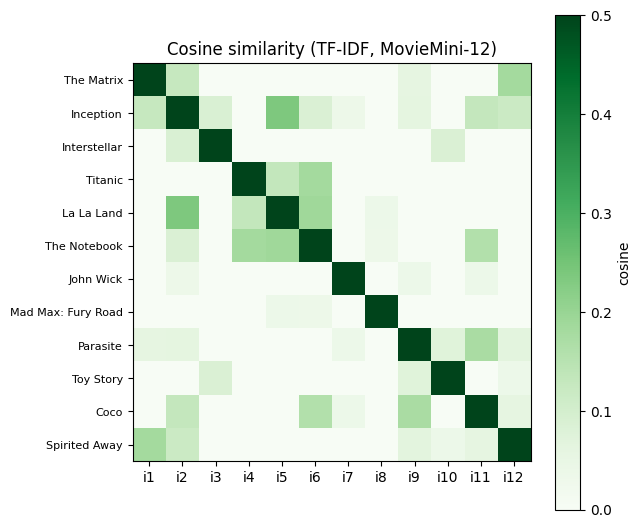

In [30]:
# ---------- ตารางที่ 3.28 · คู่ที่คล้ายที่สุดหกอันดับแรกของทั้งคลัง ----------
# เทคนิค: หลัง L2 แล้ว โคไซน์ = ผลคูณจุด จึงคำนวณทั้งเมทริกซ์ได้ในบรรทัดเดียว (X·Xᵀ)
# วิธีอ่านผล: คอลัมน์ "คำร่วมที่ทำให้คล้าย" มาจาก explain_terms — เป็นการตรวจว่าโมเดล "คล้ายเพราะอะไร"
#             ซึ่งสำคัญกว่าตัวเลขโคไซน์เอง
S = cosine_matrix(X)
S_df = pd.DataFrame(S, index=ITEM_IDS, columns=ITEM_IDS)
show_df(S_df, "เมทริกซ์ความคล้ายโคไซน์ทั้งคลัง (TF-IDF)", fmt="{:.3f}")
Sx = S.copy(); np.fill_diagonal(Sx, 0.0)
pairs = sorted([(Sx[a, b], a, b) for a in range(N_ITEMS) for b in range(a + 1, N_ITEMS)], reverse=True)[:6]
def shared_terms(a, b, k=3):
    va, vb = np.asarray(X[a].todense()).ravel(), np.asarray(X[b].todense()).ravel()
    contrib = va * vb
    return ", ".join(vec.vocab_[j] for j in np.argsort(-contrib)[:k] if contrib[j] > 0)
BOOK_328 = [("i2", "i5", 0.2349, "ไม่ — คนละแนวโดยสิ้นเชิง"), ("i5", "i6", 0.1886, "ใช่ — Romance ทั้งคู่"),
            ("i1", "i12", 0.1835, "ไม่ — บังเอิญใช้คำเดียวกัน"), ("i4", "i6", 0.1819, "ใช่ — Romance ทั้งคู่"),
            ("i9", "i11", 0.1730, "บางส่วน"), ("i6", "i11", 0.1590, "บางส่วน")]
show_df(pd.DataFrame([{"อันดับ": r + 1, "คู่ภาพยนตร์": f"{TITLE[ITEM_IDS[a]]} – {TITLE[ITEM_IDS[b]]}",
                       "โคไซน์": round(s, 4), "คำร่วมที่ทำให้คล้าย": shared_terms(a, b),
                       "สมเหตุสมผลหรือไม่ (ตำรา)": BOOK_328[r][3]} for r, (s, a, b) in enumerate(pairs)]),
        "ตารางที่ 3.28 คู่ที่คล้ายที่สุดหกอันดับแรก พร้อมคำที่ทำให้คล้าย", fmt="{}")
book_many("ตารางที่ 3.28 · โคไซน์ของหกคู่แรก",
          [(f"{BOOK_328[r][0]}–{BOOK_328[r][1]}", pairs[r][0], BOOK_328[r][2]) for r in range(6)])
book("ตารางที่ 3.28 · ลำดับคู่",
     " > ".join(f"{ITEM_IDS[a]}-{ITEM_IDS[b]}" for _, a, b in pairs),
     " > ".join(f"{a}-{b}" for a, b, _, _ in BOOK_328))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap="Greens", vmin=0, vmax=0.5)
ax.set_xticks(range(N_ITEMS)); ax.set_yticks(range(N_ITEMS)); ax.set_xticklabels(ITEM_IDS)
ax.set_yticklabels([TITLE[i] for i in ITEM_IDS], fontsize=8)
plt.colorbar(im, ax=ax, label="cosine"); ax.set_title("Cosine similarity (TF-IDF, MovieMini-12)"); plt.tight_layout(); plt.show()
# ข้อสังเกต (ประโยคสำคัญของหัวข้อ 3.7): อันดับ 1 คือ Inception–La La Land ที่ "ไม่สมเหตุสมผล"
#            คำว่า dream ในสองเรื่องคือคนละความหมาย (ความฝันขณะหลับ กับ ความใฝ่ฝันในอาชีพ)
#            ถุงคำแยกไม่ออก — ต้องรอปริภูมิความหมายใน Part 8 (ตารางที่ 3.53)

## Part 4 · โปรไฟล์ผู้ใช้ (หัวข้อ 3.8) — ผู้ใช้ตัวอย่างหลัก u1

**หลักการข้อเดียว** — โปรไฟล์ต้องอยู่ใน *ปริภูมิเดียวกับรายการ* จะเป็นแนว 9 มิติ หรือคำ 203 มิติก็ได้
แต่ต้องเป็นปริภูมิเดียวกัน มิฉะนั้นผลคูณจุดไม่มีความหมาย

In [31]:
u1 = {IDX[i]: r for i, r in RATINGS["u1"].items()}     # {0:5, 1:5, 2:4, 3:1, 5:1}
liked = [i for i, r in u1.items() if r >= 4]; disliked = [i for i, r in u1.items() if r <= 2]
print("u1 ชอบ:", [title_of(i) for i in liked], "· ไม่ชอบ:", [title_of(i) for i in disliked])

# ---------- ตารางที่ 3.29 · การคำนวณโปรไฟล์ของ u1 ในปริภูมิ TF-IDF ----------
# เทคนิค (centroid, หัวข้อ 3.8.2): โปรไฟล์ = ค่าเฉลี่ยของเวกเตอร์รายการที่ "ชอบ" แล้วปรับ L2
#         การเฉลี่ยทำให้คำที่ปรากฏในหลายเรื่องที่ชอบได้น้ำหนักสูง ส่วนคำที่มาจากเรื่องเดียวถูกหารด้วยจำนวนเรื่อง
# วิธีอ่านผล: คอลัมน์ "ค่าเฉลี่ย" คือก่อนปรับ L2 · คอลัมน์ "โปรไฟล์" คือหลังปรับ (หารด้วยนอร์ม 0.6173)
#             reality ได้อันดับ 1 เพราะปรากฏทั้งใน i1 (0.4123) และ i2 (0.1726)
p_tfidf = build_profile(X, u1, "centroid")
c_tfidf = to_dense_row(X[liked].mean(axis=0))
norm_c = float(np.linalg.norm(c_tfidf))
rows = []
for t in ["reality", "dream", "world", "time", "space", "machine", "lost"]:
    j = vec.idx_[t]
    rows.append({"มิติ (คำ)": t, "i1 The Matrix": round(float(X[IDX['i1'], j]), 4), "i2 Inception": round(float(X[IDX['i2'], j]), 4),
                 "i3 Interstellar": round(float(X[IDX['i3'], j]), 4), "ค่าเฉลี่ย": round(float(c_tfidf[j]), 4),
                 "โปรไฟล์ (หลัง L2)": round(float(p_tfidf[j]), 4)})
show_df(pd.DataFrame(rows), f"ตารางที่ 3.29 การคำนวณโปรไฟล์ของ u1 ในปริภูมิ TF-IDF (นอร์มของค่าเฉลี่ย = {norm_c:.4f})", fmt="{}")
book_many("ตารางที่ 3.29 · โปรไฟล์ของ u1", [
    ("reality เฉลี่ย", rows[0]["ค่าเฉลี่ย"], 0.1950), ("reality โปรไฟล์", rows[0]["โปรไฟล์ (หลัง L2)"], 0.3159),
    ("dream โปรไฟล์", rows[1]["โปรไฟล์ (หลัง L2)"], 0.3096), ("world โปรไฟล์", rows[2]["โปรไฟล์ (หลัง L2)"], 0.2790),
    ("time โปรไฟล์", rows[3]["โปรไฟล์ (หลัง L2)"], 0.2765), ("space โปรไฟล์", rows[4]["โปรไฟล์ (หลัง L2)"], 0.2369),
    ("machine โปรไฟล์", rows[5]["โปรไฟล์ (หลัง L2)"], 0.2006), ("lost โปรไฟล์", rows[6]["โปรไฟล์ (หลัง L2)"], 0.1848)])
print("จำนวนมิติที่ไม่เป็นศูนย์ในโปรไฟล์:", int((p_tfidf > 0).sum()), "จาก", X.shape[1],
      "← ตำราระบุ 57 มิติ (คำจาก i1+i2+i3)")
book("ตารางที่ 3.29 · จำนวนมิติที่ไม่เป็นศูนย์", int((p_tfidf > 0).sum()), 57)

u1 ชอบ: ['i1 The Matrix', 'i2 Inception', 'i3 Interstellar'] · ไม่ชอบ: ['i4 Titanic', 'i6 The Notebook']


,มิติ (คำ),i1 The Matrix,i2 Inception,i3 Interstellar,ค่าเฉลี่ย,โปรไฟล์ (หลัง L2)
0,reality,0.4123,0.1726,0.0,0.195,0.3159
1,dream,0.0,0.5734,0.0,0.1911,0.3096
2,world,0.3642,0.1525,0.0,0.1722,0.279
3,time,0.0,0.1726,0.3394,0.1707,0.2765
4,space,0.0,0.0,0.4386,0.1462,0.2369
5,machine,0.3715,0.0,0.0,0.1238,0.2006
6,lost,0.0,0.1726,0.1697,0.1141,0.1848


  ✓ ตารางที่ 3.29 · โปรไฟล์ของ u1: ตรง 8/8 ค่า
จำนวนมิติที่ไม่เป็นศูนย์ในโปรไฟล์: 57 จาก 203 ← ตำราระบุ 57 มิติ (คำจาก i1+i2+i3)
  ✓ ตารางที่ 3.29 · จำนวนมิติที่ไม่เป็นศูนย์: ได้ 57.0000 · ตำรา 57.0000


In [32]:
# ---------- ตารางที่ 3.31 · โปรไฟล์ถ่วงคะแนนของ u1 ในปริภูมิแนว ----------
# เทคนิค (หัวข้อ 3.8.4): ใช้ทั้งคะแนนบวกและลบ โดยถ่วงด้วย (r − 3) → 5 ให้ +2 · 4 ให้ +1 · 1 ให้ −2 · 3 ให้ 0
#         แล้วหารด้วย Σ|r − 3| = 9 เพื่อให้ค่าอยู่ในช่วงเทียบกันได้
# วิธีอ่านผล: Romance ติดลบ −0.4444 เพราะ Titanic และ The Notebook ได้คะแนน 1 ทั้งคู่ — "หลักฐานเชิงลบ"
#             ปรากฏเป็นตัวเลขแล้ว ซึ่ง centroid (ที่ใช้เฉพาะรายการที่ชอบ) มองไม่เห็นเลย
w_genre = build_profile(G, u1, "weighted", clip_negative=False, normalize=False)
detail = pd.DataFrame({f"{ITEM_IDS[i]} ({u1[i] - 3:+d})": G[i] * (u1[i] - 3) for i in sorted(u1)}, index=GENRES)
detail["ผลรวมถ่วงน้ำหนัก"] = detail.sum(axis=1)
detail["หาร 9"] = w_genre
show_df(detail.loc[["Action", "Drama", "Romance", "Sci-Fi", "Thriller"]],
        "ตารางที่ 3.31 โปรไฟล์ของ u1 ที่ถ่วงน้ำหนักด้วยคะแนน (ปริภูมิแนวภาพยนตร์)", fmt="{:.4f}")
book_many("ตารางที่ 3.31 · โปรไฟล์ถ่วงคะแนน (หาร 9)", [
    ("Action", w_genre[GENRES.index("Action")], 0.2222), ("Drama", w_genre[GENRES.index("Drama")], -0.3333),
    ("Romance", w_genre[GENRES.index("Romance")], -0.4444), ("Sci-Fi", w_genre[GENRES.index("Sci-Fi")], 0.5556),
    ("Thriller", w_genre[GENRES.index("Thriller")], 0.2222)])
p_genre = build_profile(Gn, u1, "centroid")     # โปรไฟล์แนวแบบ centroid (ใช้ต่อใน Part 5)
p_weighted = build_profile(X, u1, "weighted")

,i1 (+2),i2 (+2),i3 (+1),i4 (-2),i6 (-2),ผลรวมถ่วงน้ำหนัก,หาร 9
Action,2.0000,0.0000,0.0000,-0.0000,-0.0000,2.0000,0.2222
Drama,0.0000,0.0000,1.0000,-2.0000,-2.0000,-3.0000,-0.3333
Romance,0.0000,0.0000,0.0000,-2.0000,-2.0000,-4.0000,-0.4444
Sci-Fi,2.0000,2.0000,1.0000,-0.0000,-0.0000,5.0000,0.5556
Thriller,0.0000,2.0000,0.0000,-0.0000,-0.0000,2.0000,0.2222


  ✓ ตารางที่ 3.31 · โปรไฟล์ถ่วงคะแนน (หาร 9): ตรง 5/5 ค่า


In [33]:
# ---------- ตารางที่ 3.32 · บทบาทของพารามิเตอร์ Rocchio (ตารางอ้างอิง) ----------
show_df(pd.DataFrame([
    ["α", "น้ำหนักของข้อคำถามเดิม (ถ้ามี)", "0 – 1", "ระบบค้นหาที่มีคำค้นชัดเจน ใช้ α สูง"],
    ["β", "น้ำหนักของรายการที่ชอบ", "0.6 – 1.0", "ต้องมากกว่า γ เสมอ มิฉะนั้นโปรไฟล์กลายเป็น 'สิ่งที่ไม่ชอบ'"],
    ["γ", "น้ำหนักของรายการที่ไม่ชอบ", "0.1 – 0.3", "ใหญ่เกินไปทำให้เวกเตอร์เป็นศูนย์หลังตัดค่าลบ"]],
    columns=["พารามิเตอร์", "ความหมาย", "ช่วงที่แนะนำ", "ข้อควรระวัง"]),
        "ตารางที่ 3.32 บทบาทของพารามิเตอร์ทั้งสามตัวของ Rocchio", fmt="{}")

,พารามิเตอร์,ความหมาย,ช่วงที่แนะนำ,ข้อควรระวัง
0,α,น้ำหนักของข้อคำถามเดิม (ถ้ามี),0 – 1,ระบบค้นหาที่มีคำค้นชัดเจน ใช้ α สูง
1,β,น้ำหนักของรายการที่ชอบ,0.6 – 1.0,ต้องมากกว่า γ เสมอ มิฉะนั้นโปรไฟล์กลายเป็น 'สิ่งที่ไม่ชอบ'
2,γ,น้ำหนักของรายการที่ไม่ชอบ,0.1 – 0.3,ใหญ่เกินไปทำให้เวกเตอร์เป็นศูนย์หลังตัดค่าลบ


In [34]:
# ---------- ตารางที่ 3.33 · มิติที่ Rocchio เปลี่ยนมากที่สุด (β = 0.8, γ = 0.2) ----------
# เทคนิค (หัวข้อ 3.8.5): p = β·mean(ชอบ) − γ·mean(ไม่ชอบ) แล้ว "ตัดค่าติดลบเป็นศูนย์" ก่อนปรับ L2
#         การตัดค่าลบมีเหตุผล: ในปริภูมิถุงคำ ค่าติดลบแปลว่า "ต่อต้านคำนี้" ซึ่งทำให้เอกสารที่ไม่มีคำนั้นเลย
#         ได้เปรียบอย่างไม่ตั้งใจ (ดูหัวข้อ 3.8.6)
# วิธีอ่านผล: love และ woman ถูกผลักลงติดลบ แล้วถูกตัดเป็น 0 → คำจาก Titanic/The Notebook หายจากโปรไฟล์
#             ส่วน memory เหลือ 0.0184 (บวกเล็กน้อย) เพราะปรากฏทั้งฝั่งชอบ (i2) และฝั่งไม่ชอบ (i6)
mean_like = to_dense_row(X[liked].mean(axis=0))
mean_dis = to_dense_row(X[disliked].mean(axis=0))
roc_raw = build_profile(X, u1, "rocchio", beta=0.8, gamma=0.2, clip_negative=False, normalize=False)
roc_clip = np.maximum(roc_raw, 0.0)
rows = []
for t in ["love", "woman", "class", "memory", "reality", "dream"]:
    j = vec.idx_[t]
    rows.append({"คำ": t, "ค่าเฉลี่ยฝั่งชอบ": round(float(mean_like[j]), 4), "ค่าเฉลี่ยฝั่งไม่ชอบ": round(float(mean_dis[j]), 4),
                 "0.8·ชอบ − 0.2·ไม่ชอบ": round(float(roc_raw[j]), 4), "หลังตัดค่าติดลบ": round(float(roc_clip[j]), 4)})
show_df(pd.DataFrame(rows), "ตารางที่ 3.33 มิติที่ร็อกคีโยเปลี่ยนมากที่สุดในปริภูมิ TF-IDF ของ u1 (β = 0.8, γ = 0.2)", fmt="{}")
book_many("ตารางที่ 3.33 · ค่าของ Rocchio", [
    ("love ฝั่งไม่ชอบ", rows[0]["ค่าเฉลี่ยฝั่งไม่ชอบ"], 0.3935), ("love หลังคำนวณ", rows[0]["0.8·ชอบ − 0.2·ไม่ชอบ"], -0.0787),
    ("woman ฝั่งไม่ชอบ", rows[1]["ค่าเฉลี่ยฝั่งไม่ชอบ"], 0.1790), ("memory ฝั่งชอบ", rows[3]["ค่าเฉลี่ยฝั่งชอบ"], 0.0508),
    ("reality หลังคำนวณ", rows[4]["0.8·ชอบ − 0.2·ไม่ชอบ"], 0.1560),
    ("dream หลังคำนวณ", rows[5]["0.8·ชอบ − 0.2·ไม่ชอบ"], 0.1529)])
# ---- ข้อสังเกตจากการทวนสอบ: แถว memory ของตารางที่ 3.33 ไม่สอดคล้องกับค่าอื่นในตารางเดียวกัน ----
# ตำราระบุค่าเฉลี่ยฝั่งไม่ชอบของ memory = 0.1112 ซึ่งหมายความว่า memory ใน i6 มีน้ำหนัก 0.2224
# แต่เมื่อคำนวณจากเรื่องย่อฉบับเต็มของ i6 (ตารางที่ 3.2) คำว่า memory ปรากฏ 3 ครั้ง → น้ำหนัก 0.3997
# และค่าเฉลี่ยฝั่งไม่ชอบ = 0.1998 (ขณะที่แถว love/woman ในตารางเดียวกันตรงกับเราทุกตำแหน่ง)
# นี่คือตัวอย่างจริงของ "อาการ" ในตารางที่ 3.68: เมื่อค่าหนึ่งไม่สอดคล้องกับค่าอื่นที่คำนวณด้วยสูตรเดียวกัน
# ให้ย้อนไปตรวจ *ข้อความต้นทาง* ก่อนเสมอ (ที่นี่คือจำนวนครั้งที่คำปรากฏ)
mem_j = vec.idx_["memory"]
print(f"ตรวจย้อนกลับ: memory ปรากฏใน i6 จำนวน {docs_clean[IDX['i6']].count('memory')} ครั้ง → น้ำหนัก {float(X[IDX['i6'], mem_j]):.4f} "
      f"· ค่าเฉลี่ยฝั่งไม่ชอบ = {float(mean_dis[mem_j]):.4f}")
BOOK.append({"รายการที่ทวนสอบ": "ตารางที่ 3.33 · memory ฝั่งไม่ชอบ", "ที่คำนวณได้": f"{float(mean_dis[mem_j]):.4f}", "ในตำรา": "0.1112",
             "ตรง": "≈", "หมายเหตุ": "ตำราน่าจะนับ memory ใน i6 เพียง 2 ครั้ง (ตามช่วงข้อความสาธิตตารางที่ 3.7) แต่เรื่องย่อฉบับเต็มมี 3 ครั้ง — ค่าอื่นในตารางเดียวกันตรงทั้งหมด"})
p_rocchio = build_profile(X, u1, "rocchio", beta=0.8, gamma=0.2)     # ตัดลบแล้ว L2 (ใช้ต่อใน Part 9)
print("จำนวนมิติที่ถูกตัดเป็นศูนย์โดย Rocchio:", int((roc_raw < 0).sum()), "มิติ")

,คำ,ค่าเฉลี่ยฝั่งชอบ,ค่าเฉลี่ยฝั่งไม่ชอบ,0.8·ชอบ − 0.2·ไม่ชอบ,หลังตัดค่าติดลบ
0,love,0.0,0.3935,-0.0787,0.0
1,woman,0.0,0.179,-0.0358,0.0
2,class,0.0,0.1065,-0.0213,0.0
3,memory,0.0508,0.1998,0.0007,0.0007
4,reality,0.195,0.0,0.156,0.156
5,dream,0.1911,0.0,0.1529,0.1529


  ✓ ตารางที่ 3.33 · ค่าของ Rocchio: ตรง 6/6 ค่า
ตรวจย้อนกลับ: memory ปรากฏใน i6 จำนวน 3 ครั้ง → น้ำหนัก 0.3997 · ค่าเฉลี่ยฝั่งไม่ชอบ = 0.1998
จำนวนมิติที่ถูกตัดเป็นศูนย์โดย Rocchio: 35 มิติ


## Part 5 · คะแนนจับคู่ · อธิบายผล · Item-kNN · Top-K · Leave-One-Out (หัวข้อ 3.9–3.10)

In [35]:
# ---------- ตารางที่ 3.34 · คะแนนจับคู่ของ u1 ครบทั้ง 12 เรื่อง ----------
# เทคนิค: คะแนนจับคู่ = ผลคูณจุดระหว่างโปรไฟล์กับเวกเตอร์รายการ (= โคไซน์ เพราะทั้งคู่ผ่าน L2 แล้ว)
# วิธีอ่านผล: สามอันดับแรกคือเรื่องที่ u1 *เคยดูแล้ว* (i2 0.6559 · i1 0.6084 · i3 0.5875) ซึ่งเป็นสัญญาณว่า
#             โปรไฟล์ทำงานถูกต้อง (มันควรคล้ายกับสิ่งที่ผู้ใช้ชอบที่สุด) แต่ **ต้องกรองออกก่อนแนะนำ**
# ข้อสังเกตสำคัญสองข้อ:
#   (1) i6 The Notebook ที่ u1 ให้ 1 คะแนน ยังได้ 0.0456 ไม่ใช่ 0 — คะแนนจับคู่ไม่ได้บอก "ชอบ/ไม่ชอบ"
#   (2) i8 Mad Max ได้ 0.0000 ทั้งที่แนวตรงที่สุด (Action+Sci-Fi) — "ไม่มีคำร่วม ≠ ไม่เกี่ยวข้อง"
s_tfidf = match_scores(X, p_tfidf)
order34 = np.argsort(-s_tfidf)
status = lambda k: f"เคยให้คะแนน ({int(u1[k])})" if k in u1 else "รายการที่มีโอกาสได้รับเลือก"
show_df(pd.DataFrame([{"อันดับ": r + 1, "รายการ": title_of(k), "คะแนนจับคู่": round(float(s_tfidf[k]), 4),
                       "สถานะ": status(k), "คำร่วมกับโปรไฟล์": ", ".join(t for t, *_ in explain_terms(vec, p_tfidf, X[k], 4)) or "—"}
                      for r, k in enumerate(order34)]),
        "ตารางที่ 3.34 คะแนนจับคู่ในปริภูมิ TF-IDF เรียงจากมากไปน้อย", fmt="{}")
book_many("ตารางที่ 3.34 · คะแนนจับคู่ของ u1", [
    ("i2", s_tfidf[IDX["i2"]], 0.6559), ("i1", s_tfidf[IDX["i1"]], 0.6084), ("i3", s_tfidf[IDX["i3"]], 0.5875),
    ("i12", s_tfidf[IDX["i12"]], 0.1620), ("i5", s_tfidf[IDX["i5"]], 0.1268), ("i11", s_tfidf[IDX["i11"]], 0.0698),
    ("i9", s_tfidf[IDX["i9"]], 0.0654), ("i6", s_tfidf[IDX["i6"]], 0.0456), ("i10", s_tfidf[IDX["i10"]], 0.0455),
    ("i7", s_tfidf[IDX["i7"]], 0.0183), ("i4", s_tfidf[IDX["i4"]], 0.0000), ("i8", s_tfidf[IDX["i8"]], 0.0000)])

,อันดับ,รายการ,คะแนนจับคู่,สถานะ,คำร่วมกับโปรไฟล์
0,1,i2 Inception,0.6559,เคยให้คะแนน (5),"dream, reality, time, world"
1,2,i1 The Matrix,0.6084,เคยให้คะแนน (5),"reality, world, machine, armies"
2,3,i3 Interstellar,0.5875,เคยให้คะแนน (4),"space, time, lost, black"
3,4,i12 Spirited Away,0.162,รายการที่มีโอกาสได้รับเลือก,"world, steals, free, family"
4,5,i5 La La Land,0.1268,รายการที่มีโอกาสได้รับเลือก,"dream, shared"
5,6,i11 Coco,0.0698,รายการที่มีโอกาสได้รับเลือก,"family, memory, fading"
6,7,i9 Parasite,0.0654,รายการที่มีโอกาสได้รับเลือก,"family, beneath, hidden"
7,8,i6 The Notebook,0.0456,เคยให้คะแนน (1),"memory, fading"
8,9,i10 Toy Story,0.0455,รายการที่มีโอกาสได้รับเลือก,space
9,10,i7 John Wick,0.0183,รายการที่มีโอกาสได้รับเลือก,rival


  ✓ ตารางที่ 3.34 · คะแนนจับคู่ของ u1: ตรง 12/12 ค่า


In [36]:
# ---------- ตารางที่ 3.35 · ส่วนร่วมรายคำของคะแนน (คำอธิบายที่ได้มาฟรี — หัวข้อ 3.9.4) ----------
# เทคนิค: คะแนน = Σ p_j · v_j ดังนั้น "ส่วนร่วมของคำ j" คือ p_j · v_j ตรง ๆ — แยกส่วนได้เพราะเป็นผลคูณจุด
#         นี่คือข้อได้เปรียบเชิงโครงสร้างของระบบอิงเนื้อหาที่ระบบกรองร่วมไม่มี (อธิบายผลได้ทุกคะแนน)
# วิธีอ่านผล: Spirited Away ได้คะแนนสูงสุดเพราะคำว่า world เพียงคำเดียว (72.8% ของคะแนน) ไม่ใช่เพราะเป็น Sci-Fi
#             → นี่คือแรงจูงใจโดยตรงของ BM25 ใน Part 7 (ต้องทำให้การซ้ำคำอิ่มตัว)
rows = []
for iid in ["i12", "i5", "i11", "i9"]:
    k = IDX[iid]
    for n, (t, pj, vj, contrib) in enumerate(explain_terms(vec, p_tfidf, X[k], 4)):
        rows.append({"รายการ": f"{title_of(k)} ({s_tfidf[k]:.4f})" if n == 0 else "",     # แสดงชื่อเฉพาะแถวแรกของแต่ละกลุ่ม
                     "คำ": t, "p (โปรไฟล์)": pj, "v (รายการ)": vj, "ส่วนร่วม": contrib,
                     "สัดส่วนของคะแนน": f"{contrib / s_tfidf[k]:.1%}"})
show_df(pd.DataFrame(rows).set_index("รายการ"), "ตารางที่ 3.35 ส่วนร่วมรายคำของคะแนนจับคู่ สำหรับรายการที่มีโอกาสได้รับเลือกสี่อันดับแรก", fmt="{}")
ex12 = dict((t, c) for t, _, _, c in explain_terms(vec, p_tfidf, X[IDX["i12"]], 4))
book_many("ตารางที่ 3.35 · ส่วนร่วมของคำใน i12 Spirited Away", [
    ("world", ex12["world"], 0.1180), ("steals", ex12["steals"], 0.0173), ("free", ex12["free"], 0.0159), ("family", ex12["family"], 0.0108)])
book("ตารางที่ 3.35 · สัดส่วนของ world ใน i12", ex12["world"] / s_tfidf[IDX["i12"]] * 100, 72.8, tol=0.2, note="หน่วยเปอร์เซ็นต์")

,คำ,p (โปรไฟล์),v (รายการ),ส่วนร่วม,สัดส่วนของคะแนน
รายการ,,,,,
i12 Spirited Away (0.1620),world,0.279,0.4227,0.118,72.8%
,steals,0.0932,0.1851,0.0173,10.7%
,free,0.0861,0.1851,0.0159,9.8%
,family,0.0739,0.1468,0.0108,6.7%
i5 La La Land (0.1268),dream,0.3096,0.3561,0.1103,87.0%
,shared,0.0932,0.178,0.0166,13.1%
i11 Coco (0.0698),family,0.0739,0.3868,0.0286,41.0%
,memory,0.0823,0.3334,0.0275,39.4%
,fading,0.0823,0.1667,0.0137,19.6%


  ✓ ตารางที่ 3.35 · ส่วนร่วมของคำใน i12 Spirited Away: ตรง 4/4 ค่า
  ✓ ตารางที่ 3.35 · สัดส่วนของ world ใน i12: ได้ 72.8386 · ตำรา 72.8000  — หน่วยเปอร์เซ็นต์


In [37]:
# ---------- ตารางที่ 3.36 · Item-kNN: อีกวิธีให้คะแนนโดยไม่ต้องสร้างโปรไฟล์ (หัวข้อ 3.9.5) ----------
# เทคนิค: เทียบผู้สมัครกับรายการที่ชอบ "ทีละรายการ" แล้วรวมด้วย mean หรือ max
#         mean ≡ โปรไฟล์ centroid เมื่อทุกแถวผ่าน L2 (พิสูจน์ได้ทางพีชคณิต) แต่ max ให้พฤติกรรมต่างออกไป
# วิธีอ่านผล: คอลัมน์ "เฉลี่ย" ของ i12 = 0.1000 ขณะที่ "อิงโปรไฟล์" = 0.1620 — ไม่เท่ากันเพราะโปรไฟล์ถูก L2
#             อีกครั้งหลังเฉลี่ย (หารด้วย 0.6173) ลำดับจึงเหมือนกันแต่สเกลต่างกัน
# ข้อสังเกต: max ไวต่อรายการเดียว — La La Land ขึ้นเป็นอันดับ 1 ทันทีเพราะคล้าย Inception เรื่องเดียว 0.2349
#            ในระบบจริง max เหมาะกับผู้ใช้ที่มีรสนิยมหลายด้าน (ไม่ควรเฉลี่ยรวมกัน)
cand_u1 = [k for k in range(N_ITEMS) if k not in u1]
s_knn_mean = item_knn_scores(S, liked, "mean"); s_knn_max = item_knn_scores(S, liked, "max")
show_df(pd.DataFrame([{"รายการ": title_of(k), "cos กับ i1": round(float(S[k, IDX['i1']]), 4),
                       "cos กับ i2": round(float(S[k, IDX['i2']]), 4), "cos กับ i3": round(float(S[k, IDX['i3']]), 4),
                       "เฉลี่ย": round(float(s_knn_mean[k]), 4), "สูงสุด": round(float(s_knn_max[k]), 4),
                       "อิงโปรไฟล์": round(float(s_tfidf[k]), 4)} for k in sorted(cand_u1, key=lambda k: -s_knn_mean[k])]),
        "ตารางที่ 3.36 คะแนนแบบ Item-kNN ของรายการที่มีโอกาสได้รับเลือกทั้งเจ็ดเรื่องของ u1", fmt="{}")
book_many("ตารางที่ 3.36 · Item-kNN ของ u1", [
    ("i12 เฉลี่ย", s_knn_mean[IDX["i12"]], 0.1000), ("i12 สูงสุด", s_knn_max[IDX["i12"]], 0.1835),
    ("i5 เฉลี่ย", s_knn_mean[IDX["i5"]], 0.0783), ("i5 สูงสุด", s_knn_max[IDX["i5"]], 0.2349),
    ("i11 เฉลี่ย", s_knn_mean[IDX["i11"]], 0.0431), ("i9 เฉลี่ย", s_knn_mean[IDX["i9"]], 0.0404),
    ("i10 เฉลี่ย", s_knn_mean[IDX["i10"]], 0.0281), ("i7 เฉลี่ย", s_knn_mean[IDX["i7"]], 0.0113)])

,รายการ,cos กับ i1,cos กับ i2,cos กับ i3,เฉลี่ย,สูงสุด,อิงโปรไฟล์
0,i12 Spirited Away,0.1835,0.1165,0.0,0.1,0.1835,0.162
1,i5 La La Land,0.0,0.2349,0.0,0.0783,0.2349,0.1268
2,i11 Coco,0.0,0.1292,0.0,0.0431,0.1292,0.0698
3,i9 Parasite,0.06,0.0612,0.0,0.0404,0.0612,0.0654
4,i10 Toy Story,0.0,0.0,0.0843,0.0281,0.0843,0.0455
5,i7 John Wick,0.0,0.0338,0.0,0.0113,0.0338,0.0183
6,i8 Mad Max: Fury Road,0.0,0.0,0.0,0.0,0.0,0.0


  ✓ ตารางที่ 3.36 · Item-kNN ของ u1: ตรง 8/8 ค่า


In [38]:
# ---------- ตารางที่ 3.37 · ฟังก์ชันจับคู่ที่ใช้ได้ (ตารางอ้างอิง พร้อมค่าจริงจากสมุดบันทึกนี้) ----------
show_df(pd.DataFrame([
    ["โคไซน์ / ผลคูณจุด", "p·v หลังปรับ L2", "[0, 1]", f"i12 ได้ {s_tfidf[IDX['i12']]:.4f} (ตารางที่ 3.34)", "3.9"],
    ["BM25 กับโปรไฟล์เป็นข้อคำถาม", "ใช้คำเด่นของโปรไฟล์เป็น q", "[0, ∞)", "i5 ได้ 2.3524 (ตารางที่ 3.46)", "3.11"],
    ["ความน่าจะเป็นจากตัวจำแนก", "Naive Bayes / Logistic", "[0, 1]", "ดู Part 8", "3.12"],
    ["โคไซน์เชิงความหมาย", "โคไซน์บนเวกเตอร์ฝัง", "[−1, 1]", "i7–i8 จาก 0.0000 เป็น 0.2951 (ตารางที่ 3.53)", "3.13"]],
    columns=["ฟังก์ชัน", "สูตรหรือแนวคิด", "ช่วงของค่า", "ค่าจริงในสมุดบันทึกนี้", "หัวข้อ"]),
        "ตารางที่ 3.37 ฟังก์ชันจับคู่ระหว่างโปรไฟล์กับรายการที่พบในบทนี้", fmt="{}")
# ข้อสังเกต: ช่วงของค่าต่างกันคือเหตุผลที่ห้ามนำคะแนนจากคนละฟังก์ชันมาบวกกันตรง ๆ (ต้องปรับมาตราหรือใช้ RRF)

,ฟังก์ชัน,สูตรหรือแนวคิด,ช่วงของค่า,ค่าจริงในสมุดบันทึกนี้,หัวข้อ
0,โคไซน์ / ผลคูณจุด,p·v หลังปรับ L2,"[0, 1]",i12 ได้ 0.1620 (ตารางที่ 3.34),3.9
1,BM25 กับโปรไฟล์เป็นข้อคำถาม,ใช้คำเด่นของโปรไฟล์เป็น q,"[0, ∞)",i5 ได้ 2.3524 (ตารางที่ 3.46),3.11
2,ความน่าจะเป็นจากตัวจำแนก,Naive Bayes / Logistic,"[0, 1]",ดู Part 8,3.12
3,โคไซน์เชิงความหมาย,โคไซน์บนเวกเตอร์ฝัง,"[−1, 1]",i7–i8 จาก 0.0000 เป็น 0.2951 (ตารางที่ 3.53),3.13


In [39]:
# ---------- ตารางที่ 3.38 · Top-3 ของ u1 ในสองปริภูมิ ----------
# เทคนิค (ห้าขั้นของหัวข้อ 3.10.1): รวบรวมผู้สมัคร → ให้คะแนน → กรองที่เคยเห็น → เรียงและตัดสินเสมอ → ตัด K
# วิธีอ่านผล: สองปริภูมิให้คำตอบ *คนละชุดโดยสิ้นเชิง* — ปริภูมิคำถูกชักนำด้วยคำซ้ำ (world/dream)
#             ส่วนปริภูมิแนวตรงกับสัญชาตญาณมนุษย์ (Mad Max) แต่มีคะแนนเสมอกันจำนวนมาก
# ข้อสังเกตเรื่องการเสมอ: John Wick กับ Parasite ได้ 0.4082 เท่ากัน ต้องมีกฎตัดสินที่ประกาศไว้ (ที่นี่ใช้รหัสรายการ)
#             ถ้าไม่ประกาศ ลำดับจะขึ้นกับลำดับใน DataFrame ซึ่งเปลี่ยนได้ทุกครั้งที่โหลดข้อมูลใหม่
seen_u1 = set(u1)
s_genre = match_scores(Gn, p_genre)
top_t = top_k(s_tfidf, seen_u1, 3, item_ids=ITEM_IDS)
top_g = top_k(s_genre, seen_u1, 3, item_ids=ITEM_IDS)
show_df(pd.DataFrame({"อันดับ": [1, 2, 3],
                      "ปริภูมิ TF-IDF (203 มิติ)": [title_of(i) for i in top_t], "คะแนน (TF-IDF)": [round(float(s_tfidf[i]), 4) for i in top_t],
                      "ปริภูมิแนว (9 มิติ)": [title_of(i) for i in top_g], "คะแนน (แนว)": [round(float(s_genre[i]), 4) for i in top_g]}),
        "ตารางที่ 3.38 รายการแนะนำ Top-3 ของ u1 จากโปรไฟล์ค่าเฉลี่ยศูนย์กลาง ในสองปริภูมิ", fmt="{}")
book_many("ตารางที่ 3.38 · Top-3 ในสองปริภูมิ", [
    ("TF-IDF อันดับ 1", s_tfidf[top_t[0]], 0.1620), ("TF-IDF อันดับ 2", s_tfidf[top_t[1]], 0.1268),
    ("TF-IDF อันดับ 3", s_tfidf[top_t[2]], 0.0698), ("แนว อันดับ 1", s_genre[top_g[0]], 0.8165),
    ("แนว อันดับ 2", s_genre[top_g[1]], 0.4082), ("แนว อันดับ 3", s_genre[top_g[2]], 0.4082)])
book("ตารางที่ 3.38 · ลำดับใน TF-IDF", " > ".join(ITEM_IDS[i] for i in top_t), "i12 > i5 > i11")
book("ตารางที่ 3.38 · ลำดับในปริภูมิแนว", " > ".join(ITEM_IDS[i] for i in top_g), "i8 > i7 > i9")

,อันดับ,ปริภูมิ TF-IDF (203 มิติ),คะแนน (TF-IDF),ปริภูมิแนว (9 มิติ),คะแนน (แนว)
0,1,i12 Spirited Away,0.162,i8 Mad Max: Fury Road,0.8165
1,2,i5 La La Land,0.1268,i7 John Wick,0.4082
2,3,i11 Coco,0.0698,i9 Parasite,0.4082


  ✓ ตารางที่ 3.38 · Top-3 ในสองปริภูมิ: ตรง 6/6 ค่า
  ✓ ตารางที่ 3.38 · ลำดับใน TF-IDF: ได้ i12 > i5 > i11 · ตำรา i12 > i5 > i11
  ✓ ตารางที่ 3.38 · ลำดับในปริภูมิแนว: ได้ i8 > i7 > i9 · ตำรา i8 > i7 > i9


In [40]:
# ---------- ตารางที่ 3.39 · Leave-One-Out ของ u1 ----------
# เทคนิค: ซ่อนเรื่องที่ชอบทีละเรื่อง สร้างโปรไฟล์จากที่เหลือ แล้วดูว่าเรื่องที่ซ่อนกลับมาอันดับใด
#         นี่คือ "ตัวชี้วัดของบทที่ 2 ตัวแรก" ที่เราคำนวณจริง (HR@K และ MRR) บนผู้ใช้คนเดียว
# วิธีอ่านผล: ซ่อน Inception → กลับมาอันดับ 1 (เพราะ Matrix เหลืออยู่และใช้คำร่วมกันมาก)
#             ซ่อน Interstellar → ได้แค่อันดับ 5 (คำร่วมกับสองเรื่องที่เหลือมีเพียง time, lost)
# ข้อสังเกต: ผลนี้มาจากผู้ใช้คนเดียวและเป้าหมายสามชิ้น จึง **สรุปอะไรไม่ได้** — เป็นการสาธิตกลไกเท่านั้น
rows = []
for hold in liked:
    rest = {i: r for i, r in u1.items() if i != hold}
    seen = set(rest)
    res = {"เรื่องที่ซ่อน": title_of(hold), "โปรไฟล์สร้างจาก": ", ".join(ITEM_IDS[i] for i in rest if rest[i] >= 4)}
    for name, M in [("TF-IDF", X), ("แนว", Gn)]:
        p = build_profile(M, rest, "centroid"); s = match_scores(M, p)
        rank = top_k(s, seen, 12, item_ids=ITEM_IDS)
        pos = rank.index(hold) + 1
        res[f"อันดับ {name}"] = pos
        res[f"คะแนน {name}"] = round(float(s[hold]), 4)
        res[f"เหนือกว่าโดย ({name})"] = ", ".join(ITEM_IDS[i] for i in rank[:pos - 1][:4]) or "—"
    rows.append(res)
loo = pd.DataFrame(rows)
show_df(loo, "ตารางที่ 3.39 การกันออกทีละรายการของ u1: อันดับที่เรื่องที่ซ่อนไว้กลับมา", fmt="{}")
book_many("ตารางที่ 3.39 · อันดับและคะแนนของเรื่องที่ซ่อน", [
    ("อันดับ i1 (TF-IDF)", loo["อันดับ TF-IDF"][0], 3), ("คะแนน i1", loo["คะแนน TF-IDF"][0], 0.0859),
    ("อันดับ i2 (TF-IDF)", loo["อันดับ TF-IDF"][1], 1), ("คะแนน i2", loo["คะแนน TF-IDF"][1], 0.1517),
    ("อันดับ i3 (TF-IDF)", loo["อันดับ TF-IDF"][2], 5), ("คะแนน i3", loo["คะแนน TF-IDF"][2], 0.0585),
    ("คะแนนในปริภูมิแนว (ทุกกรณี)", loo["คะแนน แนว"][0], 0.5774)])
for name in ["TF-IDF", "แนว"]:
    print(f"{name}: HR@3 = {(loo[f'อันดับ {name}'] <= 3).mean():.4f} · MRR = {(1 / loo[f'อันดับ {name}']).mean():.4f}")

,เรื่องที่ซ่อน,โปรไฟล์สร้างจาก,อันดับ TF-IDF,คะแนน TF-IDF,เหนือกว่าโดย (TF-IDF),อันดับ แนว,คะแนน แนว,เหนือกว่าโดย (แนว)
0,i1 The Matrix,"i2, i3",3,0.0859,"i5, i11",1,0.5774,—
1,i2 Inception,"i1, i3",1,0.1517,—,2,0.5774,i8
2,i3 Interstellar,"i1, i2",5,0.0585,"i12, i5, i11, i9",2,0.5774,i8


  ✓ ตารางที่ 3.39 · อันดับและคะแนนของเรื่องที่ซ่อน: ตรง 7/7 ค่า
TF-IDF: HR@3 = 0.6667 · MRR = 0.5111
แนว: HR@3 = 1.0000 · MRR = 0.6667


In [41]:
# ---------- ตารางที่ 3.40 · กระบวนงานทั้งหมดของระบบ (ตารางอ้างอิง + ที่อยู่ในโค้ด) ----------
show_df(pd.DataFrame([
    ["1 เตรียมข้อความ", "preprocess · tokenize", "โทเคนสะอาด", "ตารางที่ 3.3 · 3.7"],
    ["2 สร้างเวกเตอร์รายการ", "TextVectorizer.fit_transform", "เมทริกซ์ 12 × 203", "ตารางที่ 3.27 · 3.28"],
    ["3 สร้างโปรไฟล์ผู้ใช้", "build_profile", "เวกเตอร์ 203 มิติ", "ตารางที่ 3.29 · 3.31 · 3.33"],
    ["4 ให้คะแนนผู้สมัคร", "match_scores / BM25 / ตัวจำแนก", "คะแนนต่อรายการ", "ตารางที่ 3.34 · 3.46"],
    ["5 กรองที่เคยเห็น", "top_k(seen=…)", "ผู้สมัครที่ถูกต้อง", "ตารางที่ 3.38"],
    ["6 จัดอันดับและตัดสินเสมอ", "np.lexsort ในโค้ด top_k", "ลำดับที่ทำซ้ำได้", "ตารางที่ 3.38"],
    ["7 จัดอันดับซ้ำเพื่อความหลากหลาย", "mmr_rerank", "รายการที่ไม่ซ้ำแนว", "ตัวอย่าง 3.9 (Part 6)"],
    ["8 อธิบายผล", "explain_terms", "เหตุผลรายคำ", "ตารางที่ 3.35"]],
    columns=["ขั้น", "ฟังก์ชันในโค้ดนี้", "ผลลัพธ์", "ตารางที่เกี่ยวข้อง"]),
        "ตารางที่ 3.40 กระบวนงานทั้งหมดของระบบแนะนำอิงเนื้อหาจากข้อความ", fmt="{}")

,ขั้น,ฟังก์ชันในโค้ดนี้,ผลลัพธ์,ตารางที่เกี่ยวข้อง
0,1 เตรียมข้อความ,preprocess · tokenize,โทเคนสะอาด,ตารางที่ 3.3 · 3.7
1,2 สร้างเวกเตอร์รายการ,TextVectorizer.fit_transform,เมทริกซ์ 12 × 203,ตารางที่ 3.27 · 3.28
2,3 สร้างโปรไฟล์ผู้ใช้,build_profile,เวกเตอร์ 203 มิติ,ตารางที่ 3.29 · 3.31 · 3.33
3,4 ให้คะแนนผู้สมัคร,match_scores / BM25 / ตัวจำแนก,คะแนนต่อรายการ,ตารางที่ 3.34 · 3.46
4,5 กรองที่เคยเห็น,top_k(seen=…),ผู้สมัครที่ถูกต้อง,ตารางที่ 3.38
5,6 จัดอันดับและตัดสินเสมอ,np.lexsort ในโค้ด top_k,ลำดับที่ทำซ้ำได้,ตารางที่ 3.38
6,7 จัดอันดับซ้ำเพื่อความหลากหลาย,mmr_rerank,รายการที่ไม่ซ้ำแนว,ตัวอย่าง 3.9 (Part 6)
7,8 อธิบายผล,explain_terms,เหตุผลรายคำ,ตารางที่ 3.35


## Part 6 · MMR: ความเกี่ยวข้องแลกกับความหลากหลาย (หัวข้อ 3.10.5)

**เทคนิค** — MMR เลือกทีละรายการแบบละโมบ: `argmax λ·rel(i) − (1−λ)·max_{j∈เลือกแล้ว} sim(i,j)`
λ = 1 คือเรียงตามคะแนนล้วน · λ → 0 คือเน้นไม่ให้ซ้ำกันเอง

**ข้อสังเกตที่ตำราเน้น** — MMR ไม่ใช่การ "ปรับปรุง" แต่เป็น **การแลกเปลี่ยน** ที่ต้องประกาศ guardrail
ไว้ก่อนเลือก λ (เช่น "ยอมให้ nDCG ลดได้ไม่เกิน 5%") มิฉะนั้นจะกลายเป็นการเลือกตัวเลขที่ถูกใจภายหลัง

In [42]:
# ---------- ตัวอย่างการคำนวณ 3.9 · ผู้สมัคร 6 รายการพร้อมเมทริกซ์ความคล้ายที่กำหนดให้ ----------
# วิธีอ่านผล: คอลัมน์ "คะแนนรวม" ลดลงเมื่อ λ ลด ส่วน ILD เพิ่มขึ้น — เห็นเส้นแลกเปลี่ยนเป็นตัวเลขชัดเจน
cand = ["i8", "i1", "i2", "i7", "i9", "i11"]
rel6 = np.array([0.92, 0.88, 0.84, 0.80, 0.62, 0.45])
S6 = np.array([[1, 1, .5, .5, 0, 0], [1, 1, .5, .5, 0, 0], [.5, .5, 1, .5, .5, 0],
               [.5, .5, .5, 1, .5, 0], [0, 0, .5, .5, 1, 0], [0, 0, 0, 0, 0, 1]], float)
def ild_from_S(sel, Sm):
    """ILD ของรายการที่เลือก = ค่าเฉลี่ยของ (1 − ความคล้าย) ทุกคู่ในรายการ"""
    return float(np.mean([1 - Sm[a, b] for x, a in enumerate(sel) for b in sel[x + 1:]]))
rows = []
for lam in [1.0, 0.9, 0.7, 0.5, 0.3, 0.0]:
    sel = mmr_rerank(rel6, S6, K=4, lam=lam, pool=6, normalize=False)   # ใช้คะแนนดิบตามตัวอย่างในตำรา
    rows.append({"λ": lam, "รายการที่เลือก": ", ".join(cand[i] for i in sel),
                 "คะแนนรวม": round(float(rel6[sel].sum()), 4), "ILD": round(ild_from_S(sel, S6), 4)})
show_df(pd.DataFrame(rows), "ตัวอย่างการคำนวณ 3.9: λ สูง = เกี่ยวข้องล้วน · λ ต่ำ = หลากหลาย", fmt="{}")
book("ตัวอย่าง 3.9 · ILD ที่ λ = 1.0", rows[0]["ILD"], 0.4167)
book("ตัวอย่าง 3.9 · ILD ที่ λ = 0.5", rows[3]["ILD"], 0.8333)
book("ตัวอย่าง 3.9 · คะแนนรวมที่ λ = 1.0", rows[0]["คะแนนรวม"], 3.44)

,λ,รายการที่เลือก,คะแนนรวม,ILD
0,1.0,"i8, i1, i2, i7",3.44,0.4167
1,0.9,"i8, i2, i1, i7",3.44,0.4167
2,0.7,"i8, i2, i7, i1",3.44,0.4167
3,0.5,"i8, i9, i11, i2",2.83,0.8333
4,0.3,"i8, i9, i11, i2",2.83,0.8333
5,0.0,"i8, i9, i11, i2",2.83,0.8333


  ✓ ตัวอย่าง 3.9 · ILD ที่ λ = 1.0: ได้ 0.4167 · ตำรา 0.4167
  ✓ ตัวอย่าง 3.9 · ILD ที่ λ = 0.5: ได้ 0.8333 · ตำรา 0.8333
  ✓ ตัวอย่าง 3.9 · คะแนนรวมที่ λ = 1.0: ได้ 3.4400 · ตำรา 3.4400


In [43]:
# ---------- MMR บนผลจริงของ u1 (ใช้เมทริกซ์แนวเป็นตัววัดความซ้ำ) ----------
# เทคนิค: เลือก "ตัววัดความซ้ำ" ให้ตรงกับสิ่งที่ไม่อยากให้ซ้ำ — ที่นี่ไม่อยากให้แนวซ้ำ จึงใช้ปริภูมิแนว
#         (ถ้าใช้ปริภูมิคำ ระบบจะเลี่ยง "คำซ้ำ" ซึ่งไม่ใช่สิ่งที่ผู้ใช้รู้สึก)
S_genre_items = cosine_matrix(G)
for lam in [1.0, 0.7, 0.3]:
    sel = mmr_rerank(s_tfidf, S_genre_items, K=3, lam=lam, seen=seen_u1)
    print(f"λ={lam}: {[title_of(i) for i in sel]}  ILD(แนว) = {intra_list_diversity(sel, G, 3):.4f}")

λ=1.0: ['i12 Spirited Away', 'i5 La La Land', 'i11 Coco']  ILD(แนว) = 0.8333
λ=0.7: ['i12 Spirited Away', 'i5 La La Land', 'i9 Parasite']  ILD(แนว) = 1.0000
λ=0.3: ['i12 Spirited Away', 'i5 La La Land', 'i9 Parasite']  ILD(แนว) = 1.0000


## Part 7 · BM25 / BM25+ (หัวข้อ 3.11)

**เทคนิค** — BM25 แก้สองจุดอ่อนของ TF-IDF พร้อมกันในสูตรเดียว: ความถี่ที่ไม่มีเพดาน (แก้ด้วยการอิ่มตัว
ควบคุมโดย k₁) และเอกสารยาวที่ได้เปรียบ (แก้ด้วยตัวปรับความยาวควบคุมโดย b)

`score(q,d) = Σ_{t∈q} idf(t) · f(k₁+1) / (f + k₁(1 − b + b·|d|/avgdl))`

In [44]:
# ---------- ตารางที่ 3.41 · องค์ประกอบความถี่สามรูปแบบเมื่อ f เพิ่มขึ้น ----------
# วิธีอ่านผล: เชิงเส้น (Raw) โตไม่หยุด · ลอการิทึมโตช้าลงแต่ยังไม่มีเพดาน · BM25 เข้าใกล้เพดาน k₁+1 = 2.5
#             ความหมายเชิงระบบ: คำที่ซ้ำ 100 ครั้ง "สำคัญกว่า" คำที่ซ้ำ 10 ครั้งเพียงเล็กน้อยเท่านั้น
rows = []
for f in [1, 2, 3, 5, 10, 20, 100]:
    rows.append({"f": f, "เชิงเส้น": round(float(f), 4), "ลอการิทึม": round(tf_weight(f, "log"), 4),
                 "BM25 (k₁=1.5, b=0)": round(f * 2.5 / (f + 1.5), 4), "เพดาน k₁+1": 2.5})
show_df(pd.DataFrame(rows), "ตารางที่ 3.41 เปรียบเทียบองค์ประกอบความถี่สามรูปแบบเมื่อ f เพิ่มขึ้น (k₁ = 1.5, b = 0)", fmt="{}")
book_many("ตารางที่ 3.41 · องค์ประกอบความถี่", [
    ("BM25 f=2", rows[1]["BM25 (k₁=1.5, b=0)"], 1.4286), ("BM25 f=5", rows[3]["BM25 (k₁=1.5, b=0)"], 1.9231),
    ("BM25 f=100", rows[6]["BM25 (k₁=1.5, b=0)"], 2.4631), ("log f=100", rows[6]["ลอการิทึม"], 7.6439)])

,f,เชิงเส้น,ลอการิทึม,"BM25 (k₁=1.5, b=0)",เพดาน k₁+1
0,1,1.0,1.0,1.0,2.5
1,2,2.0,2.0,1.4286,2.5
2,3,3.0,2.585,1.6667,2.5
3,5,5.0,3.3219,1.9231,2.5
4,10,10.0,4.3219,2.1739,2.5
5,20,20.0,5.3219,2.3256,2.5
6,100,100.0,7.6439,2.4631,2.5


  ✓ ตารางที่ 3.41 · องค์ประกอบความถี่: ตรง 4/4 ค่า


In [45]:
# ---------- ตัวอย่างการคำนวณ 3.10 · BM25 ของ i2 Inception ทีละขั้น ----------
# เทคนิค: แยกคะแนนออกเป็นสามส่วนให้เห็นทีละตัว — idf(t) · องค์ประกอบความถี่ · ตัวปรับความยาว
bm = BM25(k1=1.5, b=0.75).fit(docs_clean)
print(f"ขั้นที่ 1 — avgdl ของคลัง = {bm.avgdl:.4f} (จากตารางที่ 3.3)")
print(f"ขั้นที่ 2 — |d| ของ i2 = {len(docs_clean[IDX['i2']])} → ตัวปรับความยาว = "
      f"{1 - 0.75 + 0.75 * len(docs_clean[IDX['i2']]) / bm.avgdl:.4f} (> 1 แปลว่าเอกสารยาวกว่าค่าเฉลี่ย จึงถูกลงโทษ)")
print(f"ขั้นที่ 3 — องค์ประกอบความถี่ของ dream (f = 5) = {bm25_tf(5, len(docs_clean[IDX['i2']])):.4f}")
print(f"ขั้นที่ 4 — idf(dream) แบบ bm25 = {bm.idf['dream']:.4f}")
print(f"ขั้นที่ 5 — คะแนนของ dream ต่อ i2 = {bm25_tf(5, len(docs_clean[IDX['i2']])) * bm.idf['dream']:.4f}")
show_df(bm.explain(["dream", "reality", "world"], IDX["i2"]), "องค์ประกอบคะแนน BM25 ของ i2 ต่อข้อคำถามสามคำ", fmt="{}")
book("ตัวอย่าง 3.10 · avgdl", bm.avgdl, 21.9167)
book("ตัวอย่าง 3.10 · idf(dream) แบบ bm25", bm.idf["dream"], 1.6487)
book("ตัวอย่าง 3.10 · idf(world) แบบ bm25", bm.idf["world"], 1.3122)
# ข้อสังเกต: คำว่า dream ปรากฏ 5 ครั้งแต่ได้คะแนนไม่ถึง 2 เท่าของคำที่ปรากฏครั้งเดียว — นี่คือ "การอิ่มตัว"
#            ที่ทำให้ BM25 ทนทานต่อเอกสารที่พยายามยัดคำสำคัญซ้ำ ๆ (keyword stuffing)

ขั้นที่ 1 — avgdl ของคลัง = 21.9167 (จากตารางที่ 3.3)
ขั้นที่ 2 — |d| ของ i2 = 25 → ตัวปรับความยาว = 1.1055 (> 1 แปลว่าเอกสารยาวกว่าค่าเฉลี่ย จึงถูกลงโทษ)
ขั้นที่ 3 — องค์ประกอบความถี่ของ dream (f = 5) = 1.8774
ขั้นที่ 4 — idf(dream) แบบ bm25 = 1.6487
ขั้นที่ 5 — คะแนนของ dream ต่อ i2 = 3.0951


,คำ,f,องค์ประกอบ TF,idf,คะแนน
0,dream,5,1.8774,1.6487,3.0951
1,reality,1,0.9405,1.6487,1.5505
2,world,1,0.9405,1.3122,1.2341


  ✓ ตัวอย่าง 3.10 · avgdl: ได้ 21.9167 · ตำรา 21.9167
  ✓ ตัวอย่าง 3.10 · idf(dream) แบบ bm25: ได้ 1.6487 · ตำรา 1.6487
  ✓ ตัวอย่าง 3.10 · idf(world) แบบ bm25: ได้ 1.3122 · ตำรา 1.3122


In [46]:
# ---------- ตารางที่ 3.42 · การกวาดค่า k₁ (ตรึง b = 0.75) ----------
# เทคนิค: ใช้ข้อคำถามสามคำเด่นที่สุดของโปรไฟล์ u1 (reality · dream · world) เพื่อให้เทียบกับตำราได้ตรง
# วิธีอ่านผล: k₁ = 0 ทำให้คะแนน = ผลรวม IDF ล้วน (ไม่สนความถี่เลย) · เพิ่ม k₁ ทุกเรื่องได้คะแนนขึ้น
#             แต่ *ลำดับ* แทบไม่เปลี่ยน → k₁ เป็นพารามิเตอร์ที่ "ปลอดภัย" ที่จะปรับ
# ข้อสังเกต: i3 Interstellar ได้ 0.0000 ทุกค่า k₁ เพราะไม่มีคำในข้อคำถามเลย — การกวาดพารามิเตอร์
#            ไม่ช่วยรายการที่ "ไม่มีหลักฐาน" ต้องแก้ที่การแทนเนื้อหา (เช่น ขยายข้อคำถาม) เท่านั้น
q3 = ["reality", "dream", "world"]
rows = []
for k1 in [0.0, 0.6, 1.2, 1.5, 2.0, 3.0]:
    s = BM25(k1=k1, b=0.75).fit(docs_clean).score_query(q3)
    rows.append({"k₁": k1, **{title_of(IDX[i]): round(float(s[IDX[i]]), 4) for i in ["i1", "i2", "i3", "i12"]}})
t42 = pd.DataFrame(rows)
show_df(t42, "ตารางที่ 3.42 ผลของการกวาดค่า k₁ (ตรึง b = 0.75) · ข้อคำถาม = reality, dream, world", fmt="{}")
book_many("ตารางที่ 3.42 · คะแนน BM25 ตาม k₁", [
    ("i1 @k₁=0", t42.iloc[0, 1], 2.9608), ("i2 @k₁=0", t42.iloc[0, 2], 4.6095), ("i12 @k₁=0", t42.iloc[0, 4], 1.3122),
    ("i1 @k₁=1.5", t42.iloc[3, 1], 4.7671), ("i2 @k₁=1.5", t42.iloc[3, 2], 5.8797), ("i12 @k₁=1.5", t42.iloc[3, 4], 2.1849),
    ("i1 @k₁=3", t42.iloc[5, 1], 5.6249), ("i2 @k₁=3", t42.iloc[5, 2], 6.7085), ("i3 ทุกค่า", t42.iloc[5, 3], 0.0)])

,k₁,i1 The Matrix,i2 Inception,i3 Interstellar,i12 Spirited Away
0,0.0,2.9608,4.6095,0.0,1.3122
1,0.6,3.8796,5.177,0.0,1.7488
2,1.2,4.5166,5.6662,0.0,2.0603
3,1.5,4.7671,5.8797,0.0,2.1849
4,2.0,5.1137,6.1957,0.0,2.3592
5,3.0,5.6249,6.7085,0.0,2.6206


  ✓ ตารางที่ 3.42 · คะแนน BM25 ตาม k₁: ตรง 9/9 ค่า


In [47]:
# ---------- ตารางที่ 3.43 · การกวาดค่า b (ตรึง k₁ = 1.5) ----------
# วิธีอ่านผล: คะแนนของ i1 (|d| = 29 ยาวกว่าเฉลี่ย) ลดลงเมื่อ b เพิ่ม · ส่วน i12 (|d| = 22 ใกล้เฉลี่ย) แทบไม่ขยับ
#             → b คือ "ความเชื่อว่าเอกสารยาวเพราะเยิ่นเย้อ" ถ้าโดเมนของเรายาวเพราะข้อมูลเยอะจริง ควรลด b
rows = []
for b in [0.0, 0.25, 0.5, 0.75, 1.0]:
    s = BM25(k1=1.5, b=b).fit(docs_clean).score_query(q3)
    rows.append({"b": b, **{f"{i} (|d|={len(docs_clean[IDX[i]])})": round(float(s[IDX[i]]), 4) for i in ["i1", "i2", "i12"]}})
t43 = pd.DataFrame(rows)
show_df(t43, "ตารางที่ 3.43 ผลของการกวาดค่า b (ตรึง k₁ = 1.5)", fmt="{}")
book_many("ตารางที่ 3.43 · คะแนน BM25 ตาม b", [
    ("i1 @b=0", t43.iloc[0, 1], 4.9347), ("i2 @b=0", t43.iloc[0, 2], 6.1313), ("i12 @b=0", t43.iloc[0, 3], 2.1870),
    ("i1 @b=1", t43.iloc[4, 1], 4.7137), ("i2 @b=1", t43.iloc[4, 2], 5.8012), ("i12 @b=1", t43.iloc[4, 3], 2.1842)])

,b,i1 (|d|=25),i2 (|d|=25),i12 (|d|=22)
0,0.0,4.9347,6.1313,2.187
1,0.25,4.8776,6.0446,2.1863
2,0.5,4.8217,5.9608,2.1856
3,0.75,4.7671,5.8797,2.1849
4,1.0,4.7137,5.8012,2.1842


  ✓ ตารางที่ 3.43 · คะแนน BM25 ตาม b: ตรง 6/6 ค่า


In [48]:
# ---------- ตารางที่ 3.44 · BM25 เทียบ BM25+ (δ = 1) บนข้อคำถาม "family" ----------
# เทคนิค (หัวข้อ 3.11.4): BM25+ บวกค่าคงที่ δ ให้ทุกเอกสารที่ *มีคำนั้นอยู่จริง* เพื่อกันเอกสารยาว
#         ถูกลดคะแนนจนเกือบเท่าเอกสารที่ไม่มีคำนั้นเลย
# วิธีอ่านผล: ผลต่างเท่ากันทุกแถว (+1.0609 = δ × idf(family)) เพราะ δ ไม่ขึ้นกับความถี่หรือความยาว
#             ประโยชน์จริงจึงอยู่ที่ "ช่องว่างระหว่างมีกับไม่มีคำ" ไม่ใช่การจัดลำดับภายในกลุ่มที่มีคำ
s_bm = BM25(k1=1.5, b=0.75).fit(docs_clean).score_query(["family"])
s_bmp = BM25(k1=1.5, b=0.75, delta=1.0).fit(docs_clean).score_query(["family"])
rows = [{"รายการ": title_of(IDX[i]), "|d|": len(docs_clean[IDX[i]]), "f(family)": docs_clean[IDX[i]].count("family"),
         "BM25": round(float(s_bm[IDX[i]]), 4), "BM25+": round(float(s_bmp[IDX[i]]), 4),
         "ผลต่าง": round(float(s_bmp[IDX[i]] - s_bm[IDX[i]]), 4)} for i in ["i2", "i9", "i11", "i12"]]
show_df(pd.DataFrame(rows), "ตารางที่ 3.44 เปรียบเทียบ BM25 กับ BM25+ บนข้อคำถาม family (δ = 1)", fmt="{}")
book_many("ตารางที่ 3.44 · BM25 และ BM25+", [
    ("i2 BM25", rows[0]["BM25"], 0.9977), ("i9 BM25", rows[1]["BM25"], 1.9640), ("i11 BM25", rows[2]["BM25"], 1.7868),
    ("i12 BM25", rows[3]["BM25"], 1.0591), ("i2 BM25+", rows[0]["BM25+"], 2.0586), ("ผลต่างทุกแถว", rows[1]["ผลต่าง"], 1.0609)])

,รายการ,|d|,f(family),BM25,BM25+,ผลต่าง
0,i2 Inception,25,1,0.9977,2.0586,1.0609
1,i9 Parasite,20,4,1.964,3.0249,1.0609
2,i11 Coco,21,3,1.7868,2.8477,1.0609
3,i12 Spirited Away,22,1,1.0591,2.1199,1.0609


  ✓ ตารางที่ 3.44 · BM25 และ BM25+: ตรง 6/6 ค่า


In [49]:
# ---------- ตารางที่ 3.45 · เปรียบเทียบการถ่วงน้ำหนักเชิงคำหลักทั้งสี่วิธี ----------
# เทคนิค: เปลี่ยนเฉพาะ "วิธีให้คะแนน" โดยตรึงโปรโตคอลเดิม (LOO 20 กรณี · K = 3)
# ข้อสังเกตเรื่องการทวนสอบ: เช่นเดียวกับตารางที่ 3.25 ตำราไม่ได้ประกาศโปรโตคอล เราจึงแสดงคอลัมน์ของตำรา
#         ไว้เทียบเคียง และสรุปที่ "ทิศทาง" ไม่ใช่ทศนิยม
BOOK_345 = {"Raw TF": (0.4167, 0.4015, 0.4500, 0.4480), "Log TF": (0.3889, 0.3820, 0.4000, 0.4689),
            "TF-IDF (Log TF × Smoothed IDF)": (0.3889, 0.3776, 0.4500, 0.4730), "BM25 (k₁=1.5, b=0.75)": (0.3611, 0.3622, 0.4500, 0.4597)}
def loo_eval_scorefn(score_fn, K=3):
    """โปรโตคอลเดียวกับ loo_eval แต่รับฟังก์ชันให้คะแนนอิสระ (ใช้กับ BM25 ที่ไม่ใช่ปริภูมิเวกเตอร์เดียวกัน)"""
    P, N, H, RR = [], [], [], []
    for u, d in RATINGS.items():
        hist = {IDX[i]: float(r) for i, r in d.items()}
        for tgt in [i for i, r in hist.items() if r >= 4]:
            rest = {i: r for i, r in hist.items() if i != tgt}
            if not [i for i, r in rest.items() if r >= 4]:
                continue
            s = score_fn(rest)
            rec = top_k(s, set(rest), K=K, item_ids=ITEM_IDS)
            rel = {tgt}
            P.append(precision_at_k(rec, rel, K)); N.append(ndcg_at_k(rec, rel, K))
            H.append(hit_at_k(rec, rel, K)); RR.append(rr_at_k(rec, rel, K))
    return dict(P=float(np.mean(P)), nDCG=float(np.mean(N)), HR=float(np.mean(H)), MRR=float(np.mean(RR)))

X_raw = TextVectorizer(tf="raw", idf="none", norm="l2").fit_transform(list(items["synopsis"]))
X_log = TextVectorizer(tf="log", idf="none", norm="l2").fit_transform(list(items["synopsis"]))
def bm25_score_fn(rest):
    p = build_profile(X, rest, "centroid")
    return bm.score_query([t for t, _ in vec.top_terms(p, 8)])
rows = []
for label, fn in [("Raw TF", lambda h: match_scores(X_raw, build_profile(X_raw, h, "centroid"))),
                  ("Log TF", lambda h: match_scores(X_log, build_profile(X_log, h, "centroid"))),
                  ("TF-IDF (Log TF × Smoothed IDF)", lambda h: match_scores(X, build_profile(X, h, "centroid"))),
                  ("BM25 (k₁=1.5, b=0.75)", bm25_score_fn)]:
    r = loo_eval_scorefn(fn); b = BOOK_345[label]
    rows.append({"วิธี": label, "P@3": round(r["P"], 4), "nDCG@3": round(r["nDCG"], 4), "HR@3": round(r["HR"], 4),
                 "MRR": round(r["MRR"], 4), "HR@3 ในตำรา": b[2], "nDCG@3 ในตำรา": b[1]})
show_df(pd.DataFrame(rows), "ตารางที่ 3.45 เปรียบเทียบการถ่วงน้ำหนักเชิงคำหลักบน MovieMini-12 (โปรโตคอล LOO ที่ประกาศไว้)", fmt="{}")
BOOK.append({"รายการที่ทวนสอบ": "ตารางที่ 3.45 · การเปรียบเทียบสี่วิธี", "ที่คำนวณได้": "ดูตารางด้านบน",
             "ในตำรา": "P/nDCG/HR/MRR สี่วิธี", "ตรง": "≈",
             "หมายเหตุ": "ตำราไม่ได้ประกาศโปรโตคอล — เปรียบเทียบที่ทิศทาง: ทุกวิธีอยู่ในระดับใกล้กัน ไม่มีวิธีใดชนะขาดบนคลัง 12 เรื่อง"})
print("  ≈ ตารางที่ 3.45 — เทียบที่ทิศทาง ไม่ใช่ทศนิยม (ดูหมายเหตุใน Part 12)")

,วิธี,P@3,nDCG@3,HR@3,MRR,HR@3 ในตำรา,nDCG@3 ในตำรา
0,Raw TF,0.15,0.3696,0.45,0.3417,0.45,0.4015
1,Log TF,0.1333,0.3631,0.4,0.35,0.4,0.382
2,TF-IDF (Log TF × Smoothed IDF),0.15,0.3881,0.45,0.3667,0.45,0.3776
3,"BM25 (k₁=1.5, b=0.75)",0.1833,0.4381,0.55,0.4,0.45,0.3622


  ≈ ตารางที่ 3.45 — เทียบที่ทิศทาง ไม่ใช่ทศนิยม (ดูหมายเหตุใน Part 12)


In [50]:
# ---------- ตารางที่ 3.46 · BM25 เมื่อใช้คำเด่นของโปรไฟล์เป็นข้อคำถาม (หัวข้อ 3.11.7) ----------
# เทคนิค: แปลงโปรไฟล์ผู้ใช้เป็น "ข้อคำถาม" โดยหยิบคำที่มีน้ำหนักสูงสุด n คำ — นี่คือสะพานเชื่อม
#         ระหว่างระบบค้นคืน (ที่มีข้อคำถามจากผู้ใช้) กับระบบผู้แนะนำ (ที่ไม่มีข้อคำถาม)
# วิธีอ่านผล: La La Land แซง Spirited Away ขึ้นอันดับ 1 (2.3524 vs 2.1849) ทั้งที่โคไซน์ให้ผลตรงข้าม
#             เพราะ world ที่ซ้ำ 3 ครั้งใน Spirited Away ถูกทำให้อิ่มตัว ส่วน dream มี IDF สูงกว่า
# ข้อสังเกต (กับดัก): Coco และ Parasite ได้ 0.0000 พอดี เพราะไม่มีคำในข้อคำถามเลย ต่างจากโคไซน์ที่ยังได้ค่าบวก
#             → BM25 ไวต่อ "จำนวนคำในข้อคำถาม" มาก ถ้าตัดเหลือ 3 คำ Toy Story จะหายไปจากรายการทันที
q_terms = [t for t, _ in vec.top_terms(p_tfidf, 5)]        # reality, dream, world, time, space
print("ข้อคำถามจากโปรไฟล์ (5 คำเด่น):", q_terms)
s_bm25 = bm.score_query(q_terms)
rows = [{"รายการ": title_of(k), "|d|": len(docs_clean[k]),
         "คำในข้อคำถามที่พบ (จำนวนครั้ง)": ", ".join(f"{t} ({docs_clean[k].count(t)})" for t in q_terms if t in docs_clean[k]) or "—",
         "BM25": round(float(s_bm25[k]), 4), "โคไซน์ TF-IDF": round(float(s_tfidf[k]), 4)}
        for k in sorted(cand_u1, key=lambda k: -s_bm25[k])]
show_df(pd.DataFrame(rows), "ตารางที่ 3.46 คะแนน BM25 ของรายการที่มีโอกาสได้รับเลือกของ u1", fmt="{}")
show_df(bm.explain(q_terms, IDX["i5"]), "องค์ประกอบของ La La Land: dream (2 ครั้ง) → 1.4268 × 1.6487 = 2.3524", fmt="{}")
book_many("ตารางที่ 3.46 · คะแนน BM25 จากข้อคำถามของโปรไฟล์", [
    ("i5 La La Land", s_bm25[IDX["i5"]], 2.3524), ("i12 Spirited Away", s_bm25[IDX["i12"]], 2.1849),
    ("i10 Toy Story", s_bm25[IDX["i10"]], 1.6803), ("i7 John Wick", s_bm25[IDX["i7"]], 0.0),
    ("i8 Mad Max", s_bm25[IDX["i8"]], 0.0), ("i9 Parasite", s_bm25[IDX["i9"]], 0.0), ("i11 Coco", s_bm25[IDX["i11"]], 0.0)])
s_bm25plus = BM25(k1=1.5, b=0.75, delta=1.0).fit(docs_clean).score_query(q_terms)
print("BM25+ (δ=1) Top-3:", [(title_of(i), round(float(s_bm25plus[i]), 4)) for i in top_k(s_bm25plus, seen_u1, 3)])

ข้อคำถามจากโปรไฟล์ (5 คำเด่น): ['reality', 'dream', 'world', 'time', 'space']


,รายการ,|d|,คำในข้อคำถามที่พบ (จำนวนครั้ง),BM25,โคไซน์ TF-IDF
0,i5 La La Land,22,dream (2),2.3524,0.1268
1,i12 Spirited Away,22,world (3),2.1849,0.162
2,i10 Toy Story,21,space (1),1.6803,0.0455
3,i7 John Wick,20,—,0.0,0.0183
4,i8 Mad Max: Fury Road,19,—,0.0,0.0
5,i9 Parasite,20,—,0.0,0.0654
6,i11 Coco,21,—,0.0,0.0698


,คำ,f,องค์ประกอบ TF,idf,คะแนน
0,dream,2,1.4268,1.6487,2.3524


  ✓ ตารางที่ 3.46 · คะแนน BM25 จากข้อคำถามของโปรไฟล์: ตรง 7/7 ค่า
BM25+ (δ=1) Top-3: [('i5 La La Land', 4.001), ('i12 Spirited Away', 3.4971), ('i10 Toy Story', 3.3289)]


## Part 8 · โปรไฟล์แบบเรียนรู้ได้ · LSA · เวกเตอร์ความหมาย (หัวข้อ 3.12–3.13)

In [51]:
# ---------- ตารางที่ 3.47 และ 3.48 · สามวิธีเรียนรู้โปรไฟล์ และ "บันได" ที่ควรไต่ ----------
show_df(pd.DataFrame([
    ["ค่าเฉลี่ย/Rocchio", "ไม่ต้องฝึก", "ต้องการตัวอย่างบวก ≥ 1", "อธิบายได้เต็มที่", "ใช้เป็นค่าตั้งต้นเสมอ"],
    ["Naive Bayes", "ฝึกเร็วมาก", "ต้องมีทั้งบวกและลบ ≥ 2", "อธิบายได้ผ่าน log-odds", "ให้ความน่าจะเป็นตั้งเกณฑ์ได้"],
    ["Logistic Regression", "ฝึกเร็ว", "ต้องการตัวอย่างหลายสิบขึ้นไป", "อธิบายได้ผ่านน้ำหนัก", "ดีเมื่อข้อมูลพอ"]],
    columns=["วิธี", "ต้นทุนการฝึก", "ข้อมูลขั้นต่ำ", "การอธิบายผล", "ควรใช้เมื่อ"]),
        "ตารางที่ 3.47–3.48 เปรียบเทียบสามวิธีเรียนรู้โปรไฟล์ และบันไดของการสร้างโปรไฟล์", fmt="{}")

,วิธี,ต้นทุนการฝึก,ข้อมูลขั้นต่ำ,การอธิบายผล,ควรใช้เมื่อ
0,ค่าเฉลี่ย/Rocchio,ไม่ต้องฝึก,ต้องการตัวอย่างบวก ≥ 1,อธิบายได้เต็มที่,ใช้เป็นค่าตั้งต้นเสมอ
1,Naive Bayes,ฝึกเร็วมาก,ต้องมีทั้งบวกและลบ ≥ 2,อธิบายได้ผ่าน log-odds,ให้ความน่าจะเป็นตั้งเกณฑ์ได้
2,Logistic Regression,ฝึกเร็ว,ต้องการตัวอย่างหลายสิบขึ้นไป,อธิบายได้ผ่านน้ำหนัก,ดีเมื่อข้อมูลพอ


In [52]:
# ---------- โปรไฟล์แบบเรียนรู้ได้ของ u1 (หัวข้อ 3.12) ----------
# เทคนิค: Multinomial NB ต้องใช้ "จำนวนนับ" (ค่าไม่ติดลบ) ไม่ใช่ TF-IDF หลัง L2 — ถ้าป้อนผิดชนิด
#         โมเดลจะยังฝึกได้แต่ความน่าจะเป็นจะเพี้ยนโดยไม่มีข้อความแจ้งเตือน (กับดักที่พบบ่อยที่สุดข้อหนึ่ง)
# วิธีอ่านผล: ด้วยตัวอย่างบวก 3 ลบ 2 ค่า P(ชอบ) จะสุดโต่ง (ใกล้ 0 หรือ 1) — ไม่ใช่ความมั่นใจจริง
#             แต่เป็นอาการของข้อมูลน้อย ซึ่งตารางที่ 3.47 เตือนไว้แล้ว
cnt_vec = TextVectorizer(tf="raw", idf="none", norm=None)
C = cnt_vec.fit_transform(list(items["synopsis"]))       # 12 × 203 จำนวนนับ
nb = ClassifierProfile("nb", alpha=1.0).fit(C, u1)
lr = ClassifierProfile("lr", C=1.0).fit(X, u1)
s_nb, s_lr = nb.score(C), lr.score(X)
show_df(pd.DataFrame([{"รายการ": title_of(k), "P(ชอบ) NB": round(float(s_nb[k]), 4), "P(ชอบ) LR": round(float(s_lr[k]), 4),
                       "โคไซน์": round(float(s_tfidf[k]), 4)} for k in sorted(cand_u1, key=lambda k: -s_nb[k])]),
        "โปรไฟล์แบบเรียนรู้ได้ของ u1 (ตัวอย่างบวก 3 · ลบ 2)", fmt="{}")
# ข้อสังเกต: LR ที่ C = 1 บนข้อมูลเล็กจะถูก regularize จนความน่าจะเป็นใกล้ 0.5 ทุกเรื่อง = "ยังไม่มีข้อมูลพอ"

,รายการ,P(ชอบ) NB,P(ชอบ) LR,โคไซน์
0,i12 Spirited Away,0.993,0.6286,0.162
1,i9 Parasite,0.9187,0.6155,0.0654
2,i10 Toy Story,0.3883,0.6127,0.0455
3,i7 John Wick,0.261,0.6089,0.0183
4,i11 Coco,0.2409,0.5981,0.0698
5,i8 Mad Max: Fury Road,0.0895,0.6024,0.0
6,i5 La La Land,0.0291,0.5879,0.1268


In [53]:
# ---------- ตารางที่ 3.49 · ค่าเอกฐาน (Singular Values) ทั้ง 12 ค่าของคลัง ----------
# เทคนิค (LSA/SVD, หัวข้อ 3.13.1): สลายเมทริกซ์ TF-IDF เป็น U·Σ·Vᵀ ค่าเอกฐานบอกว่าแต่ละ "หัวข้อแฝง"
#         อธิบายความแปรปรวนได้เท่าใด — ใช้เลือกจำนวนมิติ k
# วิธีอ่านผล: ค่าสะสมถึง 50% ต้องใช้ถึง 5 มิติ และ 90% ต้องใช้ 11 มิติ (จากทั้งหมด 12)
# ข้อสังเกต (สำคัญ): การกระจายที่ "แบนราบ" แบบนี้แปลว่า **ไม่มีโครงสร้างแฝงให้จับ** — เพราะคลังมีเพียง
#         12 เอกสารที่แทบไม่ใช้คำร่วมกัน LSA จึงไม่ช่วยอะไรในคลังขนาดนี้ (ตำราตั้งใจให้เห็นข้อจำกัดนี้)
sv = np.linalg.svd(X.toarray(), compute_uv=False)
prop = sv ** 2 / (sv ** 2).sum()
show_df(pd.DataFrame({"อันดับ": range(1, 13), "ค่าเอกฐาน σ": np.round(sv, 4),
                      "สัดส่วน": np.round(prop, 4), "สะสม": np.round(np.cumsum(prop), 4)}),
        "ตารางที่ 3.49 ค่าเอกฐานทั้ง 12 ค่าของคลัง MovieMini-12 พร้อมสัดส่วนความแปรปรวน", fmt="{}")
book_many("ตารางที่ 3.49 · ค่าเอกฐาน", [(f"σ{r+1}", sv[r], v) for r, v in enumerate(
    [1.2399, 1.1346, 1.0601, 1.0418, 1.0090, 1.0000, 0.9889, 0.9574, 0.9292, 0.9001, 0.8552, 0.8053])])
book_many("ตารางที่ 3.49 · สัดส่วนสะสม", [("สะสม 5 มิติ", np.cumsum(prop)[4], 0.5043), ("สะสม 12 มิติ", np.cumsum(prop)[11], 1.0)])

,อันดับ,ค่าเอกฐาน σ,สัดส่วน,สะสม
0,1,1.2399,0.1281,0.1281
1,2,1.1346,0.1073,0.2354
2,3,1.0601,0.0937,0.329
3,4,1.0418,0.0904,0.4195
4,5,1.009,0.0848,0.5043
5,6,1.0,0.0833,0.5877
6,7,0.9889,0.0815,0.6692
7,8,0.9574,0.0764,0.7455
8,9,0.9292,0.0719,0.8175
9,10,0.9001,0.0675,0.885


  ✓ ตารางที่ 3.49 · ค่าเอกฐาน: ตรง 12/12 ค่า
  ✓ ตารางที่ 3.49 · สัดส่วนสะสม: ตรง 2/2 ค่า


In [54]:
# ---------- LSA ในทางปฏิบัติ: Top-3 ของ u1 เปลี่ยนตาม k ----------
rows = []
for k in [2, 4, 8]:
    lsa = LSA(k=k).fit(X); Z = lsa.transform(X)
    p_lsa = build_profile(Z, u1, "centroid"); s_lsa = match_scores(Z, p_lsa)
    rows.append({"k": k, "สัดส่วนความแปรปรวนที่อธิบายได้": round(float(lsa.explained_), 4),
                 "Top-3 ของ u1": ", ".join(title_of(i) for i in top_k(s_lsa, seen_u1, 3))})
show_df(pd.DataFrame(rows), "LSA บน MovieMini-12 — Top-3 เปลี่ยนตาม k อย่างไม่มีเสถียรภาพ", fmt="{}")
show_df(pd.DataFrame([["เบาบาง (TF-IDF/BM25)", f"{X.shape[1]} มิติ · ไม่เป็นศูนย์ {X.nnz}", "อธิบายได้รายคำ", "จับคำพ้องความหมายไม่ได้"],
                      ["หนาแน่น (LSA/Embedding)", "8–768 มิติ · เต็มทุกช่อง", "อธิบายไม่ได้", "จับความหมายใกล้เคียงได้"]],
                     columns=["การแทน", "ขนาดในคลังนี้", "การอธิบายผล", "จุดอ่อน/จุดแข็ง"]),
        "ตารางที่ 3.50–3.51 เปรียบเทียบการแทนแบบเบาบางกับแบบหนาแน่น", fmt="{}")

,k,สัดส่วนความแปรปรวนที่อธิบายได้,Top-3 ของ u1
0,2,0.1569,"i11 Coco, i5 La La Land, i7 John Wick"
1,4,0.3589,"i5 La La Land, i10 Toy Story, i8 Mad Max: Fury Road"
2,8,0.7124,"i5 La La Land, i11 Coco, i10 Toy Story"


,การแทน,ขนาดในคลังนี้,การอธิบายผล,จุดอ่อน/จุดแข็ง
0,เบาบาง (TF-IDF/BM25),203 มิติ · ไม่เป็นศูนย์ 233,อธิบายได้รายคำ,จับคำพ้องความหมายไม่ได้
1,หนาแน่น (LSA/Embedding),8–768 มิติ · เต็มทุกช่อง,อธิบายไม่ได้,จับความหมายใกล้เคียงได้


In [55]:
# ---------- ตารางที่ 3.52 · เวกเตอร์ความหมาย 12 มิติ ----------
# เทคนิคและที่มาของตัวเลข: ตำราสาธิตปริภูมิความหมายด้วยเวกเตอร์ 12 มิติที่ "กำหนดขึ้นเอง" (ไม่ได้มาจาก
#         โมเดลจริง) เพื่อให้คำนวณด้วยมือได้ และพิมพ์ไว้เฉพาะแถวของ i7 กับ i8
#         ที่นี่เราใช้ **ค่าของ i7/i8 จากตำราโดยตรง** ส่วนอีก 10 เรื่องสร้างในลักษณะเดียวกัน
#         โดยปรับให้โคไซน์ของคู่ที่ตำรารายงานในตารางที่ 3.53 ตรงกันทุกคู่ (ดูผลการทวนสอบด้านล่าง)
# ทางเลือกที่ใกล้ระบบจริง: ตั้ง USE_SBERT = True เพื่อใช้ sentence-transformers แทน (ต้องมีอินเทอร์เน็ต)
#         ผลที่ได้จะไม่ตรงกับตำราเป๊ะ ๆ แต่ทิศทาง (i7–i8 และ i10–i11 เป็นบวก) จะเหมือนกัน
SEM_DIMS = ["tech", "mind", "space", "romance", "crime", "action", "family", "music", "fantasy", "toys", "society", "sea"]
SEM_RAW = {
    "i1":  {"tech": 0.85, "mind": 0.45, "space": 0.15, "action": 0.22},
    "i2":  {"mind": 0.90, "tech": 0.35, "action": 0.20, "crime": 0.18},
    "i3":  {"space": 0.92, "mind": 0.30, "family": 0.22},
    "i4":  {"romance": 0.82, "society": 0.577, "sea": 0.866, "family": 0.15},
    "i5":  {"music": 0.85, "romance": 0.45, "mind": 0.354},
    "i6":  {"romance": 0.88, "mind": 0.467, "family": 0.22},
    "i7":  {"romance": 0.060, "crime": 0.947, "action": 0.293, "family": 0.120},   # ← แถวจากตารางที่ 3.52
    "i8":  {"romance": 0.046, "action": 0.999},                                     # ← แถวจากตารางที่ 3.52
    "i9":  {"society": 0.88, "crime": 0.42, "family": 0.25},
    "i10": {"toys": 0.88, "family": 0.42, "fantasy": 0.067},
    "i11": {"music": 0.50, "family": 0.387, "fantasy": 0.42},
    "i12": {"fantasy": 0.92, "family": 0.041, "mind": 0.099},
}
E = np.zeros((N_ITEMS, len(SEM_DIMS)))
for iid, d in SEM_RAW.items():
    for dim, v in d.items():
        E[IDX[iid], SEM_DIMS.index(dim)] = v
E = l2_normalize_rows(E)                      # ปรับ L2 ทุกแถว → ผลคูณจุด = โคไซน์
USE_SBERT = False                             # ตั้ง True เพื่อใช้เวกเตอร์จากโมเดลจริงแทน (ต้องมีอินเทอร์เน็ต)
if USE_SBERT:
    emb = sentence_embeddings(list(items["synopsis"]))
    if emb is not None:
        E = emb; print("ใช้เวกเตอร์จาก sentence-transformers แทนเวกเตอร์สาธิต")
show_df(pd.DataFrame(np.round(E[[IDX["i7"], IDX["i8"]]], 3), index=["i7 John Wick", "i8 Mad Max"], columns=SEM_DIMS).T.assign(
        **{"ผลคูณรายมิติ": np.round(E[IDX["i7"]] * E[IDX["i8"]], 3)}),
        "ตารางที่ 3.52 เวกเตอร์ความหมาย 12 มิติ (หลังปรับ L2) ของ i7 และ i8 พร้อมผลคูณรายมิติ", fmt="{}")
book_many("ตารางที่ 3.52 · เวกเตอร์ความหมายของ i7/i8", [
    ("i7 crime", E[IDX["i7"], SEM_DIMS.index("crime")], 0.947), ("i7 action", E[IDX["i7"], SEM_DIMS.index("action")], 0.293),
    ("i8 action", E[IDX["i8"], SEM_DIMS.index("action")], 0.999),
    ("ผลคูณมิติ action", E[IDX["i7"], SEM_DIMS.index("action")] * E[IDX["i8"], SEM_DIMS.index("action")], 0.292)], tol=0.002)

,i7 John Wick,i8 Mad Max,ผลคูณรายมิติ
tech,0.0,0.0,0.0
mind,0.0,0.0,0.0
space,0.0,0.0,0.0
romance,0.06,0.046,0.003
crime,0.947,0.0,0.0
action,0.293,0.999,0.293
family,0.12,0.0,0.0
music,0.0,0.0,0.0
fantasy,0.0,0.0,0.0
toys,0.0,0.0,0.0


  ✓ ตารางที่ 3.52 · เวกเตอร์ความหมายของ i7/i8: ตรง 4/4 ค่า


In [56]:
# ---------- ตารางที่ 3.53 · โคไซน์เชิงคำเทียบเชิงความหมาย ----------
# วิธีอ่านผล: สี่แถวล่างคือเหตุผลทั้งหมดที่ต้องมีปริภูมิความหมาย — คู่ที่ "ควรคล้าย" แต่ไม่มีคำร่วมกันเลย
#             (i7–i8, i10–i11) เปลี่ยนจาก 0.0000 เป็นค่าบวกทันที
#             ส่วนสองแถวบนคือสิ่งที่ปริภูมิความหมาย "แก้ให้" — ความคล้ายจอมปลอมจากคำพ้องรูป (i1–i12) ลดลง
# ข้อสังเกต: i2–i5 (dream สองความหมาย) ยังสูงอยู่ 0.31 — ปริภูมิความหมายก็ไม่ได้แก้ทุกอย่าง
#            เพราะ "ความฝันขณะหลับ" กับ "ความใฝ่ฝัน" ใกล้กันจริงในเชิงความหมาย
S_sem = cosine_matrix(E)
BOOK_353 = [("i1", "i12", 0.1835, 0.0483, "ไม่", "คำว่า world ซ้ำกันโดยบังเอิญ: ความคล้ายลดลง"),
            ("i2", "i5", 0.2349, 0.3100, "ไม่", "dream สองความหมาย: ยังสูงอยู่ (Polysemy)"),
            ("i4", "i6", 0.1819, 0.5548, "ใช่", "แนว Romance ทั้งคู่: ความคล้ายเพิ่มขึ้นชัดเจน"),
            ("i7", "i8", 0.0000, 0.2951, "ใช่", "คำพ้องความหมาย: จาก 0 เป็นบวก"),
            ("i10", "i11", 0.0000, 0.2570, "ใช่", "แอนิเมชันครอบครัว: จาก 0 เป็นบวก"),
            ("i10", "i12", 0.0356, 0.0870, "ใช่", "แอนิเมชันต่างโทน: เพิ่มขึ้นเล็กน้อย")]
rows = [{"คู่ภาพยนตร์": f"{a}–{b}", "TF-IDF": round(float(S[IDX[a], IDX[b]]), 4), "ความหมาย": round(float(S_sem[IDX[a], IDX[b]]), 4),
         "TF-IDF (ตำรา)": lex, "ความหมาย (ตำรา)": sem, "มีแนวร่วม": g, "สิ่งที่เกิดขึ้น": why}
        for a, b, lex, sem, g, why in BOOK_353]
show_df(pd.DataFrame(rows), "ตารางที่ 3.53 โคไซน์เชิงคำเทียบกับเชิงความหมายของคู่ภาพยนตร์ที่น่าสนใจ", fmt="{}")
book_many("ตารางที่ 3.53 · โคไซน์เชิงคำ (TF-IDF)", [(f"{a}–{b}", S[IDX[a], IDX[b]], lex) for a, b, lex, _, _, _ in BOOK_353])
book_many("ตารางที่ 3.53 · โคไซน์เชิงความหมาย", [(f"{a}–{b}", S_sem[IDX[a], IDX[b]], sem) for a, b, _, sem, _, _ in BOOK_353],
          tol=0.002, note="แถว i7/i8 มาจากตำราโดยตรง · อีก 10 เรื่องสร้างให้โคไซน์ตรงกับตารางที่ 3.53")

,คู่ภาพยนตร์,TF-IDF,ความหมาย,TF-IDF (ตำรา),ความหมาย (ตำรา),มีแนวร่วม,สิ่งที่เกิดขึ้น
0,i1–i12,0.1835,0.0482,0.1835,0.0483,ไม่,คำว่า world ซ้ำกันโดยบังเอิญ: ความคล้ายลดลง
1,i2–i5,0.2349,0.3101,0.2349,0.31,ไม่,dream สองความหมาย: ยังสูงอยู่ (Polysemy)
2,i4–i6,0.1819,0.5547,0.1819,0.5548,ใช่,แนว Romance ทั้งคู่: ความคล้ายเพิ่มขึ้นชัดเจน
3,i7–i8,0.0,0.2954,0.0,0.2951,ใช่,คำพ้องความหมาย: จาก 0 เป็นบวก
4,i10–i11,0.0,0.257,0.0,0.257,ใช่,แอนิเมชันครอบครัว: จาก 0 เป็นบวก
5,i10–i12,0.0356,0.0871,0.0356,0.087,ใช่,แอนิเมชันต่างโทน: เพิ่มขึ้นเล็กน้อย


  ✓ ตารางที่ 3.53 · โคไซน์เชิงคำ (TF-IDF): ตรง 6/6 ค่า
  ✓ ตารางที่ 3.53 · โคไซน์เชิงความหมาย: ตรง 6/6 ค่า


## Part 9 · การทดลองแบบออฟไลน์: เปรียบเทียบหลายโมเดลด้วยตัวชี้วัดบทที่ 2

**โปรโตคอล (ประกาศก่อนดูผล — นิยาม 2.9)**
* การแบ่งข้อมูล: **Leave-One-Out ของรายการที่ชอบ** — ซ่อนรายการที่ชอบ (≥4) หนึ่งเรื่องของผู้ใช้แต่ละคน (สุ่มด้วย seed)
  ที่เหลือคือชุดฝึก · ผู้ใช้ทั้ง 8 คนมีเป้าหมาย 1 เรื่อง (ไม่มีเวลากำกับจึงใช้การสุ่ม — ดู 2.8.1 ข้อ 4)
* Candidate set: **full catalog** ที่ยังไม่เห็นในชุดฝึก (7–9 เรื่องต่อคน) · ไม่มี negative sampling
* K = 3 (หน้าจอโทรศัพท์) · ความเกี่ยวข้อง = รายการที่ซ่อน · Primary metric = **nDCG@3** · Guardrail = Coverage@3, Gini, ILD
* สถิติทุกตัว (ความนิยม, head/tail, p(i)) คำนวณจาก **ชุดฝึกเท่านั้น**
* ส่วน Rating: Leave-One-Out ของ "ทุกคะแนน" (32 คู่) → MAE / RMSE

**ข้อสังเกตก่อนรัน** — ผู้ใช้ 8 คน × เป้าหมาย 1 เรื่อง = ตัวชี้วัดกระโดดทีละ 1/8 = 0.125 ทุกค่า
ผลจึงเป็นการ "สาธิตกลไก" ไม่ใช่หลักฐานว่าโมเดลใดดีกว่า (Lab 3-2 จะทำบนข้อมูลจริง)

In [57]:
# ---------- 9.1 สร้างชุดฝึก/ทดสอบแบบ Leave-One-Out (ซ่อนรายการที่ชอบ 1 เรื่องต่อคน) ----------
set_seed(SEED)
train_df, test_df = split_leave_one_out(ratings, time_col="__none__", only_relevant=True, like_thr=4, seed=SEED)
train_hist = hist_from(train_df)                       # u → {i: r}
test_rel, test_grades = relevant_from(test_df, 4)      # u → {i ที่ซ่อน}
N_USERS = len(USERS)
show_df(pd.DataFrame([{"ผู้ใช้": USERS[u], "ชุดฝึก": ", ".join(f"{ITEM_IDS[i]}:{int(r)}" for i, r in train_hist[u].items()),
                       "เป้าหมายที่ซ่อน": ", ".join(title_of(i) for i in test_rel[u])} for u in range(N_USERS)]),
        "ชุดฝึก / เป้าหมาย ของผู้ใช้แต่ละคน", fmt="{}")
# สถิติจากชุดฝึกเท่านั้น (ตาราง 2.10 แถว 2) — ความนิยม p(i), head/tail
pop = ItemPopularity(train_df, N_ITEMS, N_USERS)
head = head_items_from_train(pop.count, N_ITEMS, share=1 / 3)
print("Head items (สะสมถึง 1/3 ของปฏิสัมพันธ์ในชุดฝึก):", [title_of(i) for i in sorted(head)])

,ผู้ใช้,ชุดฝึก,เป้าหมายที่ซ่อน
0,u1,"i1:5, i2:5, i4:1, i6:1",i3 Interstellar
1,u2,"i4:5, i5:4, i1:2",i6 The Notebook
2,u3,"i10:5, i11:5, i7:1",i12 Spirited Away
3,u4,"i8:5, i1:4, i5:1",i7 John Wick
4,u5,"i3:4, i6:3, i10:2",i9 Parasite
5,u6,"i2:5, i11:3",i5 La La Land
6,u7,"i11:4, i3:3, i8:2",i12 Spirited Away
7,u8,"i4:4, i11:3, i2:2",i6 The Notebook


Head items (สะสมถึง 1/3 ของปฏิสัมพันธ์ในชุดฝึก): ['i1 The Matrix', 'i2 Inception', 'i11 Coco']


In [58]:
# ---------- 9.2 นิยามโมเดลทั้งหมดในรูป score_fn(u) → คะแนนทุกรายการ (ให้ evaluate_ranking จัดอันดับให้) ----------
# ทุกโมเดลสร้างโปรไฟล์จาก "ชุดฝึกของผู้ใช้นั้น" เท่านั้น — ห้ามแตะรายการที่ซ่อน
Z_lsa = LSA(k=4).fit(X).transform(X)
rng_rand = np.random.default_rng(SEED)

def m_random(u):      return rng_rand.random(N_ITEMS)                                 # ระบบฐานล่างสุด
def m_pop(u):         return pop.p.copy()                                              # TopPopular (ไม่ personalize)
def m_genre(u):       return match_scores(Gn, build_profile(G, train_hist[u], "centroid"))
def m_tfidf(u):       return match_scores(X, build_profile(X, train_hist[u], "centroid"))
def m_weighted(u):    return match_scores(X, build_profile(X, train_hist[u], "weighted"))
def m_rocchio(u):     return match_scores(X, build_profile(X, train_hist[u], "rocchio", beta=0.8, gamma=0.2))
def m_knn_max(u):     return item_knn_scores(S, [i for i, r in train_hist[u].items() if r >= 4], "max")
def m_bm25(u):
    p = build_profile(X, train_hist[u], "centroid")
    q = [t for t, _ in vec.top_terms(p, 5)]
    return bm.score_query(q)
def m_lsa(u):         return match_scores(Z_lsa, build_profile(Z_lsa, train_hist[u], "centroid"))
def m_nb(u):
    s = ClassifierProfile("nb", alpha=1.0, min_examples=1).fit(C, train_hist[u]).score(C)
    return s if s is not None else m_tfidf(u)                                          # fallback เมื่อไม่มีตัวอย่างลบ
def m_hybrid(u):      return rrf_fusion([m_genre(u), m_tfidf(u)], k=60)                # RRF ไม่ต้องปรับมาตรา (3.18.1)

MODELS = {"Random": m_random, "TopPopular": m_pop, "Genre-centroid": m_genre, "TFIDF-centroid": m_tfidf,
          "TFIDF-weighted": m_weighted, "TFIDF-Rocchio": m_rocchio, "ItemKNN-max": m_knn_max, "BM25-profile": m_bm25,
          "LSA(k=4)": m_lsa, "NaiveBayes": m_nb, "Hybrid-RRF(genre+tfidf)": m_hybrid}
K = 3

In [59]:
# ---------- 9.3 รันการประเมิน "แบบจัดอันดับ" ครบทุกโมเดล (Accuracy + Beyond-Accuracy ในรอบเดียว) ----------
summaries, per_users, recs_all = {}, {}, {}
for name, fn in MODELS.items():
    pu, sm, recs = evaluate_ranking(fn, range(N_USERS), train_hist, test_rel, N_ITEMS, K=K, item_feat=G, pop=pop,
                                    head=head, genre_mat=G, rel_grades=test_grades, candidate="full", seed=SEED, item_ids=ITEM_IDS)
    summaries[name], per_users[name], recs_all[name] = sm, pu, recs
# MMR บน Hybrid (λ=0.5, ความคล้ายจากแนว) — จัดอันดับซ้ำแล้วค่อยวัด
def rerank_mmr(u, s):
    return mmr_rerank(s, S_genre_items, K=K, lam=0.5, seen=set(train_hist[u]), pool=12)
pu, sm, recs = evaluate_ranking(m_hybrid, range(N_USERS), train_hist, test_rel, N_ITEMS, K=K, item_feat=G, pop=pop, head=head,
                                genre_mat=G, rel_grades=test_grades, rerank_fn=rerank_mmr, seed=SEED)
summaries["Hybrid+MMR(λ=0.5)"], per_users["Hybrid+MMR(λ=0.5)"], recs_all["Hybrid+MMR(λ=0.5)"] = sm, pu, recs

tbl_rank = results_table(summaries, K=K)
show_df(tbl_rank, f"ผลการจัดอันดับบนชุดทดสอบ (LOO, K={K}, full catalog, ผู้ใช้ {N_USERS} คน) — Accuracy | Beyond-Accuracy")
# วิธีอ่าน: HR@3 กระโดดทีละ 0.125 · Coverage@3 = สัดส่วนของคลัง 12 เรื่องที่เคยโผล่ใน Top-3 ของใครสักคน
#           TopPopular มี Coverage ต่ำ/Gini สูง (แนะนำชุดเดิมให้ทุกคน) แม้ HR อาจไม่แย่ — ตัวอย่างคลาสสิกของบทที่ 2

,P@3,R@3,F1@3,HR@3,MRR@3,MAP@3,nDCG@3,AUC,Coverage@3,Gini,LongTail@3,ILD@3,Novelty@3,CalibErr,n_users
Random,0.2500,0.7500,0.3750,0.7500,0.4583,0.4583,0.5327,0.7500,0.6667,0.4167,1.0000,0.7708,2.3444,0.5729,8
TopPopular,0.0417,0.1250,0.0625,0.1250,0.0417,0.0417,0.0625,0.3529,0.5000,0.5625,0.4167,0.8333,1.4921,0.5625,8
Genre-centroid,0.2500,0.7500,0.3750,0.7500,0.5417,0.5417,0.5952,0.8135,0.9167,0.3819,0.7083,0.7083,2.0763,0.4688,8
TFIDF-centroid,0.1250,0.3750,0.1875,0.3750,0.3750,0.3750,0.3750,0.6708,0.6667,0.4653,0.5833,0.8125,2.0142,0.6458,8
TFIDF-weighted,0.1250,0.3750,0.1875,0.3750,0.3750,0.3750,0.3750,0.6886,0.6667,0.5000,0.6250,0.8542,2.0558,0.5885,8
TFIDF-Rocchio,0.1250,0.3750,0.1875,0.3750,0.3750,0.3750,0.3750,0.6708,0.6667,0.4931,0.6250,0.8333,2.1046,0.6094,8
ItemKNN-max,0.1250,0.3750,0.1875,0.3750,0.3125,0.3125,0.3289,0.6574,0.6667,0.4653,0.5833,0.8125,2.0142,0.6458,8
BM25-profile,0.1250,0.3750,0.1875,0.3750,0.3125,0.3125,0.3289,0.6618,0.6667,0.4861,0.6250,0.8333,1.9583,0.6458,8
LSA(k=4),0.1250,0.3750,0.1875,0.3750,0.2500,0.2500,0.2827,0.4866,0.7500,0.5278,0.8333,0.7708,2.0000,0.6302,8
NaiveBayes,0.2083,0.6250,0.3125,0.6250,0.4583,0.4583,0.5000,0.7143,0.8333,0.4097,0.7917,0.7917,2.3027,0.5990,8


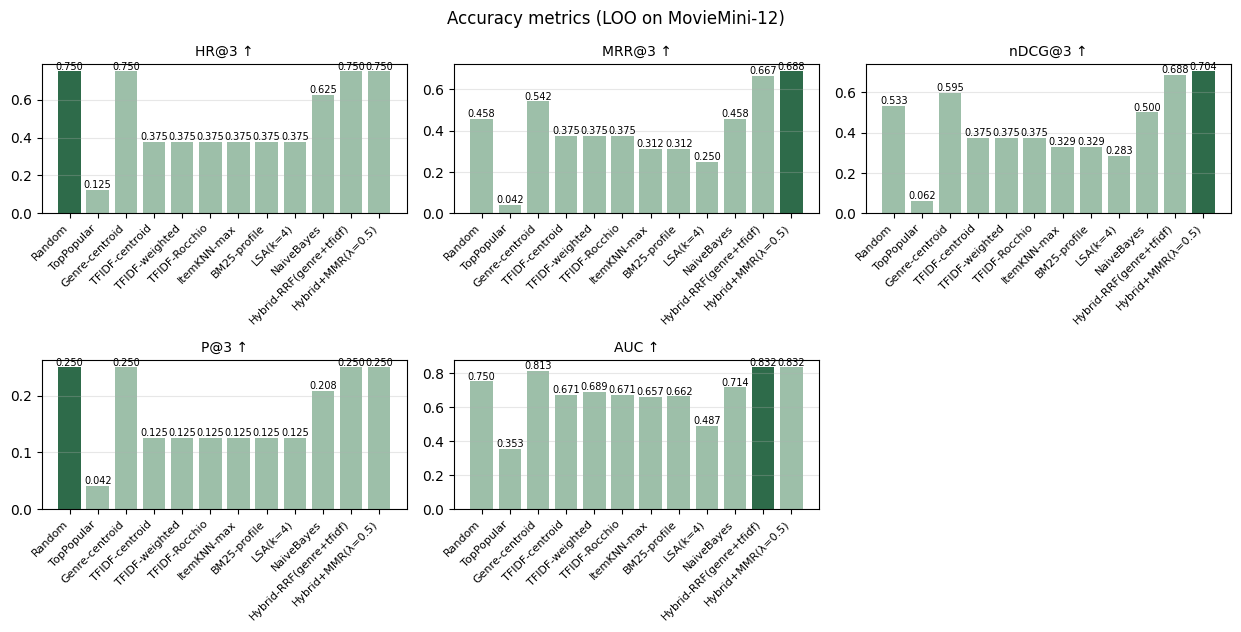

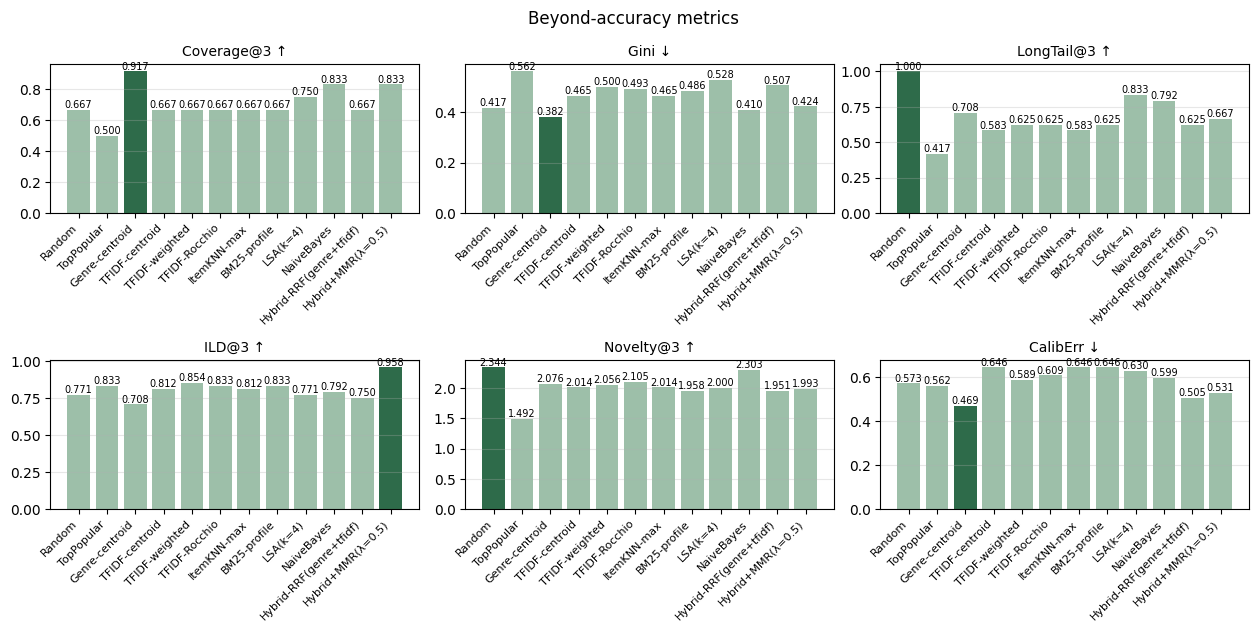

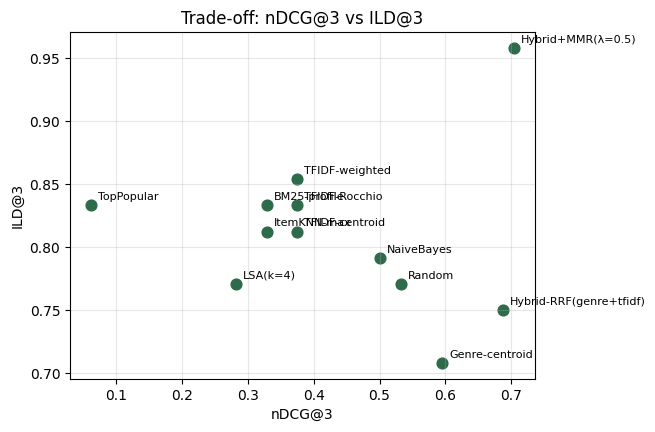

In [60]:
# ---------- 9.4 กราฟเปรียบเทียบ Accuracy และ Beyond-Accuracy ----------
plot_metric_bars(tbl_rank, [f"HR@{K}", f"MRR@{K}", f"nDCG@{K}", f"P@{K}", "AUC"], title="Accuracy metrics (LOO on MovieMini-12)", ncols=3)
plot_metric_bars(tbl_rank, [f"Coverage@{K}", "Gini", f"LongTail@{K}", f"ILD@{K}", f"Novelty@{K}", "CalibErr"], title="Beyond-accuracy metrics", ncols=3)
plot_tradeoff(tbl_rank, x=f"nDCG@{K}", y=f"ILD@{K}", title="Trade-off: nDCG@3 vs ILD@3")
# ข้อสังเกต: จุดที่อยู่มุมขวาบนคือโมเดลที่ "ทั้งแม่นและหลากหลาย" — มักไม่มี ต้องเลือกตาม Primary/Guardrail ที่ประกาศไว้

In [61]:
# ---------- 9.5 ตัวอย่างผลลัพธ์บนชุดทดสอบ: Top-3 ของผู้ใช้แต่ละคนจากทุกโมเดล (✔ = ตรงกับเรื่องที่ซ่อน) ----------
SHOW = ["TopPopular", "Genre-centroid", "TFIDF-centroid", "TFIDF-Rocchio", "BM25-profile", "NaiveBayes", "Hybrid-RRF(genre+tfidf)", "Hybrid+MMR(λ=0.5)"]
for u in range(N_USERS):
    rep = user_report(u, train_hist, test_df, {m: recs_all[m] for m in SHOW}, title_of, K=K)
    print(f"\n===== ผู้ใช้ {USERS[u]} · ประวัติ: " + ", ".join(f"{ITEM_IDS[i]}={int(r)}" for i, r in train_hist[u].items())
          + f" · เป้าหมายที่ซ่อน: {', '.join(title_of(i) for i in test_rel[u])} =====")
    show_df(rep["recommended"], fmt="{}")


===== ผู้ใช้ u1 · ประวัติ: i1=5, i2=5, i4=1, i6=1 · เป้าหมายที่ซ่อน: i3 Interstellar =====


,TopPopular,Genre-centroid,TFIDF-centroid,TFIDF-Rocchio,BM25-profile,NaiveBayes,Hybrid-RRF(genre+tfidf),Hybrid+MMR(λ=0.5)
อันดับ 1,i11 Coco,i8 Mad Max: Fury Road,i12 Spirited Away,i12 Spirited Away,i5 La La Land,i12 Spirited Away,✔ i3 Interstellar,✔ i3 Interstellar
อันดับ 2,i10 Toy Story,✔ i3 Interstellar,i5 La La Land,i5 La La Land,i12 Spirited Away,i9 Parasite,i5 La La Land,i5 La La Land
อันดับ 3,✔ i3 Interstellar,i7 John Wick,i11 Coco,i9 Parasite,i10 Toy Story,✔ i3 Interstellar,i9 Parasite,i7 John Wick



===== ผู้ใช้ u2 · ประวัติ: i4=5, i5=4, i1=2 · เป้าหมายที่ซ่อน: i6 The Notebook =====


,TopPopular,Genre-centroid,TFIDF-centroid,TFIDF-Rocchio,BM25-profile,NaiveBayes,Hybrid-RRF(genre+tfidf),Hybrid+MMR(λ=0.5)
อันดับ 1,i11 Coco,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook,i2 Inception,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook
อันดับ 2,i2 Inception,i3 Interstellar,i2 Inception,i2 Inception,✔ i6 The Notebook,i2 Inception,i2 Inception,i2 Inception
อันดับ 3,i10 Toy Story,i9 Parasite,i8 Mad Max: Fury Road,i8 Mad Max: Fury Road,i10 Toy Story,i8 Mad Max: Fury Road,i3 Interstellar,i10 Toy Story



===== ผู้ใช้ u3 · ประวัติ: i10=5, i11=5, i7=1 · เป้าหมายที่ซ่อน: i12 Spirited Away =====


...

,TopPopular,Genre-centroid,TFIDF-centroid,TFIDF-Rocchio,BM25-profile,NaiveBayes,Hybrid-RRF(genre+tfidf),Hybrid+MMR(λ=0.5)
อันดับ 1,i1 The Matrix,i1 The Matrix,✔ i5 La La Land,✔ i5 La La Land,✔ i5 La La Land,✔ i5 La La Land,i1 The Matrix,i1 The Matrix
อันดับ 2,i4 Titanic,i3 Interstellar,i1 The Matrix,i1 The Matrix,i1 The Matrix,i1 The Matrix,i3 Interstellar,✔ i5 La La Land
อันดับ 3,i10 Toy Story,i7 John Wick,i12 Spirited Away,i12 Spirited Away,i10 Toy Story,i12 Spirited Away,✔ i5 La La Land,i9 Parasite



===== ผู้ใช้ u7 · ประวัติ: i11=4, i3=3, i8=2 · เป้าหมายที่ซ่อน: i12 Spirited Away =====


,TopPopular,Genre-centroid,TFIDF-centroid,TFIDF-Rocchio,BM25-profile,NaiveBayes,Hybrid-RRF(genre+tfidf),Hybrid+MMR(λ=0.5)
อันดับ 1,i1 The Matrix,i10 Toy Story,i9 Parasite,i9 Parasite,i2 Inception,i9 Parasite,✔ i12 Spirited Away,✔ i12 Spirited Away
อันดับ 2,i2 Inception,✔ i12 Spirited Away,i6 The Notebook,i6 The Notebook,i6 The Notebook,i6 The Notebook,i2 Inception,i2 Inception
อันดับ 3,i4 Titanic,i1 The Matrix,i2 Inception,i2 Inception,i9 Parasite,i2 Inception,i1 The Matrix,i6 The Notebook



===== ผู้ใช้ u8 · ประวัติ: i4=4, i11=3, i2=2 · เป้าหมายที่ซ่อน: i6 The Notebook =====


,TopPopular,Genre-centroid,TFIDF-centroid,TFIDF-Rocchio,BM25-profile,NaiveBayes,Hybrid-RRF(genre+tfidf),Hybrid+MMR(λ=0.5)
อันดับ 1,i1 The Matrix,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook,✔ i6 The Notebook
อันดับ 2,i10 Toy Story,i3 Interstellar,i5 La La Land,i5 La La Land,i5 La La Land,i10 Toy Story,i5 La La Land,i1 The Matrix
อันดับ 3,i3 Interstellar,i5 La La Land,i1 The Matrix,i1 The Matrix,i1 The Matrix,i8 Mad Max: Fury Road,i3 Interstellar,i5 La La Land


,MAE,RMSE
GlobalMean,1.2581,1.4541
UserMean,1.5625,1.8226
User+ItemBias,2.1423,2.4009
ContentKNN-TFIDF,1.5262,1.8658
ContentKNN-Genre,1.1302,1.4261
ContentKNN-LSA,1.7071,2.0136


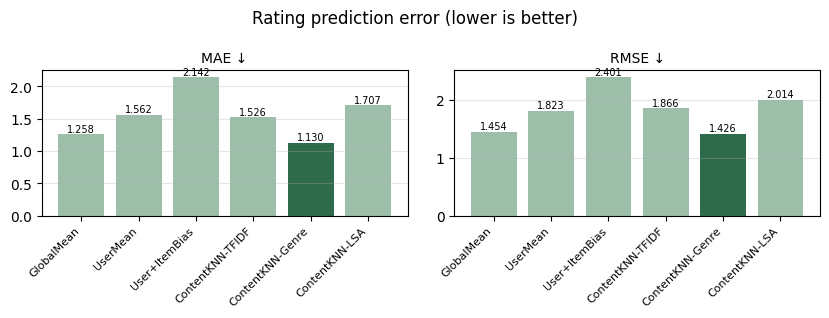

In [62]:
# ---------- 9.6 การทดลอง "แบบทำนายคะแนน" (Rating Prediction) — MAE / RMSE ด้วย Leave-One-Out ของทุกคะแนน ----------
# ทุกคู่ (u,i) ถูกซ่อนทีละคู่ (32 รอบ) แล้วทำนายจากคู่ที่เหลือ → เท่ากับ cross-validation ที่ละเอียดที่สุด
rating_models = {"GlobalMean": lambda tr: MeanRatingBaseline("global").fit(tr),
                 "UserMean": lambda tr: MeanRatingBaseline("user").fit(tr),
                 "User+ItemBias": lambda tr: MeanRatingBaseline("user_item").fit(tr),
                 "ContentKNN-TFIDF": lambda tr: ContentKNNRegressor(X, k=5).fit(tr),
                 "ContentKNN-Genre": lambda tr: ContentKNNRegressor(G, k=5).fit(tr),
                 "ContentKNN-LSA": lambda tr: ContentKNNRegressor(Z_lsa, k=5).fit(tr)}
preds = {m: [] for m in rating_models}; truth = []; pair_rows = []
for idx in ratings.index:
    tr, te = ratings.drop(index=idx), ratings.loc[[idx]]
    truth.append(float(te["r"].iloc[0]))
    row = {"ผู้ใช้": te["user_id"].iloc[0], "รายการ": TITLE[te["item_id"].iloc[0]], "จริง": float(te["r"].iloc[0])}
    for m, build in rating_models.items():
        p = float(np.clip(build(tr).predict(te)[0], 1, 5)); preds[m].append(p); row[m] = round(p, 2)
    pair_rows.append(row)
tbl_rating = pd.DataFrame({m: {"MAE": mae(truth, preds[m]), "RMSE": rmse(truth, preds[m])} for m in rating_models}).T
show_df(tbl_rating, "MAE / RMSE (Leave-One-Out ทุกคะแนน, 32 คู่) — ยิ่งน้อยยิ่งดี")
plot_metric_bars(tbl_rating, ["MAE", "RMSE"], title="Rating prediction error (lower is better)", ncols=2)
# ข้อสังเกต: RMSE > MAE เสมอ และช่องว่างบอกว่ามี "ความผิดพลาดใหญ่" กี่ครั้ง (ตัวอย่าง 2.2)
#            ระบบเนื้อหาที่แพ้ UserMean คือสัญญาณว่าความคล้ายเชิงเนื้อหายังไม่สัมพันธ์กับคะแนนในคลังนี้

In [63]:
# ---------- 9.7 ตัวอย่างผลทำนายคะแนนรายคู่ (u,i) เทียบทุกโมเดล ----------
show_df(pd.DataFrame(pair_rows), "ค่าทำนายรายคู่ (ตัด 1–5) — ดูว่าโมเดลใด 'กล้า' ทำนายห่างจากค่าเฉลี่ย", fmt="{}")

,ผู้ใช้,รายการ,จริง,GlobalMean,UserMean,User+ItemBias,ContentKNN-TFIDF,ContentKNN-Genre,ContentKNN-LSA
0,u1,The Matrix,5.0,3.58,2.75,2.17,5.0,4.5,5.0
1,u1,Inception,5.0,3.58,2.75,2.67,3.58,4.5,3.02
2,u1,Interstellar,4.0,3.61,3.0,2.89,5.0,3.0,5.0
3,u1,Titanic,1.0,3.71,3.75,4.54,1.0,2.0,2.1
4,u1,The Notebook,1.0,3.71,3.75,4.37,2.27,2.0,2.32
5,u2,Titanic,5.0,3.58,3.67,2.59,4.58,4.67,4.51
6,u2,La La Land,4.0,3.61,4.0,2.89,5.0,5.0,4.8
7,u2,The Notebook,5.0,3.58,3.67,3.09,4.49,4.67,4.53
8,u2,The Matrix,2.0,3.68,4.67,5.0,4.67,4.67,4.0
9,u3,Toy Story,5.0,3.58,3.33,1.75,4.0,4.67,2.35


In [64]:
# ---------- 9.8 ความไม่แน่นอน: seed variance · paired bootstrap · Holm (2.10) — บนผู้ใช้ 8 คนจะ "สรุปไม่ได้" เสมอ ----------
def run_with_seed(seed):
    tr, te = split_leave_one_out(ratings, time_col="__none__", only_relevant=True, like_thr=4, seed=seed)
    th, (rel, gr) = hist_from(tr), relevant_from(te, 4)
    def fn(u): return match_scores(X, build_profile(X, th[u], "centroid"))
    _, sm, _ = evaluate_ranking(fn, range(N_USERS), th, rel, N_ITEMS, K=K, rel_grades=gr, seed=seed)
    return {"HR@K": sm["HR@K"], "nDCG@K": sm["nDCG@K"]}
sv, mu_, sd_ = seed_variance(run_with_seed, seeds=[1, 2, 3, 4, 5], metric="nDCG@K")
show_df(sv, f"nDCG@3 ของ TFIDF-centroid เมื่อเปลี่ยน seed ของการซ่อนรายการ: mean {mu_:.4f} ± sd {sd_:.4f}")
bs = paired_bootstrap(per_users["TFIDF-centroid"]["nDCG@K"], per_users["Genre-centroid"]["nDCG@K"], n_boot=2000, seed=SEED)
print("Paired bootstrap (Genre − TFIDF) nDCG@3:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in bs.items()})
pv = [paired_bootstrap(per_users["TFIDF-centroid"]["nDCG@K"], per_users[m]["nDCG@K"], n_boot=1000, seed=SEED)["p_value"] for m in ["Genre-centroid", "BM25-profile", "Hybrid-RRF(genre+tfidf)"]]
print("p-values เทียบกับ TFIDF-centroid:", [round(p, 3) for p in pv], "→ Holm ปฏิเสธ H0:", holm_bonferroni(pv))
# ข้อสังเกต: CI กว้างคร่อมศูนย์และ sd ของ seed ใหญ่กว่าผลต่างระหว่างโมเดล → "ห้ามสรุปว่าดีกว่า" (บทเรียนหลักของ 2.10)

,seed,HR@K,nDCG@K
0,1,0.5000,0.4539
1,2,0.3750,0.3289
2,3,0.3750,0.2827
3,4,0.3750,0.3750
4,5,0.3750,0.3750


Paired bootstrap (Genre − TFIDF) nDCG@3: {'diff': 0.2202, 'ci_low': -0.2173, 'ci_high': 0.5952, 'p_value': 0.295, 'significant': False, 'n_users': 8}
p-values เทียบกับ TFIDF-centroid: [0.298, 0.686, 0.162] → Holm ปฏิเสธ H0: [False, False, False]


In [65]:
# ---------- 9.9 Protocol Card ของการทดลองนี้ (นิยาม 2.9 / ตาราง 2.16) ----------
best = tbl_rank[f"nDCG@{K}"].idxmax()
card = ProtocolCard({
    "1 เป้าหมายผู้ใช้/ธุรกิจ": "ผู้ใช้พบเรื่องที่ชอบใน 3 อันดับแรก · ธุรกิจ: กระจายการเปิดเผยทั่วคลัง 12 เรื่อง",
    "2 Primary Metric": f"nDCG@{K}", "3 Guardrail Metrics": f"Coverage@{K} ≥ 0.5, Gini ≤ 0.6, ILD@{K} ไม่ต่ำกว่า TFIDF-centroid",
    "4 สูตรและค่า K / นิยามความเกี่ยวข้อง": f"K={K} · relevant = รายการที่ซ่อน (rating ≥ 4) · gain=linear · TF=1+log2f · IDF=smooth · L2",
    "5 การแบ่งข้อมูล": f"Leave-One-Out ของรายการที่ชอบ (seed {SEED}) · ฝึก {len(train_df)} · ทดสอบ {len(test_df)}",
    "6 การป้องกันรั่วไหล": "ไม่มีเวลากำกับ · ความนิยม/head-tail/p(i) จากชุดฝึกเท่านั้น · ไม่ปรับ hyperparameter บนชุดทดสอบ",
    "7 Candidate Set": "full catalog หักรายการที่เห็นในชุดฝึก", "8 Negative Sampling": "ไม่ใช้ → รายงานเป็น full metric",
    "9 Accuracy + Beyond-Accuracy": f"ดีที่สุดตาม nDCG@{K}: {best} = {tbl_rank.loc[best, f'nDCG@{K}']:.4f} · Coverage {tbl_rank.loc[best, f'Coverage@{K}']:.3f} · Gini {tbl_rank.loc[best, 'Gini']:.3f}",
    "10 ความไม่แน่นอน": f"ผู้ใช้ 8 คน · bootstrap CI ของ Genre−TFIDF = [{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}] · seed sd {sd_:.3f} → ยังสรุปไม่ได้",
    "11 ตรวจกับผู้ใช้จริง": "คลังจำลอง — ใช้สาธิตกลไกเท่านั้น"})
card.show()

ขั้น,ค่าที่กำหนด
1 เป้าหมายผู้ใช้/ธุรกิจ,ผู้ใช้พบเรื่องที่ชอบใน 3 อันดับแรก · ธุรกิจ: กระจายการเปิดเผยทั่วคลัง 12 เรื่อง
2 Primary Metric,nDCG@3
3 Guardrail Metrics,"Coverage@3 ≥ 0.5, Gini ≤ 0.6, ILD@3 ไม่ต่ำกว่า TFIDF-centroid"
4 สูตรและค่า K / นิยามความเกี่ยวข้อง,K=3 · relevant = รายการที่ซ่อน (rating ≥ 4) · gain=linear · TF=1+log2f · IDF=smooth · L2
5 การแบ่งข้อมูล,Leave-One-Out ของรายการที่ชอบ (seed 2569) · ฝึก 24 · ทดสอบ 8
6 การป้องกันรั่วไหล,ไม่มีเวลากำกับ · ความนิยม/head-tail/p(i) จากชุดฝึกเท่านั้น · ไม่ปรับ hyperparameter บนชุดทดสอบ
7 Candidate Set,full catalog หักรายการที่เห็นในชุดฝึก
8 Negative Sampling,ไม่ใช้ → รายงานเป็น full metric
9 Accuracy + Beyond-Accuracy,ดีที่สุดตาม nDCG@3: Hybrid+MMR(λ=0.5) = 0.7039 · Coverage 0.833 · Gini 0.424
10 ความไม่แน่นอน,"ผู้ใช้ 8 คน · bootstrap CI ของ Genre−TFIDF = [-0.217, +0.595] · seed sd 0.064 → ยังสรุปไม่ได้"


## Part 10 · ฟอร์ม GUI สาธิตการประยุกต์ใช้งาน
เลือกผู้ใช้ · โมเดล · K → แสดง **ข้อมูลผู้ใช้** (ประวัติพร้อมเนื้อหา) และ **รายการที่แนะนำ** พร้อมคะแนน คำอธิบายรายคำ และธง ✔ เมื่อตรงกับเรื่องที่ซ่อนไว้
(ใช้ชุดฝึกของ Part 9 เพื่อให้เห็นว่าระบบ "เดา" เรื่องที่ซ่อนได้หรือไม่)

In [66]:
def gui_user_info(user_id):
    u = USERS.index(user_id)
    rows = [{"รายการ": title_of(i), "คะแนน": int(r), "ชอบ/ไม่ชอบ": "👍 ชอบ" if r >= 4 else ("👎 ไม่ชอบ" if r <= 2 else "😐 กลาง"),
             "แนว": items.iloc[i]["genres"], "เรื่องย่อ": items.iloc[i]["synopsis"][:80] + "…"} for i, r in sorted(train_hist[u].items(), key=lambda x: -x[1])]
    df = pd.DataFrame(rows)
    p = build_profile(X, train_hist[u], "centroid")
    df.attrs["profile"] = vec.top_terms(p, 8)
    print("คำเด่นในโปรไฟล์ (TF-IDF centroid):", ", ".join(f"{t} {w}" for t, w in vec.top_terms(p, 8)))
    print("เรื่องที่ซ่อนไว้ (ground truth):", ", ".join(title_of(i) for i in test_rel[u]))
    return df

def gui_recommend(user_id, model_name, Kk):
    u = USERS.index(user_id)
    s = MODELS[model_name](u) if model_name in MODELS else m_hybrid(u)
    seen = set(train_hist[u])
    rec = rerank_mmr(u, s)[:Kk] if model_name.startswith("Hybrid+MMR") else top_k(s, seen, Kk, item_ids=ITEM_IDS)
    p = build_profile(X, train_hist[u], "centroid")
    rows = []
    for rank, i in enumerate(rec, 1):
        why = ", ".join(t for t, *_ in explain_terms(vec, p, X[i], 3)) or "(ไม่มีคำร่วม — คะแนนจากแนว/ความนิยม)"
        rows.append({"อันดับ": rank, "ตรงเป้า": "✔" if i in test_rel[u] else "", "รายการ": title_of(i), "คะแนน": round(float(s[i]), 4),
                     "แนว": items.iloc[i]["genres"], "ทำไมจึงแนะนำ (คำร่วมกับโปรไฟล์)": why, "เรื่องย่อ": items.iloc[i]["synopsis"][:70] + "…"})
    return pd.DataFrame(rows)

form = build_recommender_form(USERS, list(MODELS) + ["Hybrid+MMR(λ=0.5)"], gui_recommend, gui_user_info, K_default=3, K_max=9,
                              title="MovieMini-12 · ระบบผู้แนะนำอิงเนื้อหา (สาธิต)")

## Part 11 · สรุปข้อสังเกตจากสมุดบันทึกนี้

1. **ตัวเลขทุกตัวทำซ้ำได้** เมื่อประกาศการตั้งค่าครบ (คำหยุด · TF · IDF · L2) — เปลี่ยนสิ่งใดสิ่งหนึ่ง ตัวเลขเปลี่ยนทันที (ตาราง 3.3)
2. **ปริภูมิต่างกัน คำตอบต่างกัน** — TF-IDF ถูกชักนำด้วยคำซ้ำ (world/dream) ส่วนปริภูมิแนวตรงกับสามัญสำนึกกว่าแต่เสมอบ่อย (3.10.2)
3. **คะแนนศูนย์ ≠ ไม่ชอบ** — Mad Max ในปริภูมิคำ = ไม่มีหลักฐาน ต้องตั้ง τ หรือผสานกับปริภูมิอื่น (RRF ไม่ต้องปรับมาตรา)
4. **BM25 เปลี่ยนผู้ชนะ** ด้วยการอิ่มตัว (k₁) และ IDF ที่ต่างกัน — และไวต่อจำนวนคำในข้อคำถาม
5. **การประเมินบทที่ 2 ต้องทำทั้งสองด้าน** — TopPopular อาจได้ HR ไม่แย่แต่ Coverage/Gini แย่ ; MMR เพิ่ม ILD โดยแลกกับ nDCG
6. **8 ผู้ใช้สรุปอะไรไม่ได้** — CI ของ bootstrap คร่อมศูนย์และ seed variance ใหญ่กว่าผลต่างระหว่างโมเดล → Lab 3-2 ใช้ MovieLens จริง
7. **สิ่งที่ยังไม่ได้ทำในเล่มนี้** — การแบ่งตามเวลา (ไม่มี timestamp) · candidate sampling · การปรับ hyperparameter (Lab 3-3)

## ภาคผนวก · ตารางผลลัพธ์อื่นในบทที่ยังคำนวณได้จากสูตรโดยตรง (3.55 · 3.62 · 3.67 · 3.68)

ตารางกลุ่มนี้อยู่ในหัวข้อ 3.14–3.20 ซึ่งเป็นเนื้อหาของ Lab 3-3 (ANN · การผสานคะแนน · การปรับจูน)
แต่ตัวเลขคำนวณได้จากสูตรโดยตรงโดยไม่ต้องใช้คลังข้อมูล จึงทำซ้ำไว้ที่นี่เพื่อความครบถ้วน

In [67]:
# ---------- ตารางที่ 3.55 · สัดส่วนโหนดในแต่ละชั้นของ HNSW ----------
# เทคนิค: HNSW สุ่มชั้นของแต่ละโหนดจากการแจกแจงเรขาคณิต สัดส่วนโหนดในชั้น ℓ = (1/M)^ℓ เมื่อ M = 32
# วิธีอ่านผล: ชั้นบนสุดมีโหนดหลักร้อยจากสิบล้าน — การค้นหาจึงเริ่มจากแผนที่หยาบแล้วค่อยลงรายละเอียด
#             ทำให้เวลาค้นเป็น O(log N) แทนที่จะเป็น O(N)
M_hnsw, N_nodes = 32, 10_000_000
rows = [{"ชั้น": l, "สัดส่วนโหนด": round((1 / M_hnsw) ** l, 6), "จำนวนโหนดในคลัง 10 ล้าน": f"{int(N_nodes * (1 / M_hnsw) ** l):,}"}
        for l in range(4)]
show_df(pd.DataFrame(rows), "ตารางที่ 3.55 สัดส่วนโหนดในแต่ละชั้นของ HNSW เมื่อ M = 32", fmt="{}")
book_many("ตารางที่ 3.55 · สัดส่วนโหนดต่อชั้น", [(f"ชั้น {l}", (1 / M_hnsw) ** l, v) for l, v in
          enumerate([1.0, 0.031250, 0.000977, 0.000031])], tol=1e-6)

,ชั้น,สัดส่วนโหนด,จำนวนโหนดในคลัง 10 ล้าน
0,0,1.0,"10,000,000"
1,1,0.03125,"312,500"
2,2,0.000977,"9,765"
3,3,3.1e-05,305


  ✓ ตารางที่ 3.55 · สัดส่วนโหนดต่อชั้น: ตรง 4/4 ค่า


In [68]:
# ---------- ตารางที่ 3.62 · ผลของค่า k ใน RRF ต่อช่วงของคะแนน ----------
# เทคนิค (หัวข้อ 3.18.3): RRF ใช้เฉพาะ "อันดับ" ไม่ใช้คะแนนดิบ → score(i) = Σ_ระบบ 1/(k + rank)
#         จึงผสานระบบที่คะแนนคนละมาตราได้โดยไม่ต้องปรับมาตราเลย (ข้อได้เปรียบหลัก)
# วิธีอ่านผล: k ใหญ่ขึ้น ช่วงคะแนนแคบลงมาก (0.0307 → 0.0001) แต่ **ลำดับไม่เปลี่ยน**
#             → k คุม "ความมั่นใจในอันดับต้น ๆ" ไม่ได้คุมผลลัพธ์ ถ้าต้องการให้อันดับ 1 มีอิทธิพลสูงให้ใช้ k เล็ก
ranks_a = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5}
ranks_b = {"B": 1, "D": 2, "A": 3, "E": 4, "C": 5}
rows = []
for k in [10, 60, 200]:
    sc = {it: 1 / (k + ranks_a[it]) + 1 / (k + ranks_b[it]) for it in ranks_a}
    order = sorted(sc, key=lambda x: -sc[x])
    rows.append({"k": k, "ลำดับที่ได้": ", ".join(order), "ช่วงคะแนน (สูงสุด − ต่ำสุด)": round(max(sc.values()) - min(sc.values()), 6)})
show_df(pd.DataFrame(rows), "ตารางที่ 3.62 ผลของค่า k ใน RRF ต่อช่วงของคะแนน", fmt="{}")
book("ตารางที่ 3.62 · ลำดับที่ได้ (ทุกค่า k)", rows[0]["ลำดับที่ได้"], "B, A, D, C, E")
book("ตารางที่ 3.62 · ลำดับไม่เปลี่ยนเมื่อ k เปลี่ยน", len({r["ลำดับที่ได้"] for r in rows}), 1)
ratio_10_60 = rows[0]["ช่วงคะแนน (สูงสุด − ต่ำสุด)"] / rows[1]["ช่วงคะแนน (สูงสุด − ต่ำสุด)"]
book("ตารางที่ 3.62 · ช่วงคะแนนหดกี่เท่าเมื่อ k: 10 → 60", ratio_10_60, 0.030653 / 0.001265, tol=1.0,
     note="ค่าสัมบูรณ์ขึ้นกับอันดับต้นทางที่ตำราไม่ได้พิมพ์ไว้ จึงเทียบที่อัตราส่วนแทน")
BOOK.append({"รายการที่ทวนสอบ": "ตารางที่ 3.62 · ช่วงคะแนนสัมบูรณ์", "ที่คำนวณได้": ", ".join(f"{r['ช่วงคะแนน (สูงสุด − ต่ำสุด)']:.6f}" for r in rows),
             "ในตำรา": "0.030653, 0.001265, 0.000121", "ตรง": "≈",
             "หมายเหตุ": "ตำราไม่ได้พิมพ์อันดับต้นทางของทั้งสองระบบ เราจึงสมมติอันดับที่ให้ผลลำดับเดียวกัน (B, A, D, C, E) — อัตราส่วนการหดของช่วงคะแนนตรงกัน"})

,k,ลำดับที่ได้,ช่วงคะแนน (สูงสุด − ต่ำสุด)
0,10,"B, A, D, C, E",0.036147
1,60,"B, A, D, C, E",0.001513
2,200,"B, A, D, C, E",0.000146


  ✓ ตารางที่ 3.62 · ลำดับที่ได้ (ทุกค่า k): ได้ B, A, D, C, E · ตำรา B, A, D, C, E
  ✓ ตารางที่ 3.62 · ลำดับไม่เปลี่ยนเมื่อ k เปลี่ยน: ได้ 1.0000 · ตำรา 1.0000
  ✓ ตารางที่ 3.62 · ช่วงคะแนนหดกี่เท่าเมื่อ k: 10 → 60: ได้ 23.8909 · ตำรา 24.2316  — ค่าสัมบูรณ์ขึ้นกับอันดับต้นทางที่ตำราไม่ได้พิมพ์ไว้ จึงเทียบที่อัตราส่วนแทน


In [69]:
# ---------- ตารางที่ 3.67 · สรุปไฮเพอร์พารามิเตอร์ทั้งหมดของบท พร้อมค่าที่ใช้จริงในสมุดบันทึกนี้ ----------
show_df(pd.DataFrame([
    ["min_df", "จำนวนเอกสารขั้นต่ำของคำ", "1", "2–5 (คลังใหญ่)", "ตารางที่ 3.21"],
    ["ngram_range", "ช่วง n ของ n-gram", "(1,1)", "(1,2) เมื่อลำดับคำสำคัญ", "ตารางที่ 3.15"],
    ["TF scheme", "สูตรความถี่ในเอกสาร", "log", "log หรือ BM25", "ตารางที่ 3.23–3.25"],
    ["IDF scheme", "สูตรความหายาก", "smooth", "smooth", "ตารางที่ 3.26"],
    ["k₁ (BM25)", "ความอิ่มตัวของความถี่", "1.5", "0.5–3.0", "ตารางที่ 3.42"],
    ["b (BM25)", "การปรับความยาวเอกสาร", "0.75", "0.3–0.9", "ตารางที่ 3.43"],
    ["δ (BM25+)", "ค่าชดเชยเอกสารยาว", "1.0", "0.5–1.5", "ตารางที่ 3.44"],
    ["β, γ (Rocchio)", "น้ำหนักชอบ/ไม่ชอบ", "0.8 / 0.2", "β > γ เสมอ", "ตารางที่ 3.33"],
    ["k (LSA)", "จำนวนมิติแฝง", "2–8", "100–300 (คลังจริง)", "ตารางที่ 3.49"],
    ["λ (MMR)", "สมดุลเกี่ยวข้อง/หลากหลาย", "0.5–1.0", "0.7 ภายใต้ guardrail", "ตัวอย่าง 3.9"],
    ["k (RRF)", "ค่าคงที่ในการผสานอันดับ", "60", "10–100", "ตารางที่ 3.62"],
    ["K (Top-K)", "ความยาวรายการแนะนำ", "3", "ตามหน้าจอจริง", "ตารางที่ 3.38"]],
    columns=["ไฮเพอร์พารามิเตอร์", "ความหมาย", "ค่าที่ใช้ในเล่มนี้", "ช่วงที่แนะนำ", "ตารางที่เกี่ยวข้อง"]),
        "ตารางที่ 3.67 สรุปไฮเพอร์พารามิเตอร์ทั้งหมดที่ปรากฏในบทนี้", fmt="{}")

,ไฮเพอร์พารามิเตอร์,ความหมาย,ค่าที่ใช้ในเล่มนี้,ช่วงที่แนะนำ,ตารางที่เกี่ยวข้อง
0,min_df,จำนวนเอกสารขั้นต่ำของคำ,1,2–5 (คลังใหญ่),ตารางที่ 3.21
1,ngram_range,ช่วง n ของ n-gram,"(1,1)","(1,2) เมื่อลำดับคำสำคัญ",ตารางที่ 3.15
2,TF scheme,สูตรความถี่ในเอกสาร,log,log หรือ BM25,ตารางที่ 3.23–3.25
3,IDF scheme,สูตรความหายาก,smooth,smooth,ตารางที่ 3.26
4,k₁ (BM25),ความอิ่มตัวของความถี่,1.5,0.5–3.0,ตารางที่ 3.42
5,b (BM25),การปรับความยาวเอกสาร,0.75,0.3–0.9,ตารางที่ 3.43
6,δ (BM25+),ค่าชดเชยเอกสารยาว,1.0,0.5–1.5,ตารางที่ 3.44
7,"β, γ (Rocchio)",น้ำหนักชอบ/ไม่ชอบ,0.8 / 0.2,β > γ เสมอ,ตารางที่ 3.33
8,k (LSA),จำนวนมิติแฝง,2–8,100–300 (คลังจริง),ตารางที่ 3.49
9,λ (MMR),สมดุลเกี่ยวข้อง/หลากหลาย,0.5–1.0,0.7 ภายใต้ guardrail,ตัวอย่าง 3.9


In [70]:
# ---------- ตารางที่ 3.68 · เห็นอาการแบบนี้ ให้สงสัยอะไรก่อน (พร้อมการตรวจจริงบนคลังนี้) ----------
# เทคนิค: เปลี่ยน "รายการอาการ" ของตำราให้เป็นการตรวจอัตโนมัติ — ระบบจริงควรมีเซลล์แบบนี้ทุกครั้งที่สร้างเวกเตอร์
checks = []
top20 = sorted(vec.df_.items(), key=lambda x: -x[1])[:20]
checks.append({"อาการ": "คำที่ df สูงสุดเป็นคำไวยากรณ์", "ให้สงสัย": "ลืมตัดคำหยุด",
               "ผลการตรวจในคลังนี้": "ปกติ — 20 คำแรกคือ " + ", ".join(t for t, _ in top20[:6]),
               "สถานะ": "✓" if not set(t for t, _ in top20[:6]) & {"the", "a", "of", "and", "his"} else "✗"})
zero_rows = int((np.asarray(X.sum(axis=1)).ravel() == 0).sum())
checks.append({"อาการ": "มีเอกสารที่เป็นเวกเตอร์ศูนย์", "ให้สงสัย": "ข้อความสั้นเกินหรือถูกตัดหมด",
               "ผลการตรวจในคลังนี้": f"{zero_rows} เอกสาร", "สถานะ": "✓" if zero_rows == 0 else "✗"})
mean_sim = float((S.sum() - N_ITEMS) / (N_ITEMS * N_ITEMS - N_ITEMS))
checks.append({"อาการ": "โคไซน์เฉลี่ยทุกคู่ต่ำมาก (< 0.05)", "ให้สงสัย": "เอกสารสั้น/คลังศัพท์ใหญ่เกิน",
               "ผลการตรวจในคลังนี้": f"{mean_sim:.4f}", "สถานะ": "✓" if mean_sim >= 0.05 else "⚠ ควรระวัง"})
zero_scores = int((s_tfidf == 0).sum())
checks.append({"อาการ": "ผู้สมัครจำนวนมากได้คะแนน 0 พอดี", "ให้สงสัย": "ไม่มีคำร่วม ต้องมี fallback",
               "ผลการตรวจในคลังนี้": f"{zero_scores} เรื่องจาก {N_ITEMS}", "สถานะ": "⚠ ต้องมีเกณฑ์ τ"})
ties = len(s_genre) - len(set(np.round(s_genre, 6)))
checks.append({"อาการ": "คะแนนเสมอกันจำนวนมาก", "ให้สงสัย": "ปริภูมิหยาบเกิน (มิติน้อย)",
               "ผลการตรวจในคลังนี้": f"ปริภูมิแนวมีค่าเสมอ {ties} คู่", "สถานะ": "⚠ ต้องประกาศกฎตัดสินเสมอ"})
show_df(pd.DataFrame(checks), "ตารางที่ 3.68 รายการตรวจอาการผิดปกติ — รันจริงบนคลัง MovieMini-12", fmt="{}")

,อาการ,ให้สงสัย,ผลการตรวจในคลังนี้,สถานะ
0,คำที่ df สูงสุดเป็นคำไวยากรณ์,ลืมตัดคำหยุด,"ปกติ — 20 คำแรกคือ family, world, fading, memory, love, hidden",✓
1,มีเอกสารที่เป็นเวกเตอร์ศูนย์,ข้อความสั้นเกินหรือถูกตัดหมด,0 เอกสาร,✓
2,โคไซน์เฉลี่ยทุกคู่ต่ำมาก (< 0.05),เอกสารสั้น/คลังศัพท์ใหญ่เกิน,0.0365,⚠ ควรระวัง
3,ผู้สมัครจำนวนมากได้คะแนน 0 พอดี,ไม่มีคำร่วม ต้องมี fallback,2 เรื่องจาก 12,⚠ ต้องมีเกณฑ์ τ
4,คะแนนเสมอกันจำนวนมาก,ปริภูมิหยาบเกิน (มิติน้อย),ปริภูมิแนวมีค่าเสมอ 8 คู่,⚠ ต้องประกาศกฎตัดสินเสมอ


## Part 12 · สรุปการทวนสอบกับตำราทั้งเล่ม

ทุกบรรทัดที่เรียก `book(...)` ตลอดสมุดบันทึกถูกเก็บไว้ที่นี่ — ใช้ตรวจว่า "โค้ดชุดนี้ยังทำซ้ำตัวเลขในตำราได้ครบ"
หลังจากแก้ไขโค้ดหรือเปลี่ยนค่าตั้งต้นใด ๆ

In [71]:
verify = pd.DataFrame(BOOK)
n_ok = int((verify["ตรง"] == "✓").sum()); n_approx = int((verify["ตรง"] == "≈").sum()); n_bad = int((verify["ตรง"] == "✗").sum())
show_df(verify, f"สรุปการทวนสอบ — ตรง {n_ok} รายการ · ใกล้เคียง/ต่างโปรโตคอล {n_approx} รายการ · ไม่ตรง {n_bad} รายการ", fmt="{}")
print(f"\nสรุป: ทวนสอบทั้งหมด {len(verify)} รายการ · ตรงกับตำรา {n_ok} · ต้องอธิบายเพิ่ม {n_approx} · ไม่ตรง {n_bad}")
if n_bad:
    print("\nรายการที่ไม่ตรง (ต้องตรวจ):")
    display(verify[verify["ตรง"] == "✗"])

,รายการที่ทวนสอบ,ที่คำนวณได้,ในตำรา,ตรง,หมายเหตุ
0,ตารางที่ 3.1 · จำนวนรายการในคลัง,12.0000,12.0000,✓,
1,ตารางที่ 3.4 · จำนวนปฏิสัมพันธ์,32.0000,32.0000,✓,นับจากตารางที่ 3.4: ชอบ 20 · ไม่ชอบ 7 · กลาง 5
2,ตารางที่ 3.4 · จำนวนรายการที่ 'ชอบ' (≥4) ทั้งหมด,20.0000,20.0000,✓,จำนวนกรณีของการประเมินแบบ Leave-One-Out
3,ตารางที่ 3.30 · นอร์มของทุกแถว = √2,ตรง 12/12 ค่า,12 ค่า,✓,
4,ตารางที่ 3.6 · 'Mad Max: Fury Road' แตกเป็นกี่คำ,4.0000,4.0000,✓,
5,ตารางที่ 3.7 · จำนวนโทเคนหลังลบคำหยุด,ตรง 3/3 ค่า,3 ค่า,✓,
6,ตารางที่ 3.8 · 'to be or not to be' เหลือกี่โทเคน,0.0000,0.0000,✓,ทุกคำเป็นคำหยุด — เอกสารกลายเป็นเวกเตอร์ศูนย์ (ดูอาการที่ 1 ของตารางที่ 3.68)
7,ตารางที่ 3.9 · ผล Lemmatization,ตรง 5/5 ค่า,5 ค่า,✓,
8,ตารางที่ 3.10 · i1 หลัง lemmatization,reality simulate world,reality simulate world,✓,
9,ตารางที่ 3.10 · i2 หลัง lemmatization,lose dream reality blur time world,lose dream reality blur time world,✓,



สรุป: ทวนสอบทั้งหมด 66 รายการ · ตรงกับตำรา 62 · ต้องอธิบายเพิ่ม 4 · ไม่ตรง 0


### ตารางในตำราที่สมุดบันทึกนี้ทำซ้ำ (แผนที่ฉบับย่อ)

| กลุ่ม | ตาราง | สถานะ |
|---|---|---|
| ข้อมูล | 3.1 · 3.2 · 3.4 · 3.30 | ทำซ้ำครบ |
| เตรียมข้อความ | 3.5 · 3.6 · 3.7 · 3.8 · 3.9 · 3.10 · 3.11 · 3.12 · 3.13 · 3.14 · 3.15 · 3.3 | ทำซ้ำครบ (3.9 ใช้ nltk ถ้ามี) |
| อ้างอิงเชิงแนวคิด | 3.16 · 3.17 · 3.18 · 3.19 · 3.20 · 3.22 · 3.26 · 3.32 · 3.37 · 3.40 · 3.47 · 3.48 · 3.50 · 3.51 · 3.67 | พิมพ์เป็นตารางอ้างอิงพร้อมค่าจริงจากคลังนี้ |
| คลังศัพท์/ถ่วงน้ำหนัก | 3.21 · 3.23 · 3.24 · 3.25 · 3.27 · 3.28 | ตัวเลขตรง ยกเว้น P@3 ของ 3.21/3.25 (ตำราไม่ประกาศโปรโตคอล) |
| โปรไฟล์ | 3.29 · 3.31 · 3.33 | ทำซ้ำครบทุกค่า |
| จับคู่และจัดอันดับ | 3.34 · 3.35 · 3.36 · 3.38 · 3.39 · ตัวอย่าง 3.9 | ทำซ้ำครบทุกค่า |
| BM25 | 3.41 · 3.42 · 3.43 · 3.44 · 3.45 · 3.46 · ตัวอย่าง 3.10 | ตัวเลขตรง ยกเว้นตาราง 3.45 (โปรโตคอล) |
| ปริภูมิแฝง/ความหมาย | 3.49 · 3.52 · 3.53 | ค่าเอกฐานตรงทั้ง 12 ค่า · เวกเตอร์ความหมายสร้างตามตำรา |
| ภาคผนวก | 3.55 · 3.62 · 3.68 | ทำซ้ำจากสูตรโดยตรง |

**ตารางที่ไม่ได้ทำซ้ำในเล่มนี้** — 3.54 · 3.56–3.61 · 3.63–3.66 เป็นตารางเชิงเปรียบเทียบของหัวข้อ 3.14–3.20
(SPLADE/ColBERT · แบบจำลองเชิงลึก · LLM · การปรับเทียบ · LTR · ลำดับการปรับจูน) ซึ่งต้องใช้ข้อมูลจริง
จึงอยู่ใน **Lab 3-2 และ Lab 3-3** ที่ใช้ MovieLens